# Cost-Sensitive Melanoma Detection: Handcrafted-Feature Machine Learning vs Convolutional Networks, with and without Clinical Metadata

**Dataset:** SIIM-ISIC 2020 (33,126 dermoscopic images, 584 melanomas = 1.76%)

## Research question

Which model achieves the highest recall (sensitivity) at 90% specificity under severe class imbalance, and do clinical metadata (age, sex, lesion site) improve it?

## Approach

- **Patient-level split** into train, validation and test sets, so no patient appears in more than one set.

- **Traditional ML (scikit-learn):** logistic regression, random forest and histogram gradient boosting on 48 handcrafted ABCD-style features, with and without clinical metadata; logistic regression on frozen EfficientNetB0 embeddings.

- **Deep learning (TensorFlow/Keras):** a CNN trained from scratch (Sequential API), a classifier head on frozen embeddings, a fine-tuned EfficientNetB0 and an image-plus-metadata fusion model (Functional API), all with `tf.data` input pipelines.

- **Evaluation:** ROC-AUC, PR-AUC and recall at 90% specificity, with patient-level bootstrap confidence intervals. Decision thresholds are fixed on the validation set and applied unchanged to the test set, which is used once.

## Main result (test set, thresholds fixed on validation)
| Model | ROC-AUC | PR-AUC | Recall at 90% specificity |
|---|---|---|---|
| Gradient boosting + metadata (best traditional) | 0.848 | 0.109 | 0.438 |
| Fine-tuned EfficientNetB0 (best deep learning) | 0.886 | 0.219 | 0.648 |

Clinical metadata gave no measurable gain once the image network was fine-tuned (paired bootstrap, section 12). See sections 13 and 14 for the full test evaluation, error analysis and the results table of all nine experiments.

## How to run

1. Use a Colab runtime with a **T4 GPU** (Python 3.13; package versions are in `requirements.txt`, also written by the last cell).

2. The notebook expects a Google Drive folder `MyDrive/melanoma_project/` containing the official `train.csv.zip` (clinical metadata from the ISIC 2020 challenge). The images are downloaded automatically from the public Kaggle mirror `nischaydnk/isic-2020-jpg-256x256-resized`.

3. The slow deep-learning training steps are switched off by default and reload the saved weights and histories from Drive: `RUN_E5_TRAINING`, `RUN_E6A_TRAINING`, `RUN_E8_TRAINING` and `RUN_E9_TRAINING`. Set a switch to `True` to retrain that model (about 15 to 40 minutes each on a T4). Retrained results may differ slightly in the third decimal because GPU training is not fully repeatable.

4. Run all cells from top to bottom (**Runtime → Run all**). All random seeds are fixed (`SEED = 42`). Experiment results are logged to `results_table.csv` and to offline W&B runs in the `logs` folder; TensorBoard logs are in `logs/tb`.

## Contents

1 Setup · 2 Data · 3 EDA · 4 Split · 5 Metadata · 6 Input pipeline · 7 Handcrafted features · 8 Traditional models (E1 to E4) · 9 CNN from scratch (E5, E6a) · 10 Transfer learning, frozen (E7a, E7b) · 11 Fine-tuning (E8) · 12 Fusion with metadata (E9) · 13 Test evaluation and error analysis · 14 Results table and environment

## 1. Environment Setup and Reproducibility

This section prepares the notebook so that it runs top-to-bottom and gives the same results every time.

**What this cell does:**
1. Installs the packages Colab does not include by default (`scikit-image` for texture features, `wandb` for experiment logging).

2. Imports all libraries used in the project in one place.

3. Sets a global random seed (42) for Python, NumPy and TensorFlow, so splits, weight initialisation and shuffling are reproducible.

4. Mounts Google Drive, where checkpoints, logs and saved models are stored so they survive Colab disconnects.

5. Defines the project folder paths once, so later cells never hard-code locations.

6. Confirms that TensorFlow can see the GPU.

**Expected output:** the TensorFlow version, a list containing one GPU device, and the created folder paths.

In [1]:
# 1. Install extra packages
!pip install -q scikit-image wandb pyarrow

# 2. Imports
import os, random, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

warnings.filterwarnings("ignore")

# 3. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

# 4. Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

# 5. Project paths
BASE_DIR   = "/content/drive/MyDrive/melanoma_project"
DATA_DIR   = "/content/data"                 # fast local disk for images
CKPT_DIR   = f"{BASE_DIR}/checkpoints"
LOG_DIR    = f"{BASE_DIR}/logs"
MODEL_DIR  = f"{BASE_DIR}/models"
FEAT_DIR   = f"{BASE_DIR}/features"

for d in [BASE_DIR, DATA_DIR, CKPT_DIR, LOG_DIR, MODEL_DIR, FEAT_DIR]:
    os.makedirs(d, exist_ok=True)

# 6. GPU check
print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Project folder:", BASE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow version: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Project folder: /content/drive/MyDrive/melanoma_project


## 2. Loading the ISIC 2020 Dataset

This section gets the dataset into the notebook and checks it before any modelling.

**What the code does:**
1. Downloads the 256x256 resized ISIC 2020 training images from Kaggle with `kagglehub` (cached if already downloaded).

2. Copies the files to `/content/data`, Colab's fast local disk, since reading from Drive during training is slow.

3. Counts the images and compares the count with the number of metadata rows.

4. Prints the class balance and checks whether `patient_id` is a real patient identifier, which decides whether a patient-level split is possible.

**Expected output:** about 33,126 images, about 1.8% malignant, and a note on how many unique patients exist.

**Source and limitation:** images come from a public resized copy of the original ISIC 2020 training set (CC0). The resize to 256x256 may slightly distort the aspect ratio, which is noted as a limitation.

In [3]:
import kagglehub, shutil, glob

# 1. Download (cached if already done)
src = kagglehub.dataset_download("nischaydnk/isic-2020-jpg-256x256-resized")

# 2. Copy to fast local disk
if not os.path.exists(f"{DATA_DIR}/raw"):
    shutil.copytree(src, f"{DATA_DIR}/raw")

# 3. Find images and metadata
images = glob.glob(f"{DATA_DIR}/raw/**/*.jpg", recursive=True)
csv_path = glob.glob(f"{DATA_DIR}/raw/**/*.csv", recursive=True)[0]
meta = pd.read_csv(csv_path)

print("Images found:", len(images))
print("Metadata rows:", len(meta))
print("Columns:", list(meta.columns))
print("Example image path:", images[0])
print(meta.head())

# 4. Class balance and patient_id check
print("\nClass counts:\n", meta["target"].value_counts())
print("Malignant %:", round(meta["target"].mean() * 100, 2))
print("Unique patient_id:", meta["patient_id"].nunique(), "of", len(meta), "rows")

Using Colab cache for faster access to the 'isic-2020-jpg-256x256-resized' dataset.
Images found: 33126
Metadata rows: 33126
Columns: ['Unnamed: 0', 'isic_id', 'patient_id', 'target']
Example image path: /content/data/raw/train-image/image/ISIC_9528709.jpg
   Unnamed: 0       isic_id  patient_id  target
0           0  ISIC_2637011  IP_7279968       0
1           1  ISIC_0015719  IP_3075186       0
2           2  ISIC_0052212  IP_2842074       0
3           3  ISIC_0068279  IP_6890425       0
4           4  ISIC_0074268  IP_8723313       0

Class counts:
 target
0    32542
1      584
Name: count, dtype: int64
Malignant %: 1.76
Unique patient_id: 2056 of 33126 rows


## 2b. Adding the Official Clinical Metadata

The resized image dataset only has `isic_id`, `patient_id` and `target`. The original ISIC 2020 `train.csv` also contains age, sex and lesion site, which are needed for the metadata experiments.

**What the code does:**
1. Loads the official `train.csv` from Drive.
2. Merges it with the image table on the image name.
3. Checks that the merged `patient_id` and `target` agree with the resized dataset, which confirms both files describe the same images.
4. Reports missing values in age, sex and lesion site.

**Expected output:** 33,126 merged rows, zero mismatches, and a small number of missing values.

In [4]:
# unzip the CSV
import zipfile
with zipfile.ZipFile(f"{BASE_DIR}/train.csv.zip") as z:
    print(z.namelist())
    z.extractall(BASE_DIR)

['train.csv']


In [5]:
# merge and check
official = pd.read_csv(f"{BASE_DIR}/train.csv")
print("Official columns:", list(official.columns))

df = meta.drop(columns=["Unnamed: 0"]).merge(
    official, left_on="isic_id", right_on="image_name",
    how="left", suffixes=("", "_official"))

print("Merged rows:", len(df))
print("Unmatched images:", df["image_name"].isna().sum())
print("patient_id mismatches:", (df["patient_id"] != df["patient_id_official"]).sum())
print("target mismatches:", (df["target"] != df["target_official"]).sum())
print("\nMissing values:\n", df[["sex", "age_approx", "anatom_site_general_challenge"]].isna().sum())

Official columns: ['image_name', 'patient_id', 'sex', 'age_approx', 'anatom_site_general_challenge', 'diagnosis', 'benign_malignant', 'target']
Merged rows: 33126
Unmatched images: 0
patient_id mismatches: 0
target mismatches: 0

Missing values:
 sex                               65
age_approx                        68
anatom_site_general_challenge    527
dtype: int64


## 3. Exploratory Data Analysis (EDA)

Before modelling, we examine the data to understand its structure and to find problems that would affect model design and evaluation.

**What the code does:**
1. Plots the class balance (benign vs. malignant) to quantify the imbalance.

2. Shows how many images each patient has, which justifies a patient-level split.

3. Plots malignancy rate by age group, sex and lesion site, to see whether clinical metadata carries signal.

4. Displays sample benign and malignant images.

**What to look for:**
- Severe imbalance (about 1.8% malignant) means accuracy is misleading, so we use recall, PR-AUC and recall at fixed specificity.

- Many images per patient means an image-level split would leak patient information between train and test.

- Differences in malignancy rate across age, sex and site suggest the metadata may help the fusion experiments.

**Interpretation notes:** malignancy rates computed from only a few images (small groups) are unstable, so the plots also show group counts.

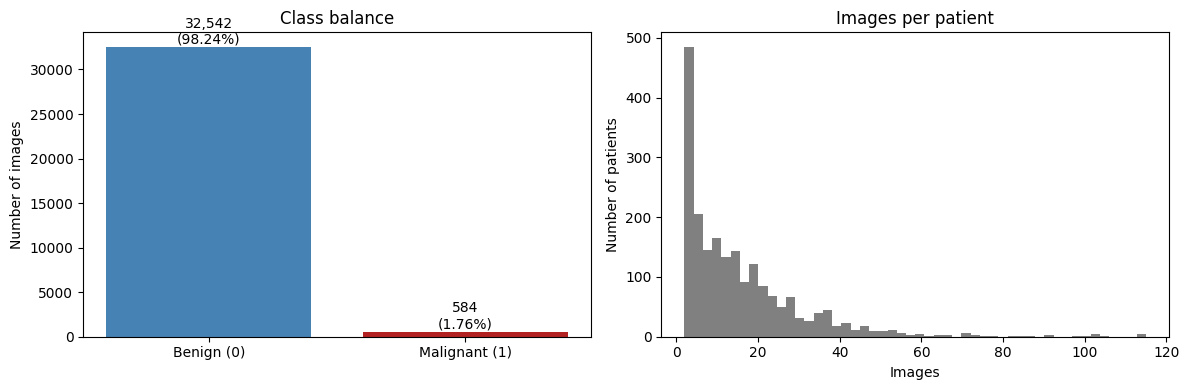

Patients: 2056
count    2056.000000
mean       16.111868
std        15.674491
min         2.000000
25%         5.000000
50%        12.000000
75%        22.000000
max       115.000000
dtype: float64

Patients with at least one malignant image: 428
Malignant images per such patient (describe):
count    428.000000
mean       1.364486
std        0.776017
min        1.000000
25%        1.000000
50%        1.000000
75%        2.000000
max        8.000000
dtype: float64


In [6]:
# class balance and images per patient
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Class balance
counts = df["target"].value_counts().sort_index()
ax[0].bar(["Benign (0)", "Malignant (1)"], counts.values, color=["steelblue", "firebrick"])
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}\n({v/len(df)*100:.2f}%)", ha="center", va="bottom")
ax[0].set_title("Class balance")
ax[0].set_ylabel("Number of images")

# Images per patient
per_patient = df.groupby("patient_id").size()
ax[1].hist(per_patient, bins=50, color="gray")
ax[1].set_title("Images per patient")
ax[1].set_xlabel("Images")
ax[1].set_ylabel("Number of patients")

plt.tight_layout()
plt.show()

print("Patients:", per_patient.shape[0])
print(per_patient.describe())

# Malignant images per patient
mal_per_patient = df[df["target"] == 1].groupby("patient_id").size()
print("\nPatients with at least one malignant image:", mal_per_patient.shape[0])
print("Malignant images per such patient (describe):")
print(mal_per_patient.describe())

### 3.1 Class balance and images per patient

**Results:**

- The dataset has 33,126 images: 32,542 benign (98.24%) and 584 malignant (1.76%). The classes are severely imbalanced.

- There are 2,056 patients, with a mean of 16.1 and a median of 12 images per patient (minimum 2, maximum 115). The distribution is right-skewed, with a few patients contributing over 100 images.

- 428 patients (about 21%) have at least one malignant image, with a mean of 1.36 malignant images per such patient (maximum 8).

**Interpretation:**

- A model that predicts "benign" for every image would reach 98.24% accuracy and detect no melanoma, so accuracy will not be used as a headline metric. We report recall, precision, PR-AUC, ROC-AUC and recall at fixed specificity, and test class weighting and resampling.

- Because each patient has many images, splitting by image would place the same patient's lesions in both training and test sets. The model could then recognise patient-specific features (skin tone, lighting, camera) instead of melanoma, which inflates test scores. All splits are therefore made at patient level.

- The malignant class is small and clustered in 428 patients, so the validation and test sets will contain few malignant cases and metrics will have wide uncertainty. This is a limitation that we have to note as we move on.

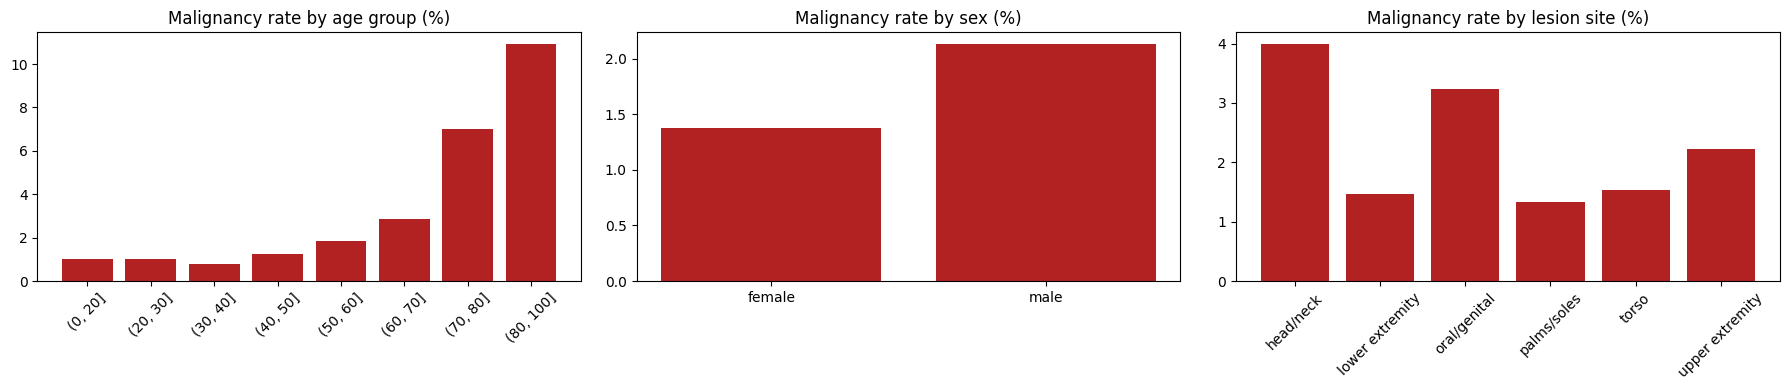

                                   mean  count
anatom_site_general_challenge                 
head/neck                      0.039892   1855
lower extremity                0.014732   8417
oral/genital                   0.032258    124
palms/soles                    0.013333    375
torso                          0.015257  16845
upper extremity                0.022276   4983
            mean  count
sex                    
female  0.013766  15981
male    0.021311  17080


In [7]:
# malignancy rate by age, sex, and site
fig, ax = plt.subplots(1, 3, figsize=(18, 4))

# Age groups
df["age_group"] = pd.cut(df["age_approx"], bins=[0, 20, 30, 40, 50, 60, 70, 80, 100])
g = df.groupby("age_group")["target"].agg(["mean", "count"])
ax[0].bar(g.index.astype(str), g["mean"] * 100, color="firebrick")
ax[0].set_title("Malignancy rate by age group (%)")
ax[0].tick_params(axis="x", rotation=45)

# Sex
g = df.groupby("sex")["target"].agg(["mean", "count"])
ax[1].bar(g.index, g["mean"] * 100, color="firebrick")
ax[1].set_title("Malignancy rate by sex (%)")

# Lesion site
g = df.groupby("anatom_site_general_challenge")["target"].agg(["mean", "count"])
ax[2].bar(g.index, g["mean"] * 100, color="firebrick")
ax[2].set_title("Malignancy rate by lesion site (%)")
ax[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(df.groupby("anatom_site_general_challenge")["target"].agg(["mean", "count"]))
print(df.groupby("sex")["target"].agg(["mean", "count"]))

### 3.2 Malignancy rate by age, sex and lesion site

**Results:**

- **Age:** the malignancy rate is about 1% up to age 50, then rises steadily: around 3% at 60-70, 7% at 70-80 and 11% at 80-100.

- **Sex:** 2.13% in males (17,080 images) versus 1.38% in females (15,981 images).

- **Site:** head/neck has the highest rate (3.99%, 1,855 images), followed by oral/genital (3.23%, but only 124 images), upper extremity (2.23%), torso (1.53%), lower extremity (1.47%) and palms/soles (1.33%).

**Interpretation:**

- Age shows the clearest signal, which aligns with clinical knowledge that melanoma risk increases with age and cumulative sun exposure. Sex and site show smaller differences. Together they suggest that clinical metadata carries information that images alone may not, which proves the need for the metadata-fusion experiments.

- The oral/genital rate comes from a very small group, so it is unstable and should not be over-interpreted.

- These are one-variable summaries. Age, sex and site are likely correlated (for example, head/neck lesions are more common in older patients), so each effect may partly reflect the others. Hence, we will need a multivariable model to separate them.

- These rates apply to this dataset only. ISIC 2020 is a curated collection, not a random population sample, so the 1.76% prevalence does not represent real-world prevalence.

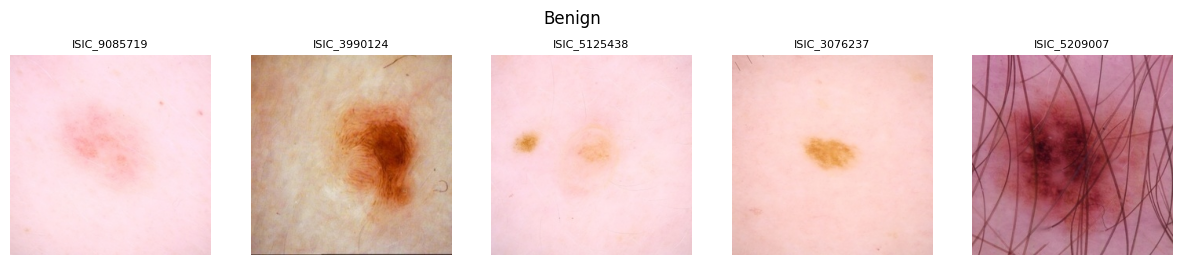

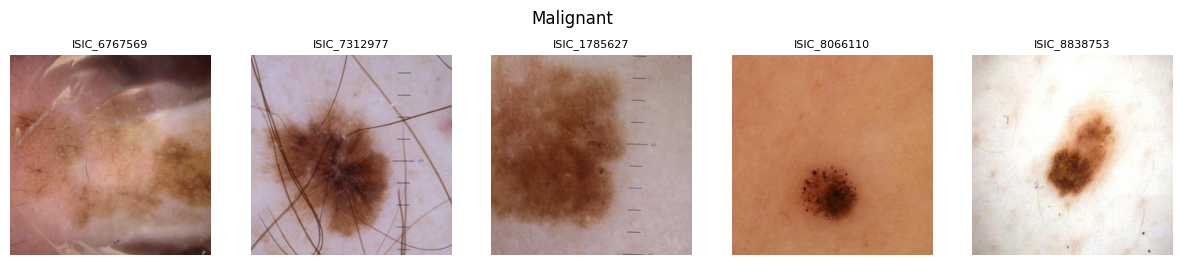

In [8]:
# sample images
from PIL import Image

img_dir = os.path.dirname(images[0])   # folder holding the .jpg files

def show_samples(label, n=5, title=""):
    rows = df[df["target"] == label].sample(n, random_state=SEED)
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    for a, (_, r) in zip(axes, rows.iterrows()):
        a.imshow(Image.open(f"{img_dir}/{r['isic_id']}.jpg"))
        a.set_title(r["isic_id"], fontsize=8)
        a.axis("off")
    fig.suptitle(title)
    plt.show()

show_samples(0, title="Benign")
show_samples(1, title="Malignant")

### 3.3 Sample images

**What the cell does:** displays five random benign and five random malignant lesions (fixed seed, so the same images appear on every run).

**Observations:**

- Benign lesions in this sample seem to be small, pale or light brown and low-contrast. Malignant lesions tend to be larger, darker, more irregular, and fill more of the frame.

- Artefacts unrelated to disease are present: hair, ruler markings, colour cast and dark vignetting. In this sample, rulers and vignetting appear only in the malignant row. Five images per class is too few to draw a conclusion, but it may hint to a possible shortcut.

- Some benign lesions are very faint, which means that any model needs sensitivity to subtle colour and texture differences.

**Implications for modelling:**

- If artefacts such as rulers are more common in one class, a CNN may learn them instead of the lesion. Augmentation helps, and the error analysis will check whether misclassified images share such artefacts.

- Handcrafted features need a lesion segmentation or at least a robust colour estimate, because hair and ruler pixels add noise.

- Images were resized to 256x256, so fine dermoscopic detail is reduced. This is noted as a limitation.

## 4. Patient-Level Train/Validation/Test Split

Each patient contributes many images (median 12, maximum 115), so splitting by image would put the same patient in both training and test sets and inflate results. We therefore split by `patient_id`, so every patient appears in exactly one subset.

**What the code does:**

1. Uses `StratifiedGroupKFold` with `patient_id` as the group. It keeps each patient's images together and keeps the malignant proportion similar across subsets.

2. Takes one fold as the test set (about 1/7 of the data), then takes one fold of the remainder as the validation set (about 1/7 of the data). The rest will be the training set (about 5/7).

3. Verifies that no patient appears in more than one subset.

4. Prints the image, patient and malignant counts per subset.

5. Saves the split to Drive so every later experiment uses identical data.

**Why this design:**

- The test set is used once, for final evaluation. The validation set is used for tuning and early stopping.

- Stratification matters because only 584 malignant images exist. A random group split could leave a subset with very few malignant cases.

- Exact 70/15/15 proportions are not guaranteed, because whole patients are assigned, not single images.

**Expected output:** zero patient overlap between subsets and a malignant rate of about 1.76% in each.

In [9]:
from sklearn.model_selection import StratifiedGroupKFold

# Split 1: hold out the test set (~1/7 of patients)
sgkf1 = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(sgkf1.split(df, df["target"], groups=df["patient_id"]))

trainval = df.iloc[trainval_idx]
test = df.iloc[test_idx]

# Split 2: take the validation set out of the remainder (~1/6 of it)
sgkf2 = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
train_idx, val_idx = next(sgkf2.split(trainval, trainval["target"], groups=trainval["patient_id"]))

train = trainval.iloc[train_idx]
val = trainval.iloc[val_idx]

# Label the subsets and save
df["split"] = "train"
df.loc[val.index, "split"] = "val"
df.loc[test.index, "split"] = "test"
df.to_csv(f"{BASE_DIR}/split_assignments.csv", index=False)

# Checks
P = {name: set(d["patient_id"]) for name, d in [("train", train), ("val", val), ("test", test)]}
print("Patient overlap train/val :", len(P["train"] & P["val"]))
print("Patient overlap train/test:", len(P["train"] & P["test"]))
print("Patient overlap val/test  :", len(P["val"] & P["test"]))

summary = df.groupby("split").agg(
    images=("target", "size"),
    patients=("patient_id", "nunique"),
    malignant=("target", "sum"),
    malignant_pct=("target", lambda s: round(s.mean() * 100, 2)),
)
summary["image_share_%"] = (summary["images"] / len(df) * 100).round(1)
print(summary.loc[["train", "val", "test"]])

Patient overlap train/val : 0
Patient overlap train/test: 0
Patient overlap val/test  : 0
       images  patients  malignant  malignant_pct  image_share_%
split                                                           
train   23885      1469        407           1.70           72.1
val      4709       293         72           1.53           14.2
test     4532       294        105           2.32           13.7


### 4.1 Split results

The split assigns 1,469 patients (23,885 images, 407 malignant) to training, 293 patients (4,709 images, 72 malignant) to validation and 294 patients (4,532 images, 105 malignant) to testing. No patient appears in more than one subset, which prevents patient-level leakage.

Because whole patients are assigned we cannot split the malignant images evenly perfectly, so the rates differ between subsets: 1.70% in training, 1.53% in validation and 2.32% in testing. So the split is only approximately balanced.

This has three consequences:
- First, PR-AUC: A model guessing at random scores a PR-AUC equal to the malignant rate. That is why we compare each PR-AUC to that subset’s rate (for example, 0.219 on test against 0.0232).

- Few malignant cases: With only 72 (validation) and 105 (test) malignant images, a metric like recall could change a lot if a few cases changed. That is why we report confidence intervals, from resampling whole patients 500 times.

- Threshold chosen on validation only: The cut-off for “flag this image as melanoma” was set on validation and then used unchanged on the test set. If we had tuned it on the test set, the test result would be too optimistic.

The split is saved in `split_assignments.csv` so every experiment uses identical data.

## 5. Clinical Metadata: Imputation and Encoding

Age, sex and lesion site have a few missing values (age 68, sex 65, site 527). This step fills them and converts the three variables to numbers that both scikit-learn and Keras models can use.

**What the code does:**

1. Computes the age median, mean and standard deviation from the **training set only**, so no information from validation or test leaks into preprocessing.

2. Fills missing age with the training median and adds an `age_missing` flag, since missingness itself may carry signal.

3. Fills missing sex and lesion site with an explicit `unknown` category, instead of guessing a value.

4. Standardises age and one-hot encodes sex and site with fixed category lists, so train, validation and test always have identical columns.

5. Checks that no unexpected categories exist, then saves the table to Drive.

**Why this design:**

- Imputing with training statistics only prevents data leakage.

- Dropping rows would lose malignant cases, and only 584 exist.

- The columns `diagnosis` and `benign_malignant` from the official CSV encode the label directly. They are deliberately excluded.

**Expected output:** 33,126 rows, no missing values, and 12 feature columns.

In [10]:
CAT_SEX  = ["female", "male", "unknown"]
CAT_SITE = ["head/neck", "lower extremity", "oral/genital",
            "palms/soles", "torso", "upper extremity", "unknown"]

# Sanity check: no categories outside the fixed lists
assert set(df["sex"].dropna()) <= set(CAT_SEX)
assert set(df["anatom_site_general_challenge"].dropna()) <= set(CAT_SITE)

# Statistics from the TRAINING set only
train_age  = df.loc[df["split"] == "train", "age_approx"]
age_median = train_age.median()
age_mean   = train_age.fillna(age_median).mean()
age_std    = train_age.fillna(age_median).std()
print(f"Train age median={age_median}, mean={age_mean:.2f}, std={age_std:.2f}")

def build_meta(d):
    out = pd.DataFrame(index=d.index)
    out["age_missing"] = d["age_approx"].isna().astype(int)
    out["age_scaled"]  = (d["age_approx"].fillna(age_median) - age_mean) / age_std
    sex  = pd.Series(pd.Categorical(d["sex"].fillna("unknown"), categories=CAT_SEX), index=d.index)
    site = pd.Series(pd.Categorical(d["anatom_site_general_challenge"].fillna("unknown"),
                                    categories=CAT_SITE), index=d.index)
    out = out.join(pd.get_dummies(sex, prefix="sex").astype(int))
    out = out.join(pd.get_dummies(site, prefix="site").astype(int))
    return out

meta_feats = build_meta(df)
meta_feats.insert(0, "isic_id", df["isic_id"])
meta_feats["patient_id"] = df["patient_id"]
meta_feats["split"]      = df["split"]
meta_feats["target"]     = df["target"]

meta_feats.to_parquet(f"{FEAT_DIR}/metadata_features.parquet", index=False)

feature_cols = [c for c in meta_feats.columns
                if c not in ["isic_id", "patient_id", "split", "target"]]
print("Rows:", len(meta_feats), "| Feature columns:", len(feature_cols))
print("Missing values:", meta_feats[feature_cols].isna().sum().sum())
print("Label-leaking columns present:",
      [c for c in feature_cols if c in ["diagnosis", "benign_malignant", "target"]])
print(meta_feats.groupby("split")[["age_scaled"]].agg(["mean", "std"]).round(2))

Train age median=50.0, mean=48.65, std=14.25
Rows: 33126 | Feature columns: 12
Missing values: 0
Label-leaking columns present: []
      age_scaled      
            mean   std
split                 
test        0.02  1.02
train      -0.00  1.00
val         0.09  1.03


### 5.1 Metadata preprocessing results

Imputation and scaling statistics were computed on the training set only (age median 50.0, mean 48.65, standard deviation 14.25) and applied unchanged to validation and test. The resulting table has 33,126 rows and 12 numeric feature columns (age missing flag, scaled age, three sex indicators and seven lesion-site indicators), with no missing values. The label-derived columns `diagnosis` and `benign_malignant` were excluded to prevent target leakage.

Scaled age has mean 0.00 and standard deviation 1.00 in training by construction. Validation (mean 0.09) and test (mean 0.02) differ slightly, which is expected because whole patients were assigned to subsets and the scaling was fitted on training data only. The shift is small compared with one standard deviation, so no correction is needed. The table is saved to Drive and reused by all metadata experiments.

## 6. Input Pipeline with tf.data

This section builds the data pipeline that feeds images (and optionally clinical metadata) to the Keras models.

**What the code does:**

1. Defines `load_image`, which reads a JPEG from local disk, resizes it to 224x224 and keeps pixel values in the 0-255 range. Each model applies its own preprocessing (for example, EfficientNet rescales inside the network), so the pipeline stays model-agnostic.

2. Defines `augment`, applied to **training images only**: random horizontal and vertical flips, random 90-degree rotations, and small brightness and contrast changes. Dermoscopic images have no natural orientation, so flips and rotations are label-preserving. Brightness and contrast changes reduce reliance on lighting and colour-cast shortcuts.

3. Defines `make_dataset`, which builds a `tf.data.Dataset` from a split. The training set is shuffled every epoch. Validation and test sets are never shuffled or augmented, so their order always matches the rows of the dataframe and predictions can be linked back to images for error analysis.

4. With `use_meta=True`, each batch is a dictionary with an `image` input and a `meta` input (the 12 metadata features), ready for the fusion model.

5. Uses parallel loading and `prefetch`, so the GPU does not wait for the CPU.
6. Checks one batch and previews augmentation on a single image.

**Design choices:**

- Images are **not cached in memory**: 33k images at 224x224x3 in float32 is about 20 GB, more than Colab provides. Reading from local disk with parallel decoding is fast enough.

- Class imbalance is handled in the model (class weights) and in later experiments (resampling), not in this pipeline.

**Expected output:** image batches of shape (64, 224, 224, 3), pixel values between 0 and 255, about one malignant label per batch of 64, and a figure showing one lesion under five random augmentations.

Image batch: (64, 224, 224, 3) <dtype: 'float32'>
Pixel range: 0.0 to 255.0
Malignant in this batch: 0 of 64
Fusion batch keys: ['image', 'meta'] | meta shape: (64, 12)
Val labels match dataframe: True


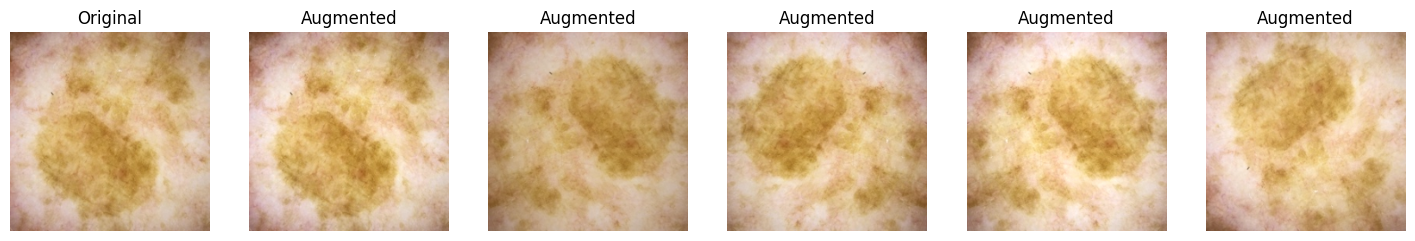

In [11]:
IMG_SIZE   = 224
BATCH_SIZE = 64
AUTOTUNE   = tf.data.AUTOTUNE
img_dir    = os.path.dirname(images[0])      # folder holding the .jpg files

def load_image(path):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return tf.cast(img, tf.float32)          # keep 0-255 range

def augment(img):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    img = tf.image.random_brightness(img, max_delta=20.0)      # 0-255 scale
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    return tf.clip_by_value(img, 0.0, 255.0)

def make_dataset(d, training=False, use_meta=False, batch_size=BATCH_SIZE):
    paths  = [f"{img_dir}/{i}.jpg" for i in d["isic_id"]]
    labels = d["target"].values.astype("float32")
    meta   = meta_feats.loc[d.index, feature_cols].values.astype("float32")

    ds = tf.data.Dataset.from_tensor_slices((paths, meta, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)

    def _parse(path, m, y):
        img = load_image(path)
        if training:
            img = augment(img)
        x = {"image": img, "meta": m} if use_meta else img
        return x, y

    ds = ds.map(_parse, num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

# Subsets (row order is preserved for val and test)
train_df = df[df["split"] == "train"]
val_df   = df[df["split"] == "val"]
test_df  = df[df["split"] == "test"]

train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df)
test_ds  = make_dataset(test_df)

# Check one training batch
x, y = next(iter(train_ds))
print("Image batch:", x.shape, x.dtype)
print("Pixel range: %.1f to %.1f" % (x.numpy().min(), x.numpy().max()))
print("Malignant in this batch:", int(y.numpy().sum()), "of", len(y))

# Check the metadata version and that val order matches the dataframe
xm, ym = next(iter(make_dataset(val_df, use_meta=True)))
print("Fusion batch keys:", list(xm.keys()), "| meta shape:", xm["meta"].shape)
print("Val labels match dataframe:",
      np.array_equal(ym.numpy(), val_df["target"].values[:len(ym)]))

# Preview augmentation on one malignant image
row = train_df[train_df["target"] == 1].iloc[0]
orig = load_image(f"{img_dir}/{row['isic_id']}.jpg")
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
axes[0].imshow(orig.numpy().astype("uint8")); axes[0].set_title("Original")
for a in axes[1:]:
    a.imshow(augment(orig).numpy().astype("uint8")); a.set_title("Augmented")
for a in axes: a.axis("off")
plt.show()

### 6.1 Pipeline verification

One training batch has shape (64, 224, 224, 3) with float32 pixel values from 0 to 255, so scaling is left to each model. The batch contained no malignant images, which is expected: with a malignant prevalence of 1.76%, a batch of 64 holds about one positive on average, and many batches hold none. This confirms that imbalance must be handled explicitly, through class weights or resampling, because otherwise most gradient updates would contain only benign examples.

The metadata version of the pipeline returns a dictionary with an image tensor and a 12-feature metadata tensor, which will feed the fusion model. Validation labels returned by the pipeline match the dataframe order, so predictions can be mapped back to individual images during error analysis.

The augmentation preview shows one malignant lesion under five random transformations. Flips, 90-degree rotations and small brightness and contrast changes keep the lesion intact, which is appropriate because dermoscopic images have no standard orientation. Augmentation is applied to the training set only.

## 7. Handcrafted Feature Extraction

Traditional models such as Logistic Regression, Random Forest and Gradient Boosting cannot learn from raw pixels efficiently, so each image is converted into a vector of numbers that describe the lesion, following the ABCD rule (Asymmetry, Border, Colour, Diameter/texture).

### 7.1 Feature definitions and segmentation check

**What the code does, per image:**

1. **Hair removal:** a black-hat morphological filter finds thin dark structures (hair), and inpainting fills them from surrounding pixels.

2. **Lesion segmentation:** Otsu thresholding on the blurred grayscale image, restricted to a central circular field to ignore the dark vignetting at the corners. Morphological opening, hole filling and keeping the largest connected region give the lesion mask. If the mask is implausible (under 2% or over 85% of the image), a central ellipse is used instead and the image is flagged (`seg_ok = 0`).

3. **Colour features:** RGB, HSV, Lab are three ways of describing colour with numbers. We used all three because each captures different things (brightness, shade, how vivid).
Mean and standard deviation: the average colour of the lesion, and how much the colour varies inside it. Melanomas often have several colours, so more variation is a warning sign.
Contrast with the skin: how different the lesion is from the skin around it. Lab colour distance is a single number for that difference

4. **Shape and asymmetry features:** Area fraction: what share of the image the lesion covers.
Compactness: how close the shape is to a circle. Irregular shapes score lower.
Solidity: how “filled in” the shape is. A shape with dents and bays scores lower.
Eccentricity and axis ratio: how stretched, or oval, the lesion is.
Extent: how much of its bounding box the lesion fills.
Asymmetry: we flip the mask like a mirror and measure how well it overlaps with itself. Perfect overlap means symmetric. We did this at six angles and kept the minimum, maximum and average.

5. **Border features:** We measured how sharply the colour changes along the lesion’s edge. A sudden, sharp edge is a warning sign, and a blurry edge is less so. Gradient means “how fast the brightness changes”..

6. **Texture features:** GLCM: counts how often pairs of neighbouring pixels have certain brightness combinations. The five numbers (contrast, dissimilarity, homogeneity, energy, correlation) describe how smooth or rough the surface looks.
LBP: compares each pixel to its neighbours and builds a histogram of the local patterns (10 bins). It is another description of texture and both were measured only inside the lesion.

**Why it is leakage-free:** every feature is computed from one image alone. Scaling is done later inside the model pipelines, fitted on training data only.

**Limitations:** Otsu segmentation is simple and will fail on pale or low-contrast lesions (the fallback flag counts these). Images are 224x224, so fine texture is reduced. The segmentation preview below checks that the masks are reasonable.

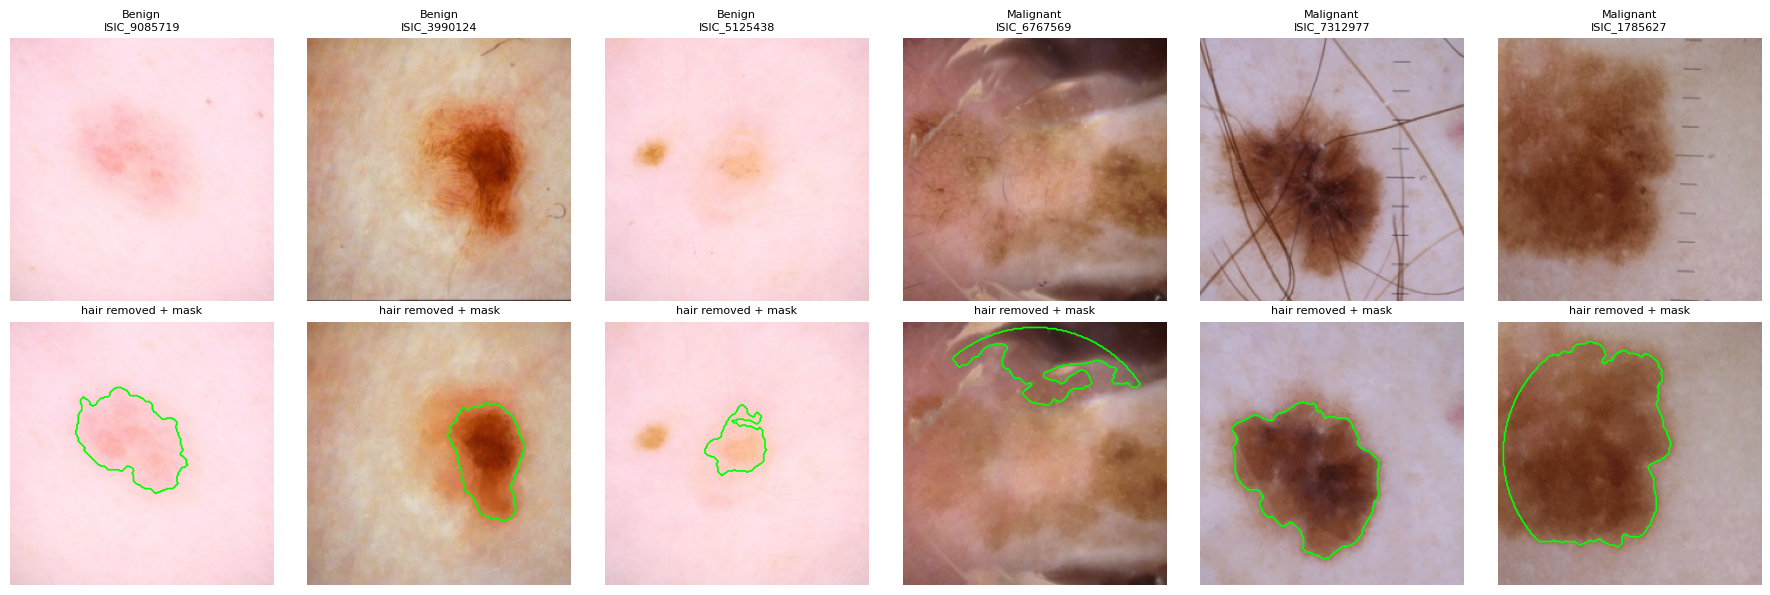

Feature columns: 48 (excluding seg_ok)
Segmentation OK rate: 0.85 | errors: 0
147 ms per image | CPU cores: 2 | estimated full run: 41 min
NaN values in sample: 0


In [12]:
# functions, preview, and timing
import cv2, time
from scipy import ndimage as ndi
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from skimage.measure import label, regionprops
from joblib import Parallel, delayed

FEAT_SIZE = 224
_yy, _xx = np.mgrid[:FEAT_SIZE, :FEAT_SIZE]
CIRCLE = (_yy - FEAT_SIZE/2)**2 + (_xx - FEAT_SIZE/2)**2 < (0.48 * FEAT_SIZE)**2
ELLIPSE = ((_yy - FEAT_SIZE/2) / (0.3 * FEAT_SIZE))**2 + ((_xx - FEAT_SIZE/2) / (0.3 * FEAT_SIZE))**2 < 1

def load_rgb(path):
    bgr = cv2.imread(path)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    return cv2.resize(rgb, (FEAT_SIZE, FEAT_SIZE), interpolation=cv2.INTER_AREA)

def remove_hair(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, hair = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    hair = cv2.dilate(hair, np.ones((3, 3), np.uint8))
    return cv2.inpaint(rgb, hair, 3, cv2.INPAINT_TELEA)

def segment(rgb):
    gray = cv2.GaussianBlur(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), (7, 7), 0)
    t, _ = cv2.threshold(gray[CIRCLE].reshape(-1, 1), 0, 255,
                         cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = (gray < t) & CIRCLE
    mask = ndi.binary_fill_holes(ndi.binary_opening(mask, iterations=2))
    lab = label(mask)
    if lab.max() > 0:
        sizes = np.bincount(lab.ravel()); sizes[0] = 0
        mask = lab == sizes.argmax()
        if 0.02 < mask.mean() < 0.85:
            p = regionprops(mask.astype(int))[0]
            if p.solidity > 0.6:           # reject crescent/fragmented masks
                return mask, True
    return ELLIPSE.copy(), False            # fallback

def extract_features(path):
    try:
        rgb  = remove_hair(load_rgb(path))
        mask, ok = segment(rgb)
        f = {"seg_ok": int(ok)}

        # Lesion and surrounding-skin region
        skin = ~ndi.binary_dilation(mask, iterations=5) & CIRCLE
        if skin.sum() < 100:
            skin = ~mask

        # Colour
        spaces = {"rgb": (rgb.astype(float), ["R", "G", "B"]),
                  "hsv": (cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV).astype(float), ["H", "S", "V"]),
                  "lab": (cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(float), ["L", "A", "Bl"])}
        lab_les, lab_skin = [], []
        for _, (img, names) in spaces.items():
            for i, n in enumerate(names):
                v = img[..., i][mask]
                f[f"{n}_mean"], f[f"{n}_std"] = v.mean(), v.std()
        for i, n in enumerate(["R", "G", "B"]):
            f[f"contrast_{n}"] = rgb[..., i][mask].mean() - rgb[..., i][skin].mean()
        lab_img = spaces["lab"][0]
        f["delta_E"] = np.sqrt(sum((lab_img[..., i][mask].mean() - lab_img[..., i][skin].mean())**2
                                   for i in range(3)))

        # Shape and asymmetry
        p = regionprops(mask.astype(int))[0]
        f["area_frac"]   = p.area / mask.size
        f["compactness"] = 4 * np.pi * p.area / (p.perimeter**2 + 1e-6)
        f["solidity"]    = p.solidity
        f["eccentricity"] = p.eccentricity
        f["extent"]      = p.extent
        f["axis_ratio"]  = p.major_axis_length / (p.minor_axis_length + 1e-6)

        cy, cx = p.centroid
        centred = ndi.shift(mask.astype(float), (FEAT_SIZE/2 - cy, FEAT_SIZE/2 - cx), order=0)
        asym = []
        for ang in range(0, 180, 30):
            r = ndi.rotate(centred, ang, reshape=False, order=0) > 0.5
            fl = np.fliplr(r)
            asym.append(1 - (r & fl).sum() / max((r | fl).sum(), 1))
        f["asym_min"], f["asym_max"], f["asym_mean"] = min(asym), max(asym), float(np.mean(asym))

        # Border sharpness
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0); gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1)
        grad = np.hypot(gx, gy)
        edge = mask & ~ndi.binary_erosion(mask)
        f["border_grad_mean"], f["border_grad_std"] = grad[edge].mean(), grad[edge].std()

        # Texture: GLCM inside the lesion bounding box (background filled with lesion mean)
        ys, xs = np.where(mask)
        gc = gray[ys.min():ys.max()+1, xs.min():xs.max()+1].astype(float)
        mc = mask[ys.min():ys.max()+1, xs.min():xs.max()+1]
        gc = np.where(mc, gc, gc[mc].mean())
        q = (gc // 8).astype(np.uint8)                 # 32 grey levels
        glcm = graycomatrix(q, [1, 3], [0, np.pi/4, np.pi/2, 3*np.pi/4],
                            levels=32, symmetric=True, normed=True)
        for prop in ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]:
            f[f"glcm_{prop}"] = graycoprops(glcm, prop).mean()

        # Texture: uniform LBP histogram inside the lesion
        lbp = local_binary_pattern(gray, 8, 1, "uniform")
        hist = np.bincount(lbp[mask].astype(int), minlength=10)[:10] / mask.sum()
        for i, h in enumerate(hist):
            f[f"lbp_{i}"] = h
        return f
    except Exception:
        return {"seg_ok": -1}

# Segmentation preview: 3 benign + 3 malignant
ids = (list(df[df.target == 0].sample(3, random_state=SEED)["isic_id"]) +
       list(df[df.target == 1].sample(3, random_state=SEED)["isic_id"]))
fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for j, i in enumerate(ids):
    rgb = load_rgb(f"{img_dir}/{i}.jpg"); clean = remove_hair(rgb); mask, ok = segment(clean)
    axes[0, j].imshow(rgb);   axes[0, j].set_title(("Benign" if j < 3 else "Malignant") + f"\n{i}", fontsize=8)
    axes[1, j].imshow(clean); axes[1, j].contour(mask, colors="lime", linewidths=1.2)
    axes[1, j].set_title("hair removed + mask" + ("" if ok else " (FALLBACK)"), fontsize=8)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

# Timing on 60 random images
sample = df.sample(60, random_state=SEED)
t0 = time.time()
rows = [extract_features(f"{img_dir}/{i}.jpg") for i in sample["isic_id"]]
per_img = (time.time() - t0) / 60
test_feats = pd.DataFrame(rows)
print("Feature columns:", test_feats.shape[1] - 1, "(excluding seg_ok)")
print("Segmentation OK rate:", test_feats["seg_ok"].eq(1).mean().round(2),
      "| errors:", test_feats["seg_ok"].eq(-1).sum())
print(f"{per_img*1000:.0f} ms per image | CPU cores: {os.cpu_count()} | "
      f"estimated full run: {per_img*len(df)/60/os.cpu_count():.0f} min")
print("NaN values in sample:", int(test_feats.drop(columns='seg_ok').isna().sum().sum()))

### 7.2 Segmentation preview and timing

**What the cell does:** defines the feature-extraction functions, outlines the lesion on six example images (three benign, three malignant) with a green contour, and times the extraction on 60 random images.

**Results:** 48 features were extracted per image with no errors and no missing values, at about 68 ms per image (about 19 minutes for the full dataset on 2 cores). Most outlines follow the lesion well. One malignant image (ISIC_6767569) was segmented as a crescent along the dark vignette at the image edge instead of the lesion. One large lesion (ISIC_1785627) is cut by the circular field of view.

**Interpretation:** simple threshold-based segmentation can fail on images with dark corners or very large lesions. Features computed from a wrong mask (colour, shape, asymmetry, border) are noisy for those images. The next cells measure how common such failures are and whether they differ between classes.

In [13]:
chk = pd.concat([df[df.target == 0].sample(150, random_state=SEED),
                 df[df.target == 1].sample(100, random_state=SEED)])
chk_feats = pd.DataFrame([extract_features(f"{img_dir}/{i}.jpg") for i in chk["isic_id"]])
chk_feats["target"] = chk["target"].values
print("Fallback rate by class:")
print(chk_feats.groupby("target")["seg_ok"].apply(lambda s: (s == 0).mean()).round(3))
print("Errors:", (chk_feats["seg_ok"] == -1).sum())

Fallback rate by class:
target
0    0.12
1    0.09
Name: seg_ok, dtype: float64
Errors: 0


### 7.3 Fallback rate by class

**What the cell does:** runs the extraction on 150 benign and 100 malignant images and reports how often the mask was rejected and replaced by a central ellipse (the fallback, `seg_ok = 0`). A mask is rejected if it is too small, too large, or has solidity below the threshold (0.6, chosen in 7.4).

**Results:** the fallback rate was 12% for benign and 9% for malignant images, with no extraction errors.

**Interpretation:** the rates are similar across classes, so the fallback flag is unlikely to leak the label. It is still excluded from the model inputs and used only in the error analysis. For fallback images, shape and border features are not meaningful, which is a limitation.

In [14]:
def raw_solidity(path):
    rgb = remove_hair(load_rgb(path))
    gray = cv2.GaussianBlur(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), (7, 7), 0)
    t, _ = cv2.threshold(gray[CIRCLE].reshape(-1, 1), 0, 255,
                         cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = ndi.binary_fill_holes(ndi.binary_opening((gray < t) & CIRCLE, iterations=2))
    lab = label(mask)
    if lab.max() == 0:
        return np.nan, np.nan
    sizes = np.bincount(lab.ravel()); sizes[0] = 0
    mask = lab == sizes.argmax()
    return regionprops(mask.astype(int))[0].solidity, mask.mean()

diag = pd.concat([df[df.target == 0].sample(150, random_state=SEED),
                  df[df.target == 1].sample(100, random_state=SEED)])
res = [raw_solidity(f"{img_dir}/{i}.jpg") for i in diag["isic_id"]]
diag["solidity"] = [r[0] for r in res]
diag["area"] = [r[1] for r in res]

print(diag.groupby("target")["solidity"].describe().round(2))
for th in [0.5, 0.6, 0.7, 0.75]:
    print(f"threshold {th}:", diag.groupby("target")["solidity"]
          .apply(lambda s: (s < th).mean()).round(3).to_dict())

        count  mean   std   min   25%   50%   75%   max
target                                                 
0       150.0  0.86  0.17  0.25  0.87  0.93  0.95  0.99
1       100.0  0.81  0.15  0.32  0.73  0.87  0.93  0.98
threshold 0.5: {0: 0.08, 1: 0.06}
threshold 0.6: {0: 0.1, 1: 0.09}
threshold 0.7: {0: 0.133, 1: 0.2}
threshold 0.75: {0: 0.16, 1: 0.29}


### 7.4 Choosing the solidity threshold

**What the cell does:** computes the solidity of the raw mask (area divided by the area of its convex hull; 1 = perfectly compact, low = fragmented or crescent-shaped) for 150 benign and 100 malignant images, and shows how many would be rejected at different thresholds.

**Results:** malignant lesions had lower solidity than benign ones (median 0.87 vs. 0.93; 25th percentile 0.73 vs. 0.87). A threshold of 0.75 rejected 29% of malignant and 16% of benign images. A threshold of 0.6 rejected 9% and 10%.

**Interpretation:** irregular borders are a malignancy cue, so a strict threshold removes exactly the lesions we need to measure and creates a class imbalance in the features. The threshold of 0.6 was chosen because it removes badly broken masks while treating both classes about equally. The initial guess of 0.75 was therefore replaced by a data-driven value.

In [15]:
dist = np.sqrt((_yy - FEAT_SIZE/2)**2 + (_xx - FEAT_SIZE/2)**2)
OUTER = dist > 0.30 * FEAT_SIZE          # outer ring of the circular field

def ring_fraction(path):
    rgb = remove_hair(load_rgb(path))
    gray = cv2.GaussianBlur(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), (7, 7), 0)
    t, _ = cv2.threshold(gray[CIRCLE].reshape(-1, 1), 0, 255,
                         cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = ndi.binary_fill_holes(ndi.binary_opening((gray < t) & CIRCLE, iterations=2))
    lab = label(mask)
    if lab.max() == 0:
        return np.nan
    sizes = np.bincount(lab.ravel()); sizes[0] = 0
    mask = lab == sizes.argmax()
    return (mask & OUTER).sum() / mask.sum()

print("Crescent image ISIC_6767569:", round(ring_fraction(f"{img_dir}/ISIC_6767569.jpg"), 2))
diag["ring"] = [ring_fraction(f"{img_dir}/{i}.jpg") for i in diag["isic_id"]]
print(diag.groupby("target")["ring"].describe().round(2))
for th in [0.6, 0.7, 0.8, 0.9]:
    print(f"ring fraction > {th}:",
          diag.groupby("target")["ring"].apply(lambda s: (s > th).mean()).round(3).to_dict())

Crescent image ISIC_6767569: 0.83
        count  mean   std  min   25%   50%   75%  max
target                                               
0       150.0  0.27  0.35  0.0  0.00  0.09  0.44  1.0
1       100.0  0.37  0.29  0.0  0.15  0.35  0.53  1.0
ring fraction > 0.6: {0: 0.187, 1: 0.16}
ring fraction > 0.7: {0: 0.16, 1: 0.13}
ring fraction > 0.8: {0: 0.153, 1: 0.12}
ring fraction > 0.9: {0: 0.12, 1: 0.09}


### 7.5 Mask-position check (evaluated, not adopted)

**What the cell does:** measures the fraction of each mask that lies in the outer ring of the field of view, to catch crescent masks along the vignette.

**Results:** the crescent image (ISIC_6767569) scored 0.83. A cut-off of 0.8 would also reject 15.3% of benign and 12.0% of malignant images.

**Interpretation:** the rule discards many genuine lesions (large or off-centre) to fix a rare failure, so it was not adopted. Vignette-type errors remain and add noise to the handcrafted features of the affected images. The CNN is not affected, because it uses the whole image. The error analysis checks whether misclassified images show segmentation failures.

### 7.6 Full Feature Extraction

**What the code does:**

1. Runs `extract_features` on all 33,126 images in parallel on both CPU cores (`joblib`).

2. Works in chunks of 2,000 images and saves each chunk to Drive as a parquet file. If Colab disconnects, re-running the cell skips chunks that already exist and continues where it stopped.

3. Combines all chunks, attaches `isic_id`, `patient_id`, `split` and `target`, and saves one table, `handcrafted_features.parquet`.

4. Reports how many images failed or used the fallback mask, overall and per class.

**Expected output:** 33,126 rows, 48 feature columns plus `seg_ok`, 0 extraction errors, fallback rates close to 12% (benign) and 9% (malignant), and a runtime of roughly 20 minutes.

**Note:** `seg_ok` is saved for the error analysis only and is never used as a model input. Imputation and scaling are done later inside the model pipelines, fitted on training data only.

In [16]:
CHUNK = 2000
CHUNK_DIR = f"{FEAT_DIR}/chunks"
os.makedirs(CHUNK_DIR, exist_ok=True)

ids = df["isic_id"].tolist()
t0 = time.time()

for start in range(0, len(ids), CHUNK):
    out = f"{CHUNK_DIR}/chunk_{start:06d}.parquet"
    if os.path.exists(out):
        continue                                   # already done, skip
    batch = ids[start:start + CHUNK]
    rows = Parallel(n_jobs=-1)(
        delayed(extract_features)(f"{img_dir}/{i}.jpg") for i in batch)
    chunk_df = pd.DataFrame(rows)
    chunk_df.insert(0, "isic_id", batch)
    chunk_df.to_parquet(out, index=False)
    print(f"Saved {start + len(batch):>6} / {len(ids)}  "
          f"({(time.time() - t0) / 60:.1f} min elapsed)")

# Combine
files = sorted(glob.glob(f"{CHUNK_DIR}/chunk_*.parquet"))
feats = pd.concat([pd.read_parquet(f) for f in files], ignore_index=True)
feats = feats.merge(df[["isic_id", "patient_id", "split", "target"]], on="isic_id")
feats.to_parquet(f"{FEAT_DIR}/handcrafted_features.parquet", index=False)

# Checks
hc_cols = [c for c in feats.columns
           if c not in ["isic_id", "patient_id", "split", "target", "seg_ok"]]
print("\nRows:", len(feats), "| Handcrafted feature columns:", len(hc_cols))
print("Extraction errors (seg_ok = -1):", (feats["seg_ok"] == -1).sum())
print("NaN in feature columns:", int(feats[hc_cols].isna().sum().sum()))
print("Fallback rate by class:")
print(feats.groupby("target")["seg_ok"].apply(lambda s: (s == 0).mean()).round(3))
print(feats.groupby("split").size())


Rows: 33126 | Handcrafted feature columns: 48
Extraction errors (seg_ok = -1): 0
NaN in feature columns: 0
Fallback rate by class:
target
0    0.133
1    0.089
Name: seg_ok, dtype: float64
split
test      4532
train    23885
val       4709
dtype: int64


### 7.7 Extraction results

Handcrafted features were extracted for all 33,126 images, producing 48 features per image (colour statistics in RGB, HSV and Lab, lesion-to-skin colour contrast, shape and asymmetry measures, border gradient, GLCM and LBP texture) plus a segmentation flag. There were no extraction errors and no missing values. The central-ellipse fallback was used for 13.3% of benign and 8.9% of malignant images. Because the rates differ slightly, the flag is excluded from model inputs and used only in error analysis. For fallback images, shape and border features describe the ellipse and not the lesion, which adds noise. The feature table is saved to Drive and reused by all traditional ML experiments. Scaling and any remaining imputation are done inside each model pipeline and fitted on training data only.

## 8. Evaluation Framework and Experiment 1

### 8.1 Evaluation helpers

Accuracy is meaningless at 1.76% prevalence, so every experiment is scored with the same metrics, which reflect the clinical priority that a missed melanoma is worse than a false alarm.

**What the code does:**

1. `compute_metrics` returns ROC-AUC, PR-AUC and recall at a fixed specificity of 90%. The decision threshold is set so that 90% of benign images are classified correctly, and recall is the share of malignant images that score above it. When a threshold is passed in (from validation), it is applied unchanged, which is how the test set will be scored.

2. `patient_bootstrap` resamples whole patients with replacement to give 95% confidence intervals. Resampling patients, not images, respects the fact that images from one patient are correlated, so the intervals are not too narrow.

3. `log_result` stores each experiment (model, settings, split, metrics,
interval, observations) in a results table saved to Drive, and writes the run to Weights & Biases in offline mode so the table is traceable to logged runs.

**Reading the metrics:** PR-AUC should be judged against prevalence, because a random classifier scores about 0.017. ROC-AUC is less sensitive to imbalance but can look good even when precision is poor. Recall at 90% specificity is the most clinically readable number.

In [17]:
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import wandb

os.environ["WANDB_MODE"] = "offline"

def compute_metrics(y, s, thr=None, spec=0.90):
    y, s = np.asarray(y), np.asarray(s)
    if thr is None:
        thr = np.quantile(s[y == 0], spec)        # 90% of benign score <= thr
    pred = s > thr
    return {"roc_auc": roc_auc_score(y, s),
            "pr_auc": average_precision_score(y, s),
            "recall_at_spec": pred[y == 1].mean(),
            "specificity": 1 - pred[y == 0].mean(),
            "threshold": thr}

def patient_bootstrap(y, s, groups, thr=None, n_boot=500, seed=SEED):
    y, s, groups = np.asarray(y), np.asarray(s), np.asarray(groups)
    rng = np.random.default_rng(seed)
    idx_by_pat = [np.where(groups == g)[0] for g in np.unique(groups)]
    out = {"roc_auc": [], "pr_auc": [], "recall_at_spec": []}
    for _ in range(n_boot):
        pick = rng.integers(0, len(idx_by_pat), len(idx_by_pat))
        idx = np.concatenate([idx_by_pat[i] for i in pick])
        if y[idx].sum() == 0:
            continue
        m = compute_metrics(y[idx], s[idx], thr)
        for k in out:
            out[k].append(m[k])
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in out.items()}

# Start from the saved results (if any), so a rerun never wipes earlier experiments
RES_PATH = f"{BASE_DIR}/results_table.csv"
RESULTS = pd.read_csv(RES_PATH).to_dict("records") if os.path.exists(RES_PATH) else []

def log_result(exp, name, family, settings, split, m, ci, notes=""):
    row = {"exp": exp, "model": name, "family": family, "settings": json.dumps(settings, default=str),
           "split": split, "roc_auc": round(m["roc_auc"], 3), "pr_auc": round(m["pr_auc"], 3),
           "recall@90spec": round(m["recall_at_spec"], 3),
           "roc_auc_ci": tuple(np.round(ci["roc_auc"], 3)),
           "pr_auc_ci": tuple(np.round(ci["pr_auc"], 3)),
           "recall_ci": tuple(np.round(ci["recall_at_spec"], 3)),
           "notes": notes}
    RESULTS[:] = [r for r in RESULTS if r.get("exp") != exp]   # replace the old row, never duplicate
    RESULTS.append(row)
    pd.DataFrame(RESULTS).to_csv(RES_PATH, index=False)
    try:
        run = wandb.init(project="melanoma-isic2020", name=f"{exp}-{name}", dir=LOG_DIR,
                         config={**settings, "family": family, "split": split},
                         mode="offline", reinit=True)
        wandb.log({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec"]})
        run.finish()
    except Exception as e:
        print("W&B logging skipped:", e)
    return row

print("Helpers ready. Results loaded:", len(RESULTS), "rows ->", [r["exp"] for r in RESULTS])

Helpers ready. Results loaded: 14 rows -> ['E1', 'E2a', 'E2b', 'E3', 'E4', 'E6A', 'E7a', 'E7b', 'T-E4', 'T-E8', 'T-E9', 'E8', 'E9', 'E5']


### 8.2 Experiment 1: Logistic Regression on handcrafted features (baseline)

**Purpose:** establish the simplest reasonable baseline. A linear model on the 48 ABCD-style features shows how much signal the handcrafted features carry before any imbalance handling or more flexible models.

**What the code does:**

1. Loads the saved handcrafted features and selects the 48 feature columns (`seg_ok` is excluded, as decided in Step 7).

2. Builds a pipeline of median imputation, standardisation and Logistic Regression. Because the pipeline is fitted on the training set only, scaling statistics never see validation or test data.

3. Tries five values of the regularisation strength C (0.001 to 10) and compares them on the **validation** set. Smaller C means stronger regularisation.

4. Keeps the C with the best validation PR-AUC, computes patient-level bootstrap intervals, and logs the run.

**Setup:** no class weights and no resampling, so this baseline shows what imbalance does when left untreated. Experiment 3 compares class weights and resampling against it.

In [18]:
feats = pd.read_parquet(f"{FEAT_DIR}/handcrafted_features.parquet")
hc_cols = [c for c in feats.columns if c not in ["isic_id", "patient_id", "split", "target", "seg_ok"]]

tr, va = feats[feats.split == "train"], feats[feats.split == "val"]
Xtr, ytr = tr[hc_cols], tr["target"].values
Xva, yva, gva = va[hc_cols], va["target"].values, va["patient_id"].values
print("Features:", len(hc_cols), "| train", Xtr.shape, "| val", Xva.shape)
print("Val prevalence (random-classifier PR-AUC): %.4f" % yva.mean())

def make_lr(C):
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("sc", StandardScaler()),
                     ("clf", LogisticRegression(C=C, max_iter=2000, random_state=SEED))])

sweep = []
for C in [0.001, 0.01, 0.1, 1, 10]:
    model = make_lr(C).fit(Xtr, ytr)
    m = compute_metrics(yva, model.predict_proba(Xva)[:, 1])
    sweep.append({"C": C, **{k: round(v, 3) for k, v in m.items() if k != "threshold"}})
sweep = pd.DataFrame(sweep)
print(sweep)

best_C = sweep.loc[sweep["pr_auc"].idxmax(), "C"]
print("\nBest C by validation PR-AUC:", best_C)

best = make_lr(best_C).fit(Xtr, ytr)
s_va = best.predict_proba(Xva)[:, 1]
m = compute_metrics(yva, s_va)
ci = patient_bootstrap(yva, s_va, gva)
row = log_result("E1", "LogReg", "traditional", {"C": best_C, "features": "handcrafted(48)",
                 "class_weight": None, "imputer": "median", "scaler": "standard"},
                 "val", m, ci, "Baseline, no imbalance handling")
print({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec", "roc_auc_ci", "pr_auc_ci", "recall_ci"]})

Features: 48 | train (23885, 48) | val (4709, 48)
Val prevalence (random-classifier PR-AUC): 0.0153
        C  roc_auc  pr_auc  recall_at_spec  specificity
0   0.001    0.807   0.079           0.361          0.9
1   0.010    0.840   0.092           0.569          0.9
2   0.100    0.849   0.101           0.556          0.9
3   1.000    0.850   0.101           0.556          0.9
4  10.000    0.850   0.101           0.556          0.9

Best C by validation PR-AUC: 0.1


wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.101
recall@90spec,0.556
roc_auc,0.849


{'roc_auc': np.float64(0.849), 'pr_auc': np.float64(0.101), 'recall@90spec': np.float64(0.556), 'roc_auc_ci': (np.float64(0.8), np.float64(0.89)), 'pr_auc_ci': (np.float64(0.06), np.float64(0.187)), 'recall_ci': (np.float64(0.413), np.float64(0.65))}


### 8.3 Experiment 1 results

The Logistic Regression baseline on 48 handcrafted features reached a validation ROC-AUC of 0.849 (95% patient-level bootstrap CI 0.80 to 0.89), a PR-AUC of 0.101 (0.06 to 0.19) and a recall of 0.556 (0.41 to 0.65) at 90% specificity. With a validation prevalence of 1.53%, a random classifier would have a PR-AUC of about 0.015, so the model carries real signal, but precision remains low: at the 90% specificity operating point, most flagged lesions are benign.

Regularisation strength had little effect once C reached 0.1, where results plateaued (ROC-AUC 0.849 to 0.850, identical PR-AUC), while C = 0.001 underfitted (recall 0.361), indicating that the features are informative and a linear boundary is not heavily over-parameterised. C = 0.1 was selected as the most regularised value among the tied best.

The confidence intervals are wide because the validation set contains only 72 malignant images, so small differences between later experiments will not be interpreted as improvements unless they exceed this uncertainty. This baseline uses no imbalance handling; Experiment 3 compares class weights and resampling against it.


NOTE TO SELF: A high ROC-AUC with a low PR-AUC is expected under heavy imbalance, because ROC-AUC counts all the benign images as easy negatives, while PR-AUC punishes every false alarm.

Recall at 90% specificity means the model’s threshold is set so that only 10% of benign images get flagged. If you tried to catch more melanomas, you’d flag more benign lesions.

### 8.4 Experiment 2: Random Forest and Gradient Boosting (non-linear models)

**Purpose:** test whether non-linear models extract more from the same 48 handcrafted features than the linear baseline. Interactions such as "large AND asymmetric AND dark" cannot be represented by Logistic Regression but can be learned by tree ensembles.

**What the code does:**

1. Uses the same training and validation sets and the same features as Experiment 1, so any difference comes from the model.

2. Tries a small grid for each model, chosen to control overfitting on only 407 malignant training images:
   - Random Forest: number of trees, `max_depth` and `min_samples_leaf`.

   - Histogram Gradient Boosting: learning rate, `max_depth` and
   `l2_regularization`, with early stopping on an internal slice of the training data (not the validation set).

3. Scores every configuration on the **validation** set and keeps the best one per model by PR-AUC.

4. Computes patient-level bootstrap intervals for each best model and logs both runs.

**Setup:** still no class weights or resampling, so results compare directly with Experiment 1. Tree models need no scaling, and `HistGradientBoosting` handles missing values natively; the Random Forest uses median imputation.

**Why these choices:** with so few positives, deep trees memorise individual lesions. Shallow depth and larger leaves are therefore explored, and the train-versus-validation gap is printed to diagnose overfitting.

In [19]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from itertools import product

def run_grid(make_model, grid, name):
    rows, keys = [], list(grid.keys())
    best_pr, best_mdl, best_params = -1, None, None
    for vals in product(*grid.values()):
        params = dict(zip(keys, vals))
        t0 = time.time()
        mdl = make_model(**params).fit(Xtr, ytr)
        s_tr = mdl.predict_proba(Xtr)[:, 1]
        m_va = compute_metrics(yva, mdl.predict_proba(Xva)[:, 1])
        rows.append({**params,
                     "train_roc": round(roc_auc_score(ytr, s_tr), 3),
                     "val_roc": round(m_va["roc_auc"], 3),
                     "val_pr": round(m_va["pr_auc"], 3),
                     "val_recall": round(m_va["recall_at_spec"], 3),
                     "sec": round(time.time() - t0)})
        if m_va["pr_auc"] > best_pr:
            best_pr, best_mdl, best_params = m_va["pr_auc"], mdl, params
    print(f"\n{name} grid:\n", pd.DataFrame(rows).to_string(index=False))
    return best_mdl, best_params

# Random Forest
def make_rf(n_estimators, max_depth, min_samples_leaf):
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("clf", RandomForestClassifier(
                         n_estimators=n_estimators, max_depth=max_depth,
                         min_samples_leaf=min_samples_leaf, n_jobs=-1,
                         random_state=SEED))])

rf_grid = {"n_estimators": [300], "max_depth": [6, 12, None], "min_samples_leaf": [5, 20]}
best_rf, rf_params = run_grid(make_rf, rf_grid, "Random Forest")

# Histogram Gradient Boosting
def make_hgb(learning_rate, max_depth, l2_regularization):
    return HistGradientBoostingClassifier(
        learning_rate=learning_rate, max_depth=max_depth,
        l2_regularization=l2_regularization, max_iter=500,
        early_stopping=True, validation_fraction=0.15, n_iter_no_change=20,
        random_state=SEED)

hgb_grid = {"learning_rate": [0.03, 0.1], "max_depth": [3, 6], "l2_regularization": [0.0, 10.0]}
best_hgb, hgb_params = run_grid(make_hgb, hgb_grid, "Gradient Boosting")

# Log best of each
for tag, name, mdl, params in [("E2a", "RandomForest", best_rf, rf_params),
                               ("E2b", "HistGradBoost", best_hgb, hgb_params)]:
    s = mdl.predict_proba(Xva)[:, 1]
    m = compute_metrics(yva, s)
    ci = patient_bootstrap(yva, s, gva)
    row = log_result(tag, name, "traditional",
                     {**params, "features": "handcrafted(48)", "class_weight": None},
                     "val", m, ci, "Non-linear, no imbalance handling")
    print(tag, name, {k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec",
                                           "roc_auc_ci", "pr_auc_ci", "recall_ci"]})


Random Forest grid:
  n_estimators  max_depth  min_samples_leaf  train_roc  val_roc  val_pr  val_recall  sec
          300        6.0                 5      0.944    0.840   0.086       0.542   21
          300        6.0                20      0.933    0.844   0.096       0.569   25
          300       12.0                 5      0.997    0.854   0.095       0.556   34
          300       12.0                20      0.986    0.849   0.095       0.569   31
          300        NaN                 5      1.000    0.844   0.094       0.569   37
          300        NaN                20      0.992    0.849   0.099       0.583   32

Gradient Boosting grid:
  learning_rate  max_depth  l2_regularization  train_roc  val_roc  val_pr  val_recall  sec
          0.03          3                0.0      0.938    0.858   0.128       0.583    2
          0.03          3               10.0      0.932    0.860   0.107       0.597    2
          0.03          6                0.0      0.971    0.854  

pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.099
recall@90spec,0.583
roc_auc,0.849


E2a RandomForest {'roc_auc': np.float64(0.849), 'pr_auc': np.float64(0.099), 'recall@90spec': np.float64(0.583), 'roc_auc_ci': (np.float64(0.803), np.float64(0.889)), 'pr_auc_ci': (np.float64(0.063), np.float64(0.159)), 'recall_ci': (np.float64(0.476), np.float64(0.7))}


pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.128
recall@90spec,0.583
roc_auc,0.858


E2b HistGradBoost {'roc_auc': np.float64(0.858), 'pr_auc': np.float64(0.128), 'recall@90spec': np.float64(0.583), 'roc_auc_ci': (np.float64(0.818), np.float64(0.895)), 'pr_auc_ci': (np.float64(0.078), np.float64(0.205)), 'recall_ci': (np.float64(0.464), np.float64(0.703))}


### 8.5 Experiment 2 results

Random Forest and Histogram Gradient Boosting were tuned on small grids and scored on the validation set. The best Random Forest (unlimited depth, minimum leaf size 20) reached ROC-AUC 0.849 (95% CI 0.80 to 0.89), PR-AUC 0.099 (0.06 to 0.16) and recall 0.583 (0.48 to 0.70) at 90% specificity. The best Gradient Boosting model reached ROC-AUC 0.858 (0.82 to 0.90), PR-AUC 0.128 (0.08 to 0.21) and recall 0.583 (0.46 to 0.70). Both are comparable to the Logistic Regression baseline (0.849, 0.101, 0.556), and all confidence intervals overlap, so the non-linear models are not shown to be better.

The Random Forest grid shows high variance: deeper trees with small leaves reached a training ROC-AUC of 0.997 to 1.000 while validation ROC-AUC stayed between 0.84 and 0.85. All eight Gradient Boosting configurations fell within a narrow band (validation ROC-AUC 0.851 to 0.860, PR-AUC 0.100 to 0.128, recall 0.54 to 0.61). Depth-3 trees had a training ROC-AUC of about 0.93 to 0.95 against about 0.97 for depth-6 trees, with no validation benefit from the extra depth, so the shallower models were preferable. L2 regularisation had no consistent effect: it lowered PR-AUC at learning rate 0.03 and raised it slightly at 0.10. Because the best configuration was selected from near-tied candidates on a validation set with 72 malignant images, its PR-AUC of 0.128 is likely an optimistic estimate.

Because three different model families reach similar performance, the handcrafted features, together with the noise from simple threshold segmentation, appear to limit performance more than model flexibility. This motivates the deep learning experiments, which learn features directly from the pixels. Imbalance handling has not yet been applied; it is tested in Experiment 3.

### 8.6 Experiment 3: Imbalance handling

**Purpose:** test whether correcting the 1.7% class imbalance improves detection of malignant lesions, and compare three strategies under identical conditions.

**What the code does:**

1. Fixes the model to the best Gradient Boosting setting from Experiment 2 (learning rate 0.03, depth 3, no L2), so only the imbalance strategy changes.

2. Compares four strategies, all fitted on the training set only:
   - **None:** the Experiment 2 baseline.

   - **Class weights:** each malignant image counts as many times as the benign-to-malignant ratio (about 57x) in the loss.

   - **Random oversampling:** malignant training images are duplicated until they equal 10% of the training set.

   - **Random undersampling:** benign images are randomly discarded until malignant images are 10% of the training set.

3. Resampling is applied to the training set only. Validation is never resampled, so scores stay comparable.

4. Because a single run is noisy with only 407 positives, each strategy is run with 3 random seeds, and the mean and standard deviation are reported.

5. Reports ROC-AUC, PR-AUC, recall at 90% specificity and a calibration measure (mean predicted probability vs. true prevalence), then logs the best strategy.

**Why the 10% target:** fully balancing (50%) with oversampling duplicates 407 images about 57 times, which encourages memorisation. A 10% ratio is a milder compromise.

**Limitation:** duplicated images are copies, not new information, so oversampling cannot add signal, only reweight it.

In [20]:
def make_hgb_final(seed, class_weight=None):
    return HistGradientBoostingClassifier(
        learning_rate=0.03, max_depth=3, l2_regularization=0.0, max_iter=500,
        early_stopping=True, validation_fraction=0.15, n_iter_no_change=20,
        class_weight=class_weight, random_state=seed)

def resample(X, y, mode, seed, target=0.10):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    if mode == "over":
        n_pos = int(target / (1 - target) * len(neg))
        pos = rng.choice(pos, n_pos, replace=True)
    elif mode == "under":
        n_neg = int(len(pos) * (1 - target) / target)
        neg = rng.choice(neg, n_neg, replace=False)
    idx = rng.permutation(np.concatenate([pos, neg]))
    return X.iloc[idx], y[idx]

strategies = ["none", "class_weight", "oversample", "undersample"]
store, rows = {}, []
for strat in strategies:
    ms = []
    for seed in [SEED, SEED + 1, SEED + 2]:
        Xf, yf, cw = Xtr, ytr, None
        if strat == "class_weight":
            cw = "balanced"
        elif strat == "oversample":
            Xf, yf = resample(Xtr, ytr, "over", seed)
        elif strat == "undersample":
            Xf, yf = resample(Xtr, ytr, "under", seed)
        mdl = make_hgb_final(seed, cw).fit(Xf, yf)
        s = mdl.predict_proba(Xva)[:, 1]
        m = compute_metrics(yva, s)
        m["mean_pred"] = s.mean()
        ms.append(m)
        store[(strat, seed)] = (mdl, s)
    df_m = pd.DataFrame(ms)
    rows.append({"strategy": strat,
                 "roc_auc": f"{df_m.roc_auc.mean():.3f} ± {df_m.roc_auc.std():.3f}",
                 "pr_auc": f"{df_m.pr_auc.mean():.3f} ± {df_m.pr_auc.std():.3f}",
                 "recall@90spec": f"{df_m.recall_at_spec.mean():.3f} ± {df_m.recall_at_spec.std():.3f}",
                 "mean_pred_prob": round(df_m.mean_pred.mean(), 3),
                 "_pr": df_m.pr_auc.mean()})
res3 = pd.DataFrame(rows)
print("Validation prevalence:", round(yva.mean(), 4))
print(res3.drop(columns="_pr").to_string(index=False))

best_strat = res3.loc[res3["_pr"].idxmax(), "strategy"]
print("\nBest strategy by mean PR-AUC:", best_strat)

# Log the best strategy (seed = SEED) with patient bootstrap CI
mdl, s = store[(best_strat, SEED)]
m = compute_metrics(yva, s)
ci = patient_bootstrap(yva, s, gva)
row = log_result("E3", f"HGB-{best_strat}", "traditional",
                 {"learning_rate": 0.03, "max_depth": 3, "strategy": best_strat,
                  "features": "handcrafted(48)", "seeds": 3},
                 "val", m, ci, "Imbalance handling comparison (mean of 3 seeds in table)")
print({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec", "roc_auc_ci", "pr_auc_ci", "recall_ci"]})

Validation prevalence: 0.0153
    strategy       roc_auc        pr_auc recall@90spec  mean_pred_prob
        none 0.862 ± 0.007 0.127 ± 0.010 0.588 ± 0.021           0.016
class_weight 0.859 ± 0.010 0.096 ± 0.007 0.579 ± 0.032           0.284
  oversample 0.860 ± 0.006 0.118 ± 0.001 0.551 ± 0.029           0.065
 undersample 0.857 ± 0.002 0.107 ± 0.016 0.588 ± 0.049           0.081

Best strategy by mean PR-AUC: none


pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.128
recall@90spec,0.583
roc_auc,0.858


{'roc_auc': np.float64(0.858), 'pr_auc': np.float64(0.128), 'recall@90spec': np.float64(0.583), 'roc_auc_ci': (np.float64(0.818), np.float64(0.895)), 'pr_auc_ci': (np.float64(0.078), np.float64(0.205)), 'recall_ci': (np.float64(0.464), np.float64(0.703))}


### 8.7 Experiment 3 results

Four imbalance strategies were compared on the best Gradient Boosting configuration (learning rate 0.03, depth 3), each averaged over three seeds on the validation set. ROC-AUC (0.857 to 0.862) and recall at 90% specificity (0.551 to 0.588) were statistically indistinguishable across strategies, since differences were within seed-to-seed standard deviations of up to 0.05. PR-AUC was highest without any correction (0.127 ± 0.010) and lower with class weights (0.096 ± 0.007), oversampling (0.118 ± 0.001) and undersampling (0.107 ± 0.016); only the drop under class weights clearly exceeds seed noise.

Imbalance handling therefore did not improve ranking, which is what recall at fixed specificity measures. A likely explanation is that the metric depends only on the order of scores and the threshold is re-chosen to reach 90% specificity, so reweighting mainly changes the probability scale and not the order. Duplicating 407 positive images adds no new information, and undersampling discards about 90% of benign examples, which raised variance without gain.

The strategies did change calibration. Without correction, the mean predicted probability (0.016) matched the validation prevalence (0.0153), whereas class weights (0.284), oversampling (0.065) and undersampling (0.081) overestimated risk by factors of 4 to 18. Corrected models would therefore need recalibration before their probabilities could be interpreted as risks. Because no strategy improved ranking, the uncorrected model is retained for the traditional ML side, and imbalance handling is revisited for the neural network, where the loss function interacts with class frequency differently.

### 8.8 Experiment 4: Handcrafted features + clinical metadata

**Purpose:** test whether age, sex and lesion site improve detection beyond what the image features capture. The EDA (Step 3) showed a strong age effect (about 1% malignant below 50, 11% above 80), so metadata may add information the images do not contain.

**What the code does:**

1. Joins the 12 metadata features from Step 5 to the 48 handcrafted features by `isic_id`, giving 60 features.

2. Trains the same Gradient Boosting model as Experiment 3 (learning rate 0.03, depth 3, no L2, no imbalance correction), so only the feature set changes.

3. Compares three feature sets under identical conditions, each with 3 seeds (mean ± standard deviation):
   - **Handcrafted only (48):** the E3 "none" result, re-run here for a like-for-like comparison.
   - **Metadata only (12):** shows how much age, sex and site predict alone.
   - **Handcrafted + metadata (60).**

4. Computes patient-level bootstrap intervals for the combined model and logs it.

**Why a metadata-only model matters:** if it scores close to the combined model, the images add little beyond age and site, which would be an important finding. It also shows how much of the signal comes from patient demographics instead of the lesion.

**Clinical caveat:** age and site are available to a clinician at the point of care, so using them is legitimate. They are not leakage, as they come from the patient record and not the diagnosis.

In [21]:
meta_cols = feature_cols            # 12 metadata columns from Step 5
mf = meta_feats.set_index("isic_id")[meta_cols]
feats_m = feats.merge(mf.reset_index(), on="isic_id")

tr4, va4 = feats_m[feats_m.split == "train"], feats_m[feats_m.split == "val"]
assert (va4["isic_id"].values == va["isic_id"].values).all()    # same row order as before
assert (va4["target"].values == yva).all()

sets = {"handcrafted(48)": hc_cols,
        "metadata(12)": meta_cols,
        "handcrafted+metadata(60)": hc_cols + meta_cols}

rows, store4 = [], {}
for name, cols in sets.items():
    ms = []
    for seed in [SEED, SEED + 1, SEED + 2]:
        mdl = make_hgb_final(seed).fit(tr4[cols], ytr)
        s = mdl.predict_proba(va4[cols])[:, 1]
        ms.append(compute_metrics(yva, s))
        store4[(name, seed)] = s
    d = pd.DataFrame(ms)
    rows.append({"features": name,
                 "roc_auc": f"{d.roc_auc.mean():.3f} ± {d.roc_auc.std():.3f}",
                 "pr_auc": f"{d.pr_auc.mean():.3f} ± {d.pr_auc.std():.3f}",
                 "recall@90spec": f"{d.recall_at_spec.mean():.3f} ± {d.recall_at_spec.std():.3f}"})
print(pd.DataFrame(rows).to_string(index=False))

# Log the combined model (seed = SEED) with patient-level bootstrap CI
name = "handcrafted+metadata(60)"
s = store4[(name, SEED)]
m = compute_metrics(yva, s)
ci = patient_bootstrap(yva, s, gva)
row = log_result("E4", "HGB+metadata", "traditional",
                 {"learning_rate": 0.03, "max_depth": 3, "features": name, "seeds": 3},
                 "val", m, ci, "Handcrafted + clinical metadata")
print({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec", "roc_auc_ci", "pr_auc_ci", "recall_ci"]})

                features       roc_auc        pr_auc recall@90spec
         handcrafted(48) 0.862 ± 0.007 0.127 ± 0.010 0.588 ± 0.021
            metadata(12) 0.721 ± 0.015 0.062 ± 0.007 0.352 ± 0.021
handcrafted+metadata(60) 0.876 ± 0.003 0.153 ± 0.002 0.634 ± 0.045


pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.153
recall@90spec,0.583
roc_auc,0.876


{'roc_auc': np.float64(0.876), 'pr_auc': np.float64(0.153), 'recall@90spec': np.float64(0.583), 'roc_auc_ci': (np.float64(0.838), np.float64(0.911)), 'pr_auc_ci': (np.float64(0.095), np.float64(0.249)), 'recall_ci': (np.float64(0.478), np.float64(0.693))}


### 8.9 Experiment 4 results

Adding clinical metadata to the handcrafted features improved ranking performance. Averaged over three seeds on the validation set, the combined 60-feature Gradient Boosting model reached ROC-AUC 0.876 ± 0.003, PR-AUC 0.153 ± 0.002 and recall 0.634 ± 0.045 at 90% specificity, compared with 0.862 ± 0.007, 0.127 ± 0.010 and 0.588 ± 0.021 for handcrafted features alone. The ROC-AUC and PR-AUC gains exceed seed-to-seed variation, whereas the recall gain (0.046) is of similar size to its standard deviation and is not treated as established.

Metadata alone achieved ROC-AUC 0.721 and PR-AUC 0.062, about four times the validation prevalence of 0.0153, which confirms the age and site effects seen in the exploratory analysis. Because the combination outperformed both components, age, sex and site appear to carry information that the lesion's appearance does not, consistent with age-dependent melanoma risk.

The seed-based comparison reflects training variability only. The patient-level bootstrap interval for the combined model (PR-AUC 0.095 to 0.249) still overlaps with that of the handcrafted-only model, because the validation set holds only 72 malignant images. The improvement is therefore described as consistent but not statistically confirmed. Metadata comes from the patient record and is available at the point of care, so its use does not constitute leakage.

## 9. Deep Learning Experiments

### 9.1 Experiment 5: Baseline CNN trained from scratch

**Purpose:** establish a deep learning baseline that learns features directly from pixels, to compare with the handcrafted-feature models (best so far: Gradient Boosting, validation ROC-AUC about 0.86).

**What the code does:**

1. Builds a small CNN with the Keras **Sequential API**: pixel rescaling to 0-1, four convolution blocks (Conv, BatchNorm, ReLU, MaxPool with 32, 64, 128 and 128 filters), global average pooling, dropout (0.4) and a sigmoid output.

2. Initialises the output bias to the log-odds of the training prevalence (1.76%), so the model starts by predicting a low probability instead of 0.5. Without this, early training is spent just learning the base rate.

3. Trains with Adam (learning rate 1e-3) and binary cross-entropy on the `train_ds` pipeline from Step 6 (augmentation on training images only), with mixed precision for speed on the T4.

4. Monitors validation **PR-AUC**, the metric that matters at this imbalance. Training stops after 5 epochs without improvement and restores the best weights. The learning rate is halved after 2 epochs without improvement.

5. Saves the best model to Drive after every improvement and writes TensorBoard logs, so a Colab disconnect does not lose progress.

**Setup:** no class weights or resampling, matching the traditional baselines. Experiment 6 adds augmentation tuning and class weights.

**Design choices:** BatchNorm stabilises training with few positives. Global average pooling instead of a large dense layer keeps the parameter count low (about 0.24 million), which limits overfitting with only 407 malignant training images.

In [22]:
RUN_E5_TRAINING = False   # set True only to retrain E5 (about 25 min on a T4)

from tensorflow.keras import layers, models, callbacks
import types

tf.keras.utils.set_random_seed(SEED)
tf.keras.mixed_precision.set_global_policy("mixed_float16")

# Labels need shape (batch, 1) to match the sigmoid output
add_dim = lambda x, y: (x, tf.expand_dims(y, -1))
train_ds5 = train_ds.map(add_dim, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds5   = val_ds.map(add_dim, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

prev = ytr.mean()
bias0 = float(np.log(prev / (1 - prev)))

def conv_block(f):
    return [layers.Conv2D(f, 3, padding="same", use_bias=False),
            layers.BatchNormalization(), layers.ReLU(), layers.MaxPooling2D()]

def build_cnn():
    m = models.Sequential([layers.Input((IMG_SIZE, IMG_SIZE, 3)),
                           layers.Rescaling(1 / 255.0)] +
                          conv_block(32) + conv_block(64) + conv_block(128) + conv_block(128) +
                          [layers.GlobalAveragePooling2D(),
                           layers.Dropout(0.4),
                           layers.Dense(1, activation="sigmoid", dtype="float32",
                                        bias_initializer=tf.keras.initializers.Constant(bias0))],
                          name="baseline_cnn")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="roc_auc"),
                       tf.keras.metrics.AUC(name="pr_auc", curve="PR")])
    return m

E5_CKPT = f"{CKPT_DIR}/e5_cnn.keras"
E5_HIST = f"{LOG_DIR}/e5_history.csv"

if RUN_E5_TRAINING or not (os.path.exists(E5_CKPT) and os.path.exists(E5_HIST)):
    cnn = build_cnn()
    cnn.summary()

    cb = [callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=5,
                                  restore_best_weights=True, verbose=1),
          callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max", factor=0.5,
                                      patience=2, verbose=1),
          callbacks.ModelCheckpoint(E5_CKPT, monitor="val_pr_auc",
                                    mode="max", save_best_only=True),
          callbacks.TensorBoard(log_dir=f"{LOG_DIR}/tb/e5_cnn")]

    t0 = time.time()
    hist5 = cnn.fit(train_ds5, validation_data=val_ds5, epochs=25, callbacks=cb, verbose=2)
    print(f"\nTraining time: {(time.time() - t0) / 60:.1f} min | epochs run: {len(hist5.history['loss'])}")

    pd.DataFrame(hist5.history).to_csv(E5_HIST, index=False)
else:
    print("E5 model and history found, skipping training (RUN_E5_TRAINING = False).")
    cnn = tf.keras.models.load_model(E5_CKPT, compile=False)
    hist5 = types.SimpleNamespace(history=pd.read_csv(E5_HIST).to_dict("list"))
    print("Loaded E5 model:", f"{cnn.count_params():,}", "parameters |",
          "epochs in saved history:", len(hist5.history["loss"]))

E5 model and history found, skipping training (RUN_E5_TRAINING = False).
Loaded E5 model: 242,017 parameters | epochs in saved history: 25


### 9.2 Experiment 5: evaluation and learning curves

**What the code does:**

1. Plots training and validation loss and PR-AUC per epoch. These learning curves show whether the model underfits (both curves poor), overfits (training improves while validation stalls or worsens) or trains stably.

2. Scores the best checkpoint on the validation set with the same helpers as the traditional models (ROC-AUC, PR-AUC, recall at 90% specificity, patient-level bootstrap intervals), so the results are directly comparable.

3. Logs the run to the results table and to W&B (offline).

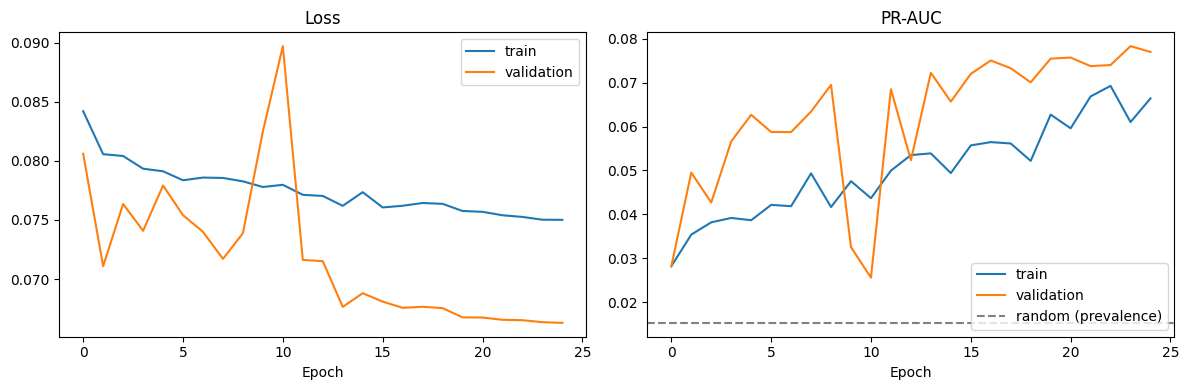

pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.081
recall@90spec,0.528
roc_auc,0.849


{'roc_auc': np.float64(0.849), 'pr_auc': np.float64(0.081), 'recall@90spec': np.float64(0.528), 'roc_auc_ci': (np.float64(0.797), np.float64(0.886)), 'pr_auc_ci': (np.float64(0.046), np.float64(0.129)), 'recall_ci': (np.float64(0.375), np.float64(0.665))}
Mean predicted probability: 0.0153 | prevalence: 0.0153


In [23]:
h = pd.DataFrame(hist5.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(h["pr_auc"], label="train"); ax[1].plot(h["val_pr_auc"], label="validation")
ax[1].axhline(yva.mean(), ls="--", color="gray", label="random (prevalence)")
ax[1].set_title("PR-AUC"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

# Evaluate best weights on validation (val_ds is unshuffled, so order matches val_df)
s_cnn = cnn.predict(val_ds, verbose=0).ravel()
assert len(s_cnn) == len(yva)
m = compute_metrics(yva, s_cnn)
ci = patient_bootstrap(yva, s_cnn, gva)
row = log_result("E5", "CNN-baseline", "deep",
                 {"arch": "4 conv blocks (32-64-128-128) + GAP + dropout 0.4",
                  "optimizer": "Adam 1e-3", "batch": BATCH_SIZE, "img": IMG_SIZE,
                  "augmentation": "flip/rot90/brightness/contrast", "class_weight": None,
                  "epochs_run": len(h), "mixed_precision": True},
                 "val", m, ci, "From-scratch baseline, no imbalance handling")
print({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec", "roc_auc_ci", "pr_auc_ci", "recall_ci"]})
print("Mean predicted probability:", round(s_cnn.mean(), 4), "| prevalence:", round(yva.mean(), 4))
np.save(f"{FEAT_DIR}/val_scores_e5.npy", s_cnn)

### 9.3 Experiment 5 results

The baseline CNN (242,017 parameters, four convolution blocks, trained from scratch for 25 epochs in 21.9 minutes) reached a validation ROC-AUC of 0.849 (95% patient-level bootstrap CI 0.80 to 0.89), a PR-AUC of 0.081 (0.05 to 0.13) and a recall of 0.528 (0.38 to 0.67) at 90% specificity. This matches Logistic Regression on ROC-AUC but is below Gradient Boosting on handcrafted features (PR-AUC 0.128) and the metadata-augmented model (ROC-AUC 0.876); the confidence intervals overlap, so the CNN is not shown to be worse, only not better. Keras reported a slightly lower PR-AUC (0.077) than the exact calculation used here because it integrates over a limited number of thresholds, so only the exact values are compared across models.

The learning curves indicate underfitting (high bias) rather than overfitting. Training loss decreased steadily from 0.084 to 0.075 and training PR-AUC rose from 0.028 to 0.066, with no divergence from validation, and both were still improving at epoch 25. Validation metrics lay above training metrics because training scores are computed with augmentation and dropout active. Validation loss and ROC-AUC were unstable between epochs 10 and 11 (ROC-AUC fell to 0.52), consistent with a validation set containing only 72 malignant images and a learning rate of 5e-4. The learning rate was then halved six times, reaching 1.6e-5, so late epochs changed the weights little; the schedule responded to a noisy validation metric and probably decayed too early.

The mean predicted probability (0.0153) equalled the validation prevalence, confirming that initialising the output bias to the training log-odds produced calibrated outputs without class weighting. Learning from 407 malignant images with a small network trained from scratch appears to be data-limited, which motivates transfer learning from pretrained features in Experiment 7.

### 9.4 Restore Session State

Colab sessions reset when the runtime changes or disconnects. This cell rebuilds the notebook state from files saved earlier, so that later experiments can run without repeating earlier work.

**What the code does:**

1. Copies the resized ISIC 2020 images to Colab's local disk (cached, so quick on repeat runs).

2. Loads the saved patient-level split (`split_assignments.csv`) and the encoded metadata (`metadata_features.parquet`), and checks that their rows line up.

3. Redefines the tf.data pipeline from Step 6 and the evaluation helpers from Step 8 (identical logic).

4. Reloads the results table so new experiments are appended and earlier ones are kept.

5. Confirms that a GPU is available and that one batch loads.

**Reproducibility:** it uses the same seed, split and preprocessing as the original run, so nothing changes. No model is retrained.

In [24]:
import time, json, glob, shutil
import kagglehub, wandb
from sklearn.metrics import roc_auc_score, average_precision_score

os.environ["WANDB_MODE"] = "offline"

# 1. Images to local disk
src = kagglehub.dataset_download("nischaydnk/isic-2020-jpg-256x256-resized")
if not os.path.exists(f"{DATA_DIR}/raw"):
    shutil.copytree(src, f"{DATA_DIR}/raw")
images = glob.glob(f"{DATA_DIR}/raw/**/*.jpg", recursive=True)
img_dir = os.path.dirname(images[0])

# 2. Saved split and metadata features
df = pd.read_csv(f"{BASE_DIR}/split_assignments.csv")
meta_feats = pd.read_parquet(f"{FEAT_DIR}/metadata_features.parquet")
assert (meta_feats["isic_id"].values == df["isic_id"].values).all()
feature_cols = [c for c in meta_feats.columns
                if c not in ["isic_id", "patient_id", "split", "target"]]

train_df, val_df, test_df = [df[df["split"] == s] for s in ["train", "val", "test"]]
ytr, yva = train_df["target"].values, val_df["target"].values
gva = val_df["patient_id"].values

# 3. tf.data pipeline (same as Step 6)
IMG_SIZE, BATCH_SIZE, AUTOTUNE = 224, 64, tf.data.AUTOTUNE

def load_image(path):
    img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    return tf.cast(tf.image.resize(img, [IMG_SIZE, IMG_SIZE]), tf.float32)

def augment(img):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    img = tf.image.random_brightness(img, max_delta=20.0)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    return tf.clip_by_value(img, 0.0, 255.0)

def make_dataset(d, training=False, use_meta=False, batch_size=BATCH_SIZE):
    paths  = [f"{img_dir}/{i}.jpg" for i in d["isic_id"]]
    labels = d["target"].values.astype("float32")
    meta   = meta_feats.loc[d.index, feature_cols].values.astype("float32")
    ds = tf.data.Dataset.from_tensor_slices((paths, meta, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    def _parse(path, m, y):
        img = load_image(path)
        if training:
            img = augment(img)
        return ({"image": img, "meta": m} if use_meta else img), y
    return ds.map(_parse, num_parallel_calls=AUTOTUNE).batch(batch_size).prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = (make_dataset(train_df, training=True),
                             make_dataset(val_df), make_dataset(test_df))

# 4. Evaluation helpers (same as Step 8)
def compute_metrics(y, s, thr=None, spec=0.90):
    y, s = np.asarray(y), np.asarray(s)
    if thr is None:
        thr = np.quantile(s[y == 0], spec)
    pred = s > thr
    return {"roc_auc": roc_auc_score(y, s), "pr_auc": average_precision_score(y, s),
            "recall_at_spec": pred[y == 1].mean(), "specificity": 1 - pred[y == 0].mean(),
            "threshold": thr}

def patient_bootstrap(y, s, groups, thr=None, n_boot=500, seed=SEED):
    y, s, groups = np.asarray(y), np.asarray(s), np.asarray(groups)
    rng = np.random.default_rng(seed)
    idx_by_pat = [np.where(groups == g)[0] for g in np.unique(groups)]
    out = {"roc_auc": [], "pr_auc": [], "recall_at_spec": []}
    for _ in range(n_boot):
        pick = rng.integers(0, len(idx_by_pat), len(idx_by_pat))
        idx = np.concatenate([idx_by_pat[i] for i in pick])
        if y[idx].sum() == 0:
            continue
        m = compute_metrics(y[idx], s[idx], thr)
        for k in out:
            out[k].append(m[k])
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in out.items()}

RES_PATH = f"{BASE_DIR}/results_table.csv"
RESULTS = pd.read_csv(RES_PATH).to_dict("records")

def log_result(exp, name, family, settings, split, m, ci, notes=""):
    row = {"exp": exp, "model": name, "family": family,
           "settings": json.dumps(settings, default=str), "split": split,
           "roc_auc": round(m["roc_auc"], 3), "pr_auc": round(m["pr_auc"], 3),
           "recall@90spec": round(m["recall_at_spec"], 3),
           "roc_auc_ci": tuple(np.round(ci["roc_auc"], 3)),
           "pr_auc_ci": tuple(np.round(ci["pr_auc"], 3)),
           "recall_ci": tuple(np.round(ci["recall_at_spec"], 3)), "notes": notes}
    RESULTS[:] = [r for r in RESULTS if r.get("exp") != exp]   # replace the old row, never duplicate
    RESULTS.append(row)
    pd.DataFrame(RESULTS).to_csv(RES_PATH, index=False)
    try:
        run = wandb.init(project="melanoma-isic2020", name=f"{exp}-{name}", dir=LOG_DIR,
                         config={**settings, "family": family, "split": split},
                         mode="offline", reinit="finish_previous")
        wandb.log({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec"]})
        run.finish()
    except Exception as e:
        print("W&B logging skipped:", e)
    return row

# 5. Checks
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Images:", len(images), "| split:", df["split"].value_counts().to_dict())
print("Results restored:", len(RESULTS), "rows ->", [r["exp"] for r in RESULTS])
x, y = next(iter(val_ds))
print("Val batch:", x.shape, "| val order matches:",
      np.array_equal(y.numpy(), yva[:len(y)]))

Using Colab cache for faster access to the 'isic-2020-jpg-256x256-resized' dataset.
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Images: 33126 | split: {'train': 23885, 'val': 4709, 'test': 4532}
Results restored: 14 rows -> ['E6A', 'E7a', 'E7b', 'T-E4', 'T-E8', 'T-E9', 'E8', 'E9', 'E1', 'E2a', 'E2b', 'E3', 'E4', 'E5']
Val batch: (64, 224, 224, 3) | val order matches: True


### 9.4b Experiment 6a: training code (off by default)

**Purpose:** the final notebook should contain the code that trained E6a, so anyone can reproduce it from top to bottom. Retraining takes about 25 minutes, so it is controlled by a switch.

**What the code does:**

1. `RUN_E6A_TRAINING = False` is the switch. With `False`, the cell only defines the training function and the next cells reload the saved E6a model from Drive, which gives the reported numbers without retraining.

2. With `True`, `run_cnn` trains the E5 architecture with a cosine learning-rate schedule (1e-3 to 1e-5 over 30 epochs, no class weights), restores the best epoch by validation PR-AUC (patience 10), saves the checkpoint and history, and logs the result as E6A.

3. The only differences from E5 are the learning-rate schedule, the number of epochs (30 instead of 25) and the patience (10 instead of 5). The architecture, augmentation and loss are the same.

**Note:** the model is single-seed, so retraining may give slightly different numbers from those in the results table.

In [25]:
RUN_E6A_TRAINING = False   # set True only to retrain E6a (about 25 min on a T4)

P = '/content/drive/MyDrive/melanoma_project'
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

def run_cnn(tag="e6a", name="CNN-cosine", epochs=30, notes="Cosine LR, no class weights"):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    train_ds = make_dataset(train_df, training=True,  use_meta=False, batch_size=BATCH_SIZE)
    val_ds   = make_dataset(val_df,   training=False, use_meta=False, batch_size=BATCH_SIZE)
    add_dim  = lambda x, y: (x, tf.expand_dims(y, -1))
    tr  = train_ds.map(add_dim, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
    val = val_ds.map(add_dim,   num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

    steps = int(np.ceil(len(train_df) / BATCH_SIZE))
    lr = tf.keras.optimizers.schedules.CosineDecay(1e-3, steps * epochs, alpha=0.01)
    m = build_cnn()
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="roc_auc"),
                       tf.keras.metrics.AUC(name="pr_auc", curve="PR")])

    cbs = [callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=10,
                                   restore_best_weights=True, verbose=1),
           callbacks.ModelCheckpoint(f"{P}/checkpoints/{tag}_cnn.keras", monitor="val_pr_auc",
                                     mode="max", save_best_only=True),
           callbacks.TensorBoard(log_dir=f"{P}/logs/tb/{tag}_cnn")]

    t0 = time.time()
    hist = m.fit(tr, validation_data=val, epochs=epochs, callbacks=cbs, verbose=2)
    h = pd.DataFrame(hist.history)
    h.to_csv(f"{P}/logs/{tag}_history.csv", index=False)

    s = m.predict(val_ds, verbose=0).ravel()
    assert s.shape[0] == yva.shape[0]
    met = compute_metrics(yva, s)
    ci = patient_bootstrap(yva, s, gva)

    RESULTS[:] = [r for r in RESULTS if r.get("exp") != tag.upper()]   # avoid a duplicate row
    row = log_result(tag.upper(), name, "deep",
                     {"arch": "same as E5 (242k params)", "optimizer": "Adam, cosine 1e-3 to 1e-5",
                      "epochs_run": len(h), "pos_weight": None, "batch": BATCH_SIZE,
                      "img": IMG_SIZE, "mixed_precision": True},
                     "val", met, ci, notes)
    np.save(f"{P}/features/val_scores_{tag}.npy", s)
    print(f"Time: {(time.time() - t0) / 60:.1f} min | epochs run: {len(h)}")
    print({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec"]})
    return m, h, s

if RUN_E6A_TRAINING:
    cnn6a, h6a, s6a = run_cnn()
else:
    print("E6a training skipped (RUN_E6A_TRAINING = False); the next cells reload the saved model.")

E6a training skipped (RUN_E6A_TRAINING = False); the next cells reload the saved model.


### 9.5 Experiment 6a: Cosine learning-rate schedule

**Purpose:** Experiment 5 showed underfitting. Its learning curves were still improving at epoch 25, and its ReduceLROnPlateau scheduler cut the learning rate six times (to 1.6e-5) in response to a noisy validation PR-AUC, so late epochs barely changed the weights. The main change in this experiment is the learning-rate schedule: a smooth cosine decay from 1e-3 to 1e-5 over 30 epochs, which does not depend on validation metrics. The epoch budget (30 instead of 25) and the early-stopping patience (10 instead of 5) were also increased, so any improvement cannot be attributed to the schedule alone.

**Setup (unchanged from E5 except as noted):** the same 242,017-parameter CNN, the same augmentation, binary cross-entropy with no class weights, output bias initialised to the training log-odds, and mixed precision. The best epoch by validation PR-AUC was restored.

**What the cell does:** the model was trained earlier (30.3 minutes on the T4) and its per-epoch history and validation scores were saved to Drive. This cell reloads them, plots the loss, PR-AUC and learning-rate curves, and prints the logged metrics, so the results can be interpreted without retraining.

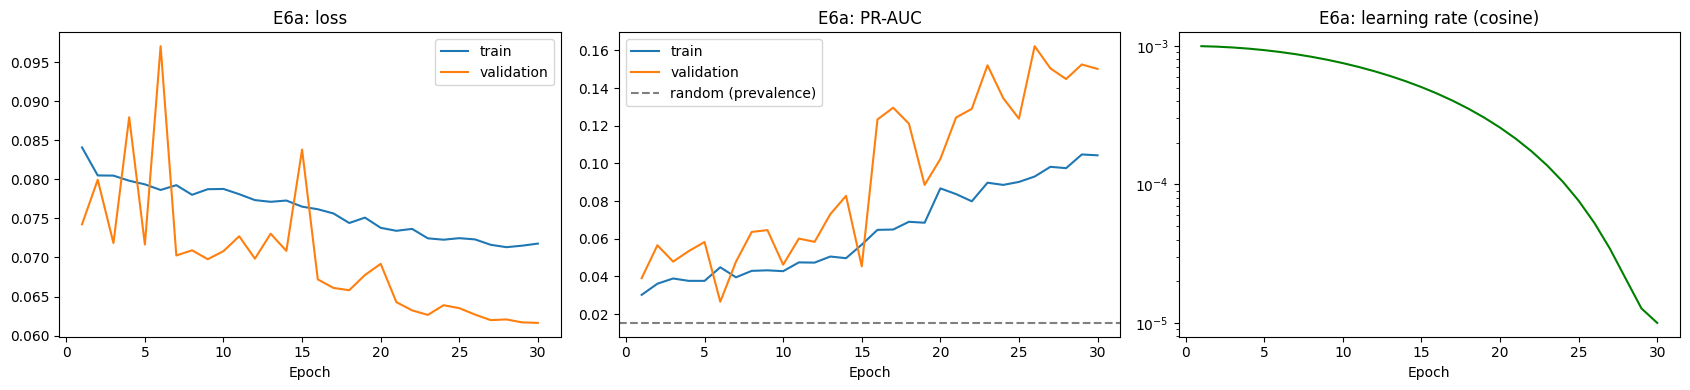

Epochs run: 30 | best epoch (val PR-AUC): 26
     loss  val_loss  pr_auc  val_pr_auc  roc_auc  val_roc_auc
1   0.084     0.074   0.030       0.039    0.696        0.766
5   0.079     0.072   0.038       0.058    0.748        0.790
10  0.079     0.071   0.043       0.046    0.755        0.790
15  0.077     0.084   0.057       0.045    0.781        0.736
20  0.074     0.069   0.087       0.102    0.811        0.837
25  0.072     0.064   0.090       0.124    0.826        0.869
30  0.072     0.062   0.104       0.150    0.831        0.878
26  0.072     0.063   0.093       0.162    0.833        0.876

Logged E6a: {'roc_auc': 0.875, 'pr_auc': 0.166, 'recall@90spec': 0.569, 'roc_auc_ci': '(np.float64(0.833), np.float64(0.913))', 'pr_auc_ci': '(np.float64(0.092), np.float64(0.278))', 'recall_ci': '(np.float64(0.446), np.float64(0.71))'}
Mean predicted probability: 0.0201 | prevalence: 0.0153


In [26]:
h6 = pd.read_csv(f"{LOG_DIR}/e6a_history.csv")
epochs = np.arange(1, len(h6) + 1)

# Cosine schedule (alpha = 0.01), learning rate at the end of each epoch
steps_per_epoch = int(np.ceil(len(train_df) / BATCH_SIZE))
total = steps_per_epoch * len(h6)
lr = 1e-3 * ((1 - 0.01) * 0.5 * (1 + np.cos(np.pi * epochs * steps_per_epoch / total)) + 0.01)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(epochs, h6["loss"], label="train"); ax[0].plot(epochs, h6["val_loss"], label="validation")
ax[0].set_title("E6a: loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(epochs, h6["pr_auc"], label="train"); ax[1].plot(epochs, h6["val_pr_auc"], label="validation")
ax[1].axhline(yva.mean(), ls="--", color="gray", label="random (prevalence)")
ax[1].set_title("E6a: PR-AUC"); ax[1].set_xlabel("Epoch"); ax[1].legend()
ax[2].plot(epochs, lr, color="green"); ax[2].set_yscale("log")
ax[2].set_title("E6a: learning rate (cosine)"); ax[2].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

best = int(h6["val_pr_auc"].idxmax())
print("Epochs run:", len(h6), "| best epoch (val PR-AUC):", best + 1)
print(h6.loc[[0, 4, 9, 14, 19, 24, 29, best],
      ["loss", "val_loss", "pr_auc", "val_pr_auc", "roc_auc", "val_roc_auc"]].round(3)
      .set_index(pd.Index([1, 5, 10, 15, 20, 25, 30, best + 1])))

e6a = [r for r in RESULTS if r["exp"] == "E6A"][0]
print("\nLogged E6a:", {k: e6a[k] for k in ["roc_auc", "pr_auc", "recall@90spec",
                                              "roc_auc_ci", "pr_auc_ci", "recall_ci"]})
s6a = np.load(f"{FEAT_DIR}/val_scores_e6a.npy")
print("Mean predicted probability:", round(s6a.mean(), 4), "| prevalence:", round(yva.mean(), 4))

### 9.6 Experiment 6a results

The cosine-schedule CNN reached a validation ROC-AUC of 0.875 (95% patient-level bootstrap CI 0.83 to 0.91), a PR-AUC of 0.166 (0.09 to 0.28) and a recall of 0.569 (0.45 to 0.71) at 90% specificity, using the weights from epoch 26 of 30. Training took 30.3 minutes. Compared with Experiment 5 (ROC-AUC 0.849, PR-AUC 0.081, recall 0.528), discrimination improved, and the image-only network now matches the best handcrafted-feature model, Gradient Boosting with metadata (ROC-AUC 0.876, PR-AUC 0.153). The confidence intervals overlap heavily, so the models are described as comparable and not as different. Because the epoch budget and patience were increased along with the schedule, and only one seed was run, the improvement cannot be attributed to the schedule alone.

The learning curves show how the schedule changed training. Validation loss spiked at epochs 4, 6 and 15 (up to 0.097) while the learning rate was between 1e-3 and 5e-4, and then fell smoothly to 0.062 once the rate fell to about 4.5e-4 or below (from epoch 16), whereas in Experiment 5 the scheduler halved the rate six times in response to noisy validation PR-AUC. Training loss (0.072) remained above validation loss (0.062) throughout, because training metrics are computed with augmentation and dropout active, so there is no sign of overfitting (no divergence between the curves). The model nevertheless underfits: training ROC-AUC reached only 0.83 and training PR-AUC was still rising slowly (0.104) when the learning rate reached its floor. This high-bias pattern suggests that a small network trained from scratch on 407 malignant images is limited by representational capacity and data, not by optimisation, which motivates pretrained features in Experiment 7.

Validation PR-AUC fluctuated between 0.12 and 0.16 over the last fifteen epochs, because the validation set contains only 72 malignant images. Selecting the best epoch on this noisy metric makes the reported value optimistic: the value at epoch 30 was 0.150. The mean predicted probability (0.0201) is close to the prevalence (0.0153), so the output probabilities are reasonably calibrated without class weighting. Recall at 90% specificity (0.569) did not improve beyond the tabular models (0.583 to 0.634), showing that the gain is in the ranking of high-scoring images and not in the sensitivity at this operating point.

## 10. Transfer Learning

### 10.1 Experiment 7a (part 1): Frozen EfficientNetB0 feature extraction

**Purpose:** Experiments 5 and 6a showed that a small CNN trained from scratch underfits, limited by only 407 malignant training images. Transfer learning addresses this by starting from a network pretrained on ImageNet (1.28 million natural images), whose early layers already detect edges, colours and textures.

**What the code does:**

1. Loads EfficientNetB0 pretrained on ImageNet, without its classification layer, and freezes it (no weights are changed). Global average pooling turns each image into a 1,280-dimensional embedding. EfficientNet contains its own rescaling and normalisation layers, so it takes the 0-255 pixel values from our pipeline directly.

2. Passes all 33,126 images through it once, without augmentation and without shuffling, in the same row order as `split_assignments.csv`.

3. Checks the embedding table (shape, missing values, scale) and saves it to Drive, so the classifier experiments can be repeated quickly without a GPU.

**Design choices and limitations:**

- Computing embeddings once is much cheaper than training through the backbone for every epoch, and it makes the next experiment fast to tune.

- Because the embeddings are computed once, training images cannot be augmented in E7a. Fine-tuning (E8) restores augmentation.

- ImageNet contains natural photographs, not dermoscopic images, so some features may transfer poorly (domain shift). The results will show how much transfers.

- The pretrained weights are reused from the public Keras release and are acknowledged as such. No ISIC data was used in the pretraining.

In [27]:
backbone = tf.keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
backbone.trainable = False
print("Backbone parameters:", f"{backbone.count_params():,}", "| output:", backbone.output_shape)

# All images, unaugmented and unshuffled, in the row order of df
all_ds = make_dataset(df, training=False, batch_size=128)

t0 = time.time()
emb = backbone.predict(all_ds, verbose=1).astype("float32")
print(f"\nExtraction time: {(time.time() - t0) / 60:.1f} min")

# Checks
print("Embeddings:", emb.shape, "| rows in df:", len(df))
assert emb.shape == (len(df), 1280)
print("NaN values:", int(np.isnan(emb).sum()))
print("Mean %.3f | std %.3f | min %.3f | max %.3f" % (emb.mean(), emb.std(), emb.min(), emb.max()))
print("Rows per split:", df["split"].value_counts().to_dict())

np.save(f"{FEAT_DIR}/effnetb0_embeddings.npy", emb)
print("Saved to Drive.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Backbone parameters: 4,049,571 | output: (None, 1280)
259/259 ━━━━━━━━━━━━━━━━━━━━ 77s 195ms/step

Extraction time: 1.3 min
Embeddings: (33126, 1280) | rows in df: 33126
NaN values: 0
Mean 0.005 | std 0.346 | min -0.274 | max 6.227
Rows per split: {'train': 23885, 'val': 4709, 'test': 4532}
Saved to Drive.


### 10.2 Feature extraction results

The frozen EfficientNetB0 backbone (4,049,571 parameters, ImageNet weights) converted all 33,126 images into 1,280-dimensional embeddings in 1.2 minutes on the T4 GPU. The table has no missing values and its rows follow the order of the saved patient-level split (23,885 training, 4,709 validation and 4,532 test images). Values range from -0.27 to 6.23 with a mean of 0.005: they are slightly negative in places because the network's final activation (swish) is not strictly non-negative, and most dimensions are near zero while a few respond strongly, which is typical of pooled convolutional features. Standardisation is applied inside the classifier pipelines, fitted on training data only. The embeddings are saved to Drive, so the classifier experiments can be repeated without a GPU.

### 10.3 Experiment 7a: Logistic Regression on frozen EfficientNetB0 embeddings

**Purpose:** measure how much melanoma-relevant information ImageNet features carry, using the simplest possible classifier. Comparing with Experiment 1 (the same model on 48 handcrafted features) isolates the effect of the feature representation.

**What the code does:**

1. Loads the saved embeddings and splits them by the patient-level assignment (same rows as every earlier experiment).

2. Builds a pipeline of standardisation and Logistic Regression, fitted on the training set only. With 1,280 features and 407 malignant training images, strong regularisation is needed, so C is varied from 0.0001 to 0.1 (smaller C means stronger regularisation).

3. Chooses C by validation PR-AUC, and also prints training ROC-AUC, so overfitting shows up as a gap between training and validation.

4. Computes patient-level bootstrap intervals and logs the run.

**Setup:** no class weights and no resampling, consistent with Experiments 1 and 2.

In [28]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

emb = np.load(f"{FEAT_DIR}/effnetb0_embeddings.npy")
assert len(emb) == len(df)
m_tr, m_va, m_te = [(df["split"] == s).values for s in ["train", "val", "test"]]
Etr, Eva, Ete = emb[m_tr], emb[m_va], emb[m_te]
assert (df.loc[m_tr, "target"].values == ytr).all() and (df.loc[m_va, "target"].values == yva).all()
print("Train", Etr.shape, "| val", Eva.shape, "| test", Ete.shape)

rows, models7 = [], {}
for C in [0.0001, 0.001, 0.01, 0.1]:
    t0 = time.time()
    mdl = Pipeline([("sc", StandardScaler()),
                    ("clf", LogisticRegression(C=C, max_iter=3000, random_state=SEED))]).fit(Etr, ytr)
    s_tr, s_va = mdl.predict_proba(Etr)[:, 1], mdl.predict_proba(Eva)[:, 1]
    m = compute_metrics(yva, s_va)
    rows.append({"C": C, "train_roc": round(roc_auc_score(ytr, s_tr), 3),
                 "val_roc": round(m["roc_auc"], 3), "val_pr": round(m["pr_auc"], 3),
                 "val_recall": round(m["recall_at_spec"], 3), "sec": round(time.time() - t0)})
    models7[C] = (mdl, s_va)
sweep7 = pd.DataFrame(rows)
print(sweep7.to_string(index=False))

best_C = sweep7.loc[sweep7["val_pr"].idxmax(), "C"]
print("\nBest C by validation PR-AUC:", best_C)
s7a = models7[best_C][1]
m = compute_metrics(yva, s7a)
ci = patient_bootstrap(yva, s7a, gva)
row = log_result("E7a", "LogReg-EffNetB0-emb", "traditional",
                 {"C": best_C, "features": "EfficientNetB0 frozen embeddings (1280)",
                  "scaler": "standard", "class_weight": None},
                 "val", m, ci, "Traditional model on frozen ImageNet features")
print({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec", "roc_auc_ci", "pr_auc_ci", "recall_ci"]})

Train (23885, 1280) | val (4709, 1280) | test (4532, 1280)
     C  train_roc  val_roc  val_pr  val_recall  sec
0.0001      0.846    0.852   0.109       0.569    3
0.0010      0.911    0.869   0.126       0.583    3
0.0100      0.959    0.834   0.095       0.556    4
0.1000      0.982    0.777   0.070       0.403    8

Best C by validation PR-AUC: 0.001


pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.126
recall@90spec,0.583
roc_auc,0.869


{'roc_auc': np.float64(0.869), 'pr_auc': np.float64(0.126), 'recall@90spec': np.float64(0.583), 'roc_auc_ci': (np.float64(0.823), np.float64(0.911)), 'pr_auc_ci': (np.float64(0.082), np.float64(0.204)), 'recall_ci': (np.float64(0.453), np.float64(0.725))}


### 10.4 Experiment 7a results

Logistic Regression on frozen EfficientNetB0 embeddings reached a validation ROC-AUC of 0.869 (95% patient-level bootstrap CI 0.82 to 0.91), a PR-AUC of 0.126 (0.08 to 0.20) and a recall of 0.583 (0.45 to 0.72) at 90% specificity, using C = 0.001. This is slightly above the same classifier on 48 handcrafted features (Experiment 1: 0.849, 0.101, 0.556) and below Gradient Boosting with metadata (0.876, 0.153) and the cosine-schedule CNN (0.875, 0.166). All confidence intervals overlap, so ImageNet features are described as comparable to handcrafted and from-scratch features, not as better. Because C was selected on the validation set, these values are slightly optimistic.

The regularisation sweep shows the bias-variance trade-off clearly. At the strongest regularisation (C = 0.0001), training and validation ROC-AUC were almost equal (0.846 and 0.853) and both low, indicating underfitting (high bias). At the weakest (C = 0.1), training ROC-AUC rose to 0.982 while validation fell to 0.776 and recall dropped to 0.417, indicating overfitting (high variance): with 1,280 features and only 407 malignant training images, a weakly regularised model memorises training lesions. The best validation performance occurred at an intermediate value (C = 0.001, training 0.911, validation 0.869). The result suggests that the transferred features carry useful signal about lesion appearance despite the domain shift from natural images to dermoscopy, but that the small number of malignant examples limits how much a linear classifier can exploit.

### 10.5 Experiment 7b: Keras classifier head on frozen embeddings

**Purpose:** test whether a small non-linear neural network extracts more from the same embeddings than Logistic Regression, and provide the deep learning counterpart (Keras with a `tf.data` pipeline) to Experiment 7a.

**What the code does:**

1. Standardises the embeddings with training-set statistics only, and builds `tf.data` pipelines (the training set is shuffled each epoch).

2. Defines a Sequential network: Dense(256, ReLU), Dropout(0.5), Dense(1, sigmoid), with the output bias initialised to the training log-odds, as in Experiment 5.

3. Trains with Adam (1e-3), batch size 256, up to 60 epochs, monitoring validation PR-AUC (patience 8, best weights restored).

4. Repeats training with three random seeds and reports mean and standard deviation, because a single run is noisy with only 72 malignant validation images.

5. Plots the learning curves for the first seed, evaluates with the same helpers as all other models, and logs the first seed with bootstrap intervals.

**Setup:** no class weights and no augmentation (embeddings were computed once, from unaugmented images). With 1,280 inputs and only 407 positives, overfitting is expected, so the training and validation curves are examined.

seed 42: epochs 9, 12 s
seed 43: epochs 10, 10 s
seed 44: epochs 16, 13 s

Mean ± std over 3 seeds
ROC-AUC: 0.855 ± 0.014
PR-AUC: 0.107 ± 0.004
Recall@90spec: 0.546 ± 0.035


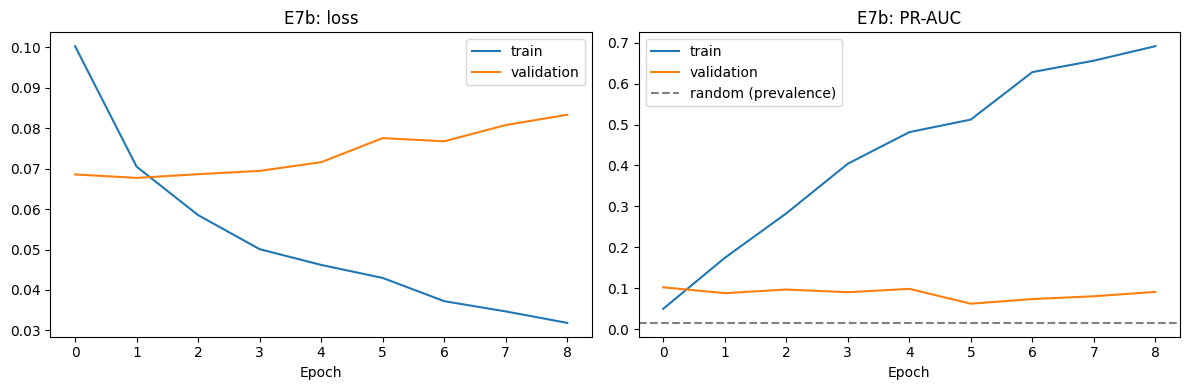

pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.108
recall@90spec,0.542
roc_auc,0.845


{'roc_auc': np.float64(0.845), 'pr_auc': np.float64(0.108), 'recall@90spec': np.float64(0.542), 'roc_auc_ci': (np.float64(0.792), np.float64(0.896)), 'pr_auc_ci': (np.float64(0.062), np.float64(0.182)), 'recall_ci': (np.float64(0.418), np.float64(0.684))}
Mean predicted probability: 0.0101 | prevalence: 0.0153


In [29]:
from tensorflow.keras import layers, models, callbacks

mu, sd = Etr.mean(0), Etr.std(0) + 1e-6
Ztr, Zva, Zte = (Etr - mu) / sd, (Eva - mu) / sd, (Ete - mu) / sd
bias0 = float(np.log(ytr.mean() / (1 - ytr.mean())))

def head_ds(Z, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((Z.astype("float32"), y.astype("float32").reshape(-1, 1)))
    if training:
        ds = ds.shuffle(len(Z), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(256).prefetch(AUTOTUNE)

def train_head(seed):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    m = models.Sequential([layers.Input((1280,)),
                           layers.Dense(256, activation="relu"), layers.Dropout(0.5),
                           layers.Dense(1, activation="sigmoid",
                                        bias_initializer=tf.keras.initializers.Constant(bias0))])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="roc_auc"),
                       tf.keras.metrics.AUC(name="pr_auc", curve="PR")])
    h = m.fit(head_ds(Ztr, ytr, True), validation_data=head_ds(Zva, yva), epochs=60, verbose=0,
              callbacks=[callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=8,
                                                 restore_best_weights=True)])
    return m, pd.DataFrame(h.history), m.predict(head_ds(Zva, yva), verbose=0).ravel()

runs, mets = {}, []
for seed in [SEED, SEED + 1, SEED + 2]:
    t0 = time.time()
    runs[seed] = train_head(seed)
    mets.append(compute_metrics(yva, runs[seed][2]))
    print(f"seed {seed}: epochs {len(runs[seed][1])}, {time.time() - t0:.0f} s")
d = pd.DataFrame(mets)
print("\nMean ± std over 3 seeds")
for k, name in [("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("recall_at_spec", "Recall@90spec")]:
    print(f"{name}: {d[k].mean():.3f} ± {d[k].std():.3f}")

# Learning curves (first seed)
hh = runs[SEED][1]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hh["loss"], label="train"); ax[0].plot(hh["val_loss"], label="validation")
ax[0].set_title("E7b: loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hh["pr_auc"], label="train"); ax[1].plot(hh["val_pr_auc"], label="validation")
ax[1].axhline(yva.mean(), ls="--", color="gray", label="random (prevalence)")
ax[1].set_title("E7b: PR-AUC"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

s7b = runs[SEED][2]
m = compute_metrics(yva, s7b)
ci = patient_bootstrap(yva, s7b, gva)
row = log_result("E7b", "Keras-head-EffNetB0-emb", "deep",
                 {"head": "Dense256-ReLU-Dropout0.5-Sigmoid", "optimizer": "Adam 1e-3", "batch": 256,
                  "epochs_run": len(hh), "features": "EfficientNetB0 frozen embeddings (1280)",
                  "seeds": 3, "class_weight": None},
                 "val", m, ci, "Neural head on frozen ImageNet features (seed 42 row; 3-seed mean in notes)")
print({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec", "roc_auc_ci", "pr_auc_ci", "recall_ci"]})
print("Mean predicted probability:", round(s7b.mean(), 4), "| prevalence:", round(yva.mean(), 4))
np.save(f"{FEAT_DIR}/val_scores_e7a.npy", s7a); np.save(f"{FEAT_DIR}/val_scores_e7b.npy", s7b)

### 10.6 Experiment 7b results

A Keras network (one hidden layer of 256 units with dropout 0.5) trained on the frozen EfficientNetB0 embeddings reached, averaged over three seeds, a validation ROC-AUC of 0.855 ± 0.014, a PR-AUC of 0.107 ± 0.004 and a recall of 0.546 ± 0.035 at 90% specificity. The first seed (the logged run) gave 0.845, 0.108 and 0.542, with 95% patient-level bootstrap intervals of 0.79 to 0.90 for ROC-AUC and 0.06 to 0.18 for PR-AUC. This is slightly below Logistic Regression on the same embeddings (Experiment 7a: 0.869, 0.126, 0.583), but the differences are of the order of the seed variation and the intervals overlap, so the more flexible head is described as not better, not as worse.

The learning curves show severe overfitting (high variance). Training PR-AUC rose from 0.05 to 0.69 over nine epochs and training loss fell from 0.100 to 0.032, while validation PR-AUC remained between 0.06 and 0.10 and validation loss reached its minimum near epoch 2 (0.067) and then rose to 0.082. With 1,280 inputs, 328,000 parameters in the hidden layer and only 407 malignant training images, the network memorises individual training lesions instead of learning features that generalise. Because the embeddings were computed once from unaugmented images, no augmentation could counteract this. Early stopping on validation PR-AUC, which is noisy with only 72 positives, selected the weights from the first epoch for the first seed, the second epoch for the second seed and the eighth epoch for the third, so for most seeds the reported performance reflects an almost untrained head. The mean predicted probability (0.0101) was below the prevalence (0.0153), so the outputs are slightly under-confident, although this does not affect ranking metrics.

Together, Experiments 7a and 7b indicate that frozen ImageNet features carry useful but limited signal, and that the best use of them with so few positives is a very regularised linear model. They motivate Experiment 8, where the backbone itself is fine-tuned with augmentation so that features adapt to dermoscopic images.

## 11. Fine-Tuning

### 11.1 Experiment 8, phase 1: new classification head on a frozen EfficientNetB0

**Purpose:** Experiments 5 and 6a (from scratch) were limited by too little data, and Experiment 7 (frozen features) overfit and could not use augmentation. Fine-tuning combines both ideas: start from ImageNet weights, train on augmented images, and let the upper layers adapt to dermoscopy.

**Why two phases:** a randomly initialised classification layer sends large, meaningless gradients into a pretrained backbone if everything is trained at once, which can destroy the useful pretrained features. Phase 1 therefore trains only the new head (backbone frozen) so that it starts from sensible weights. Phase 2 (next section) then unfreezes the top of the backbone.

**What the code does:**

1. Builds the model with the Keras **Functional API**: EfficientNetB0 (ImageNet weights, global average pooling) followed by Dropout(0.3) and a sigmoid output whose bias is initialised to the training log-odds. The backbone has its own rescaling layers, so it takes the 0-255 pixels from the `tf.data` pipeline directly.

2. Uses the training pipeline from Step 6 (augmentation on training images only) and mixed precision for speed on the T4.

3. Trains the head for 3 epochs (Adam, learning rate 1e-3), keeping the weights of the epoch with the best validation PR-AUC. The weights are saved to Drive, and the cell skips training if they already exist, so it is safe to re-run after a disconnect.

**Setup:** binary cross-entropy with no class weights, because Experiment 3 showed that reweighting did not improve ranking and distorted calibration.

In [31]:
from tensorflow.keras import layers, models, callbacks

tf.keras.mixed_precision.set_global_policy("mixed_float16")
tf.keras.utils.set_random_seed(SEED)

STEPS_PER_EPOCH = int(np.ceil(len(train_df) / BATCH_SIZE))
bias0 = float(np.log(ytr.mean() / (1 - ytr.mean())))
add_dim = lambda x, y: (x, tf.expand_dims(y, -1))
tr8 = train_ds.map(add_dim, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
va8 = val_ds.map(add_dim, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
P1 = f"{CKPT_DIR}/e8_phase1.weights.h5"
P2 = f"{CKPT_DIR}/e8_phase2.weights.h5"

def build_effnet():
    base = tf.keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = base(inp, training=False)           # backbone kept in inference mode (BatchNorm stable)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid", dtype="float32",
                       bias_initializer=tf.keras.initializers.Constant(bias0))(x)
    return models.Model(inp, out, name="effnetb0_finetune"), base

def compile_model(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="roc_auc"),
                       tf.keras.metrics.AUC(name="pr_auc", curve="PR")])

model, base = build_effnet()
base.trainable = False
compile_model(model, 1e-3)
print("Trainable parameters (phase 1): %s of %s" % (
    f"{sum(int(np.prod(w.shape)) for w in model.trainable_weights):,}",
    f"{model.count_params():,}"))

if os.path.exists(P1):
    print("Phase 1 weights already saved, skipping training.")
else:
    t0 = time.time()
    h1 = model.fit(tr8, validation_data=va8, epochs=3, verbose=2,
                   callbacks=[callbacks.ModelCheckpoint(P1, monitor="val_pr_auc", mode="max",
                                                        save_best_only=True, save_weights_only=True)])
    print(f"Phase 1 time: {(time.time() - t0) / 60:.1f} min")
    pd.DataFrame(h1.history).to_csv(f"{LOG_DIR}/e8_phase1_history.csv", index=False)

Trainable parameters (phase 1): 1,281 of 4,050,852
Phase 1 weights already saved, skipping training.


### 11.1b Experiment 8, phase 1 results

Phase 1 trained 1,281 of 4,050,852 parameters (the new head only) for three epochs in 4.6 minutes; the first epoch took longer (149 s against 46 to 48 s) because of one-off start-up costs, and the pipeline's image decoding and augmentation, not the frozen backbone, set the later epoch time. Validation PR-AUC rose from 0.083 to 0.129, ROC-AUC from 0.843 to 0.866 and validation loss fell from 0.067 to 0.064 (Keras's approximate metrics), so a head on frozen features with augmentation already reaches the level of the Logistic Regression on frozen embeddings (Experiment 7a: ROC-AUC 0.869, PR-AUC 0.126). Unlike Experiment 7b, which overfitted a 328,000-weight head on unaugmented embeddings, training and validation did not diverge: validation scores exceeded training scores because training metrics are computed with augmentation and dropout active. The metrics were still improving at epoch 3, so the head had not converged, and the weights from epoch 3 were saved as the starting point for phase 2.

### 11.2 Experiment 8, phase 2: fine-tuning the top of EfficientNetB0

**What the code does:**

1. Rebuilds the model, loads the phase 1 weights, and unfreezes the last 80 layers of the backbone, which hold the most task-specific features. Earlier layers (edges, colours, simple textures) stay frozen because they transfer well and have the fewest weights to overfit. BatchNormalization layers stay frozen, because with a small number of positives their running statistics become unstable when updated.

2. Trains for 8 epochs with Adam at a low learning rate (1e-4, decaying by a cosine schedule to 1e-6), so the pretrained weights are adjusted gently and not overwritten.

3. After every epoch, saves the best weights by validation PR-AUC to Drive, and writes the training history (CSV) and TensorBoard logs to Drive, so a disconnect loses little.

4. Restores the best weights, plots the learning curves, evaluates on the validation set with the same helpers as every other model (ROC-AUC, PR-AUC, recall at 90% specificity, patient-level bootstrap intervals), logs the run, and saves the model to the models folder.

**Design choices:** all 8 epochs are run, with no early stopping, because validation PR-AUC is noisy (72 positives) and early stopping selected a barely-trained model in Experiment 7b. The best epoch is chosen afterwards, which is slightly optimistic for the validation score, and the test set will give the unbiased estimate. This is a single run, so differences from earlier models are interpreted with care.

Trainable parameters (phase 2): 3,206,429 of 4,050,852
Phase 2 weights found, skipping training (RUN_E8_TRAINING = False).


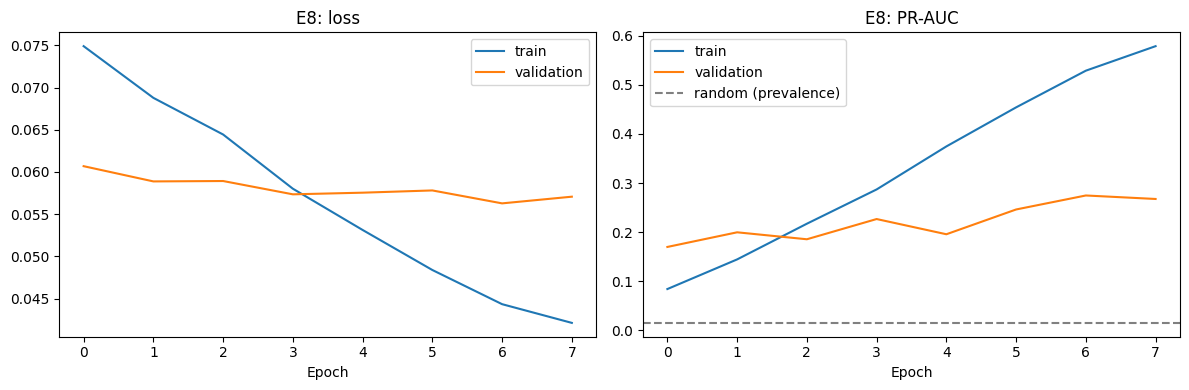

pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.279
recall@90spec,0.708
roc_auc,0.908



Best epoch: 7 of 8 | (training skipped, saved weights loaded)
    loss  val_loss  pr_auc  val_pr_auc  roc_auc  val_roc_auc
0  0.075     0.061   0.084       0.170    0.805        0.897
1  0.069     0.059   0.145       0.200    0.852        0.891
2  0.064     0.059   0.217       0.186    0.876        0.894
3  0.058     0.057   0.287       0.227    0.916        0.896
4  0.053     0.058   0.375       0.196    0.929        0.888
5  0.048     0.058   0.454       0.246    0.946        0.884
6  0.044     0.056   0.529       0.275    0.957        0.892
7  0.042     0.057   0.579       0.268    0.959        0.890
{'roc_auc': np.float64(0.908), 'pr_auc': np.float64(0.279), 'recall@90spec': np.float64(0.708), 'roc_auc_ci': (np.float64(0.874), np.float64(0.938)), 'pr_auc_ci': (np.float64(0.186), np.float64(0.395)), 'recall_ci': (np.float64(0.609), np.float64(0.81))}
Mean predicted probability: 0.0127 | prevalence: 0.0153


In [39]:
RUN_E8_TRAINING = False   # set True only to retrain phase 2 (about 20-40 min on a T4)
N_UNFREEZE, EPOCHS = 80, 8

model, base = build_effnet()
model.load_weights(P1)
base.trainable = True
for l in base.layers[:-N_UNFREEZE]:
    l.trainable = False
for l in base.layers:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False
print("Trainable parameters (phase 2): %s of %s" % (
    f"{sum(int(np.prod(w.shape)) for w in model.trainable_weights):,}", f"{model.count_params():,}"))

lr = tf.keras.optimizers.schedules.CosineDecay(1e-4, STEPS_PER_EPOCH * EPOCHS, alpha=0.01)
compile_model(model, lr)

HIST8 = f"{LOG_DIR}/e8_phase2_history.csv"
if RUN_E8_TRAINING or not os.path.exists(P2):
    t0 = time.time()
    h2 = model.fit(tr8, validation_data=va8, epochs=EPOCHS, verbose=2,
                   callbacks=[callbacks.ModelCheckpoint(P2, monitor="val_pr_auc", mode="max",
                                                        save_best_only=True, save_weights_only=True),
                              callbacks.CSVLogger(HIST8),
                              callbacks.TensorBoard(log_dir=f"{LOG_DIR}/tb/e8_phase2")])
    mins = (time.time() - t0) / 60
    h = pd.DataFrame(h2.history)
else:
    print("Phase 2 weights found, skipping training (RUN_E8_TRAINING = False).")
    mins = float("nan")
    h = pd.read_csv(HIST8)

best = int(h["val_pr_auc"].idxmax()) + 1
model.load_weights(P2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("E8: loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(h["pr_auc"], label="train"); ax[1].plot(h["val_pr_auc"], label="validation")
ax[1].axhline(yva.mean(), ls="--", color="gray", label="random (prevalence)")
ax[1].set_title("E8: PR-AUC"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

s8 = model.predict(val_ds, verbose=0).ravel()
assert len(s8) == len(yva)
m = compute_metrics(yva, s8)
ci = patient_bootstrap(yva, s8, gva)
RESULTS[:] = [r for r in RESULTS if r.get("exp") != "E8"]   # avoid a duplicate row
row = log_result("E8", "EffNetB0-finetune", "deep",
                 {"backbone": "EfficientNetB0 ImageNet", "unfrozen_layers": N_UNFREEZE,
                  "optimizer": "Adam, cosine 1e-4 to 1e-6", "epochs": EPOCHS, "best_epoch": best,
                  "batch": BATCH_SIZE, "img": IMG_SIZE, "head": "Dropout0.3+Dense1",
                  "augmentation": "flip/rot90/brightness/contrast", "class_weight": None,
                  "mixed_precision": True},
                 "val", m, ci, "Two-phase fine-tuning, best epoch by val PR-AUC")
np.save(f"{FEAT_DIR}/val_scores_e8.npy", s8)
model.save(f"{MODEL_DIR}/e8_effnetb0_finetuned.keras")
print(f"\nBest epoch: {best} of {EPOCHS}", f"| Training time: {mins:.1f} min" if mins == mins else "| (training skipped, saved weights loaded)")
print(h[["loss", "val_loss", "pr_auc", "val_pr_auc", "roc_auc", "val_roc_auc"]].round(3).to_string())
print({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec", "roc_auc_ci", "pr_auc_ci", "recall_ci"]})
print("Mean predicted probability:", round(s8.mean(), 4), "| prevalence:", round(yva.mean(), 4))

**Switch:** `RUN_E8_TRAINING = False` reloads the saved phase 2 weights and training history from Drive instead of retraining, then re-evaluates on the validation set. Setting it to `True` retrains phase 2 (about 20–40 minutes). Retraining may give slightly different numbers from the logged ones, because the run is single-seed and GPU training is not fully deterministic.

### 11.3 Experiment 8 results

Fine-tuning EfficientNetB0 (the last 80 layers and the new head, 3.2 million of 4.05 million parameters) for eight epochs reached a validation ROC-AUC of 0.908 (95% patient-level bootstrap CI 0.874 to 0.938), a PR-AUC of 0.279 (0.186 to 0.395) and a recall of 0.708 (0.609 to 0.810) at 90% specificity, using the weights from epoch 7. Phase 2 took 9.5 minutes on the T4. This is the strongest model so far: the cosine-schedule CNN trained from scratch (Experiment 6a) reached 0.875, 0.166 and 0.569, and frozen ImageNet features with a linear classifier (Experiment 7a) reached 0.869, 0.126 and 0.583. All three metrics are higher, but the confidence intervals overlap, so the improvement is described as consistent and not statistically confirmed. Keras's own AUC values during training were lower than the exact values (for example, 0.892 against 0.908 for validation ROC-AUC) because Keras integrates over 200 evenly spaced thresholds and the model's scores are concentrated at low values, so only the exact values are compared across models.

The learning curves show what fine-tuning achieved and where it began to overfit. Most of the ROC-AUC gain appeared in the first fine-tuning epoch (validation ROC-AUC rose from about 0.87 at the end of phase 1 to 0.90) and then stayed between 0.88 and 0.90, whereas validation PR-AUC, which depends on how the few highest-scoring images are ranked, rose from 0.17 to 0.27 with considerable epoch-to-epoch noise. From about epoch 4 the curves diverged: training loss fell from 0.075 to 0.042 and training PR-AUC rose to 0.58, but validation loss flattened near 0.057 and validation PR-AUC remained below 0.28. With 3.2 million trainable parameters and 407 malignant training images, the network begins to memorise individual training lesions (high variance), in contrast to the underfitting (high bias) seen in Experiment 6a. Augmentation, dropout in the head, a low learning rate and frozen BatchNorm layers limited this, but did not remove it. Because the best epoch was selected on the validation set, and only one run was made, the validation scores are slightly optimistic; the held-out test set is used for the unbiased estimate.

The mean predicted probability (0.0127) was somewhat below the prevalence (0.0153), so the model slightly under-predicts risk on average, which does not affect ranking metrics. Compared with the handcrafted-feature models, which were limited by the information in 48 hand-designed descriptors and by noisy segmentation, the fine-tuned network learns its own features from the pixels, which is the most likely reason for the gain.

## 12. Multimodal Fusion

### 12.1 Experiment 9: EfficientNetB0 fine-tuning with clinical metadata

**Purpose:** test whether age, sex and lesion site add information to a fine-tuned image network, as they did for the handcrafted-feature model in Experiment 4 (ROC-AUC 0.862 to 0.876).

**What the code does:**

1. Builds a two-input model with the Keras **Functional API**. The image branch is the same EfficientNetB0 as in Experiment 8. The metadata branch passes the 12 encoded features from Step 5 through a Dense(16, ReLU) layer. The two branches are concatenated, followed by Dropout(0.3) and a sigmoid output (bias initialised to the training log-odds).

2. Uses the `tf.data` pipeline from Step 6 with `use_meta=True`, so each batch is a dictionary with an `image` and a `meta` input. Augmentation is applied to the images only.

3. Trains with exactly the Experiment 8 recipe, so the only difference between the two experiments is the metadata: phase 1 trains the new layers with the backbone frozen (3 epochs, learning rate 1e-3); phase 2 unfreezes the last 80 backbone layers (BatchNorm frozen) for 8 epochs with a cosine learning rate from 1e-4 to 1e-6. The best epoch by validation PR-AUC is restored.

4. Evaluates with the same helpers as all other models, and adds a **paired patient-level bootstrap** of the differences between models (E9 minus E8, and E8 minus E6a). Because every model is scored on the same patients, the paired difference is a much more sensitive test than comparing two overlapping intervals.

**Why the model starts from ImageNet weights and not from Experiment 8:** the Experiment 8 backbone has already fitted the training images, so its features are over-confident on them, and a metadata branch trained on top would learn to under-use age and site. Starting from the same pretrained point as Experiment 8 keeps the comparison fair.

**Clinical note:** age, sex and lesion site are recorded at the point of care and are not derived from the diagnosis, so they are legitimate inputs and not leakage.

Phase 2 weights found, skipping training (RUN_E9_TRAINING = False).


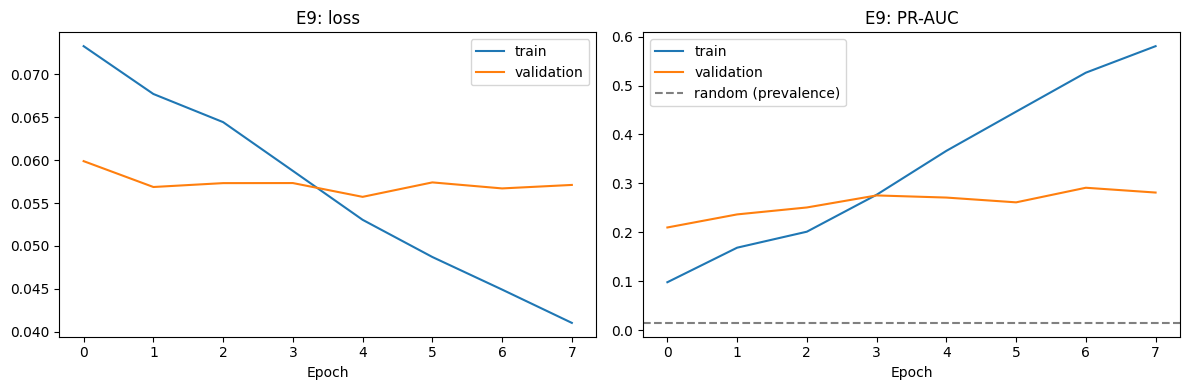

pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.295
recall@90spec,0.708
roc_auc,0.904



Best epoch: 7 of 8 | (training skipped, saved weights loaded)
    loss  val_loss  pr_auc  val_pr_auc  roc_auc  val_roc_auc
0  0.073     0.060   0.098       0.210    0.816        0.898
1  0.068     0.057   0.169       0.237    0.857        0.891
2  0.064     0.057   0.202       0.251    0.879        0.902
3  0.059     0.057   0.277       0.276    0.913        0.888
4  0.053     0.056   0.367       0.271    0.932        0.900
5  0.049     0.057   0.447       0.261    0.945        0.888
6  0.045     0.057   0.526       0.291    0.952        0.893
7  0.041     0.057   0.580       0.281    0.965        0.892
{'roc_auc': np.float64(0.904), 'pr_auc': np.float64(0.295), 'recall@90spec': np.float64(0.708), 'roc_auc_ci': (np.float64(0.868), np.float64(0.937)), 'pr_auc_ci': (np.float64(0.203), np.float64(0.41)), 'recall_ci': (np.float64(0.594), np.float64(0.808))}
Mean predicted probability: 0.0134 | prevalence: 0.0153

E9 minus E8 (effect of metadata): difference [95% paired patient-level boots

In [40]:
RUN_E9_TRAINING = False   # set True only to retrain E9 (about 15 min on a T4)

from tensorflow.keras import layers, models, callbacks

tf.keras.mixed_precision.set_global_policy("mixed_float16")
tf.keras.utils.set_random_seed(SEED)

STEPS_PER_EPOCH = int(np.ceil(len(train_df) / BATCH_SIZE))
bias0 = float(np.log(ytr.mean() / (1 - ytr.mean())))
N_META, N_UNFREEZE, EPOCHS = len(feature_cols), 80, 8
P1F = f"{CKPT_DIR}/e9_phase1.weights.h5"
P2F = f"{CKPT_DIR}/e9_phase2.weights.h5"
HIST9 = f"{LOG_DIR}/e9_phase2_history.csv"

def compile_model(m, lr):
    m.compile(optimizer=tf.keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=[tf.keras.metrics.AUC(name="roc_auc"),
                       tf.keras.metrics.AUC(name="pr_auc", curve="PR")])

def build_fusion():
    base = tf.keras.applications.EfficientNetB0(
        include_top=False, weights="imagenet",
        input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    img_in = layers.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    meta_in = layers.Input((N_META,), name="meta")
    f_img = base(img_in, training=False)
    f_meta = layers.Dense(16, activation="relu")(meta_in)
    x = layers.Dropout(0.3)(layers.Concatenate()([f_img, f_meta]))
    out = layers.Dense(1, activation="sigmoid", dtype="float32",
                       bias_initializer=tf.keras.initializers.Constant(bias0))(x)
    return models.Model({"image": img_in, "meta": meta_in}, out, name="fusion"), base

add_dim = lambda x, y: (x, tf.expand_dims(y, -1))
tr9 = make_dataset(train_df, training=True, use_meta=True).map(add_dim, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
va9 = make_dataset(val_df, use_meta=True).map(add_dim, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

model, base = build_fusion()

if RUN_E9_TRAINING or not os.path.exists(P2F):
    # Phase 1: new layers only, backbone frozen
    base.trainable = False
    compile_model(model, 1e-3)
    if os.path.exists(P1F):
        print("Phase 1 weights found, skipping phase 1 training.")
    else:
        t0 = time.time()
        h1 = model.fit(tr9, validation_data=va9, epochs=3, verbose=2,
                       callbacks=[callbacks.ModelCheckpoint(P1F, monitor="val_pr_auc", mode="max",
                                                            save_best_only=True, save_weights_only=True)])
        print(f"Phase 1 time: {(time.time() - t0) / 60:.1f} min")
    model.load_weights(P1F)

    # Phase 2: unfreeze the top of the backbone
    base.trainable = True
    for l in base.layers[:-N_UNFREEZE]:
        l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
    lr = tf.keras.optimizers.schedules.CosineDecay(1e-4, STEPS_PER_EPOCH * EPOCHS, alpha=0.01)
    compile_model(model, lr)

    t0 = time.time()
    h2 = model.fit(tr9, validation_data=va9, epochs=EPOCHS, verbose=2,
                   callbacks=[callbacks.ModelCheckpoint(P2F, monitor="val_pr_auc", mode="max",
                                                        save_best_only=True, save_weights_only=True),
                              callbacks.CSVLogger(HIST9),
                              callbacks.TensorBoard(log_dir=f"{LOG_DIR}/tb/e9_phase2")])
    mins = (time.time() - t0) / 60
    h = pd.DataFrame(h2.history)
else:
    print("Phase 2 weights found, skipping training (RUN_E9_TRAINING = False).")
    mins = float("nan")
    h = pd.read_csv(HIST9)

best = int(h["val_pr_auc"].idxmax()) + 1
model.load_weights(P2F)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["loss"], label="train"); ax[0].plot(h["val_loss"], label="validation")
ax[0].set_title("E9: loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(h["pr_auc"], label="train"); ax[1].plot(h["val_pr_auc"], label="validation")
ax[1].axhline(yva.mean(), ls="--", color="gray", label="random (prevalence)")
ax[1].set_title("E9: PR-AUC"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

# Evaluation
s9 = model.predict(make_dataset(val_df, use_meta=True), verbose=0).ravel()
assert len(s9) == len(yva)
m = compute_metrics(yva, s9)
ci = patient_bootstrap(yva, s9, gva)
RESULTS[:] = [r for r in RESULTS if r.get("exp") != "E9"]   # avoid a duplicate row
row = log_result("E9", "EffNetB0-fusion", "deep",
                 {"image_branch": "EfficientNetB0 ImageNet, last 80 layers unfrozen",
                  "meta_branch": f"Dense16-ReLU on {N_META} features", "epochs": EPOCHS,
                  "best_epoch": best, "optimizer": "Adam, cosine 1e-4 to 1e-6",
                  "batch": BATCH_SIZE, "img": IMG_SIZE, "class_weight": None,
                  "mixed_precision": True},
                 "val", m, ci, "Image + metadata fusion, same recipe as E8")
np.save(f"{FEAT_DIR}/val_scores_e9.npy", s9)
model.save(f"{MODEL_DIR}/e9_fusion.keras")
print(f"\nBest epoch: {best} of {EPOCHS}", f"| Training time: {mins:.1f} min" if mins == mins else "| (training skipped, saved weights loaded)")
print(h[["loss", "val_loss", "pr_auc", "val_pr_auc", "roc_auc", "val_roc_auc"]].round(3).to_string())
print({k: row[k] for k in ["roc_auc", "pr_auc", "recall@90spec", "roc_auc_ci", "pr_auc_ci", "recall_ci"]})
print("Mean predicted probability:", round(s9.mean(), 4), "| prevalence:", round(yva.mean(), 4))

# Paired patient-level bootstrap of differences between models
def paired_bootstrap(y, sa, sb, groups, n_boot=500, seed=SEED):
    y, sa, sb, groups = map(np.asarray, (y, sa, sb, groups))
    rng = np.random.default_rng(seed)
    idx_by_pat = [np.where(groups == g)[0] for g in np.unique(groups)]
    ma, mb = compute_metrics(y, sa), compute_metrics(y, sb)
    d = {k: [] for k in ["roc_auc", "pr_auc", "recall_at_spec"]}
    for _ in range(n_boot):
        pick = rng.integers(0, len(idx_by_pat), len(idx_by_pat))
        idx = np.concatenate([idx_by_pat[i] for i in pick])
        if y[idx].sum() == 0:
            continue
        a, b = compute_metrics(y[idx], sa[idx]), compute_metrics(y[idx], sb[idx])
        for k in d:
            d[k].append(a[k] - b[k])
    return {k: (ma[k] - mb[k], np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in d.items()}

s8_saved = np.load(f"{FEAT_DIR}/val_scores_e8.npy")
s6a_saved = np.load(f"{FEAT_DIR}/val_scores_e6a.npy")
for label, sa, sb in [("E9 minus E8 (effect of metadata)", s9, s8_saved),
                      ("E8 minus E6a (effect of fine-tuning)", s8_saved, s6a_saved)]:
    print(f"\n{label}: difference [95% paired patient-level bootstrap CI]")
    for k, (diff, lo, hi) in paired_bootstrap(yva, sa, sb, gva).items():
        print(f"  {k:15s} {diff:+.3f} [{lo:+.3f}, {hi:+.3f}]", "<- excludes 0" if lo > 0 or hi < 0 else "")

**Switch:** `RUN_E9_TRAINING = False` reloads the saved phase 2 weights and training history from Drive instead of retraining, then re-evaluates on the validation set and repeats the paired comparisons. Setting it to `True` retrains both phases (about 15 minutes). Retraining may give slightly different numbers, because the run is single-seed and GPU training is not fully deterministic.

### 12.2 Experiment 9 results

The fusion model, which adds age, sex and lesion site to the fine-tuned EfficientNetB0, reached a validation ROC-AUC of 0.904 (95% patient-level bootstrap CI 0.868 to 0.937), a PR-AUC of 0.295 (0.203 to 0.410) and a recall of 0.708 (0.594 to 0.808) at 90% specificity, using the weights from epoch 7 of 8 (phase 2 took 9.2 minutes). These values are essentially those of the image-only model in Experiment 8 (0.908, 0.279, 0.708). Because both models were scored on the same validation patients, a paired patient-level bootstrap was used to test the difference: the change in ROC-AUC was -0.003 (95% CI -0.013 to +0.006), in PR-AUC +0.016 (-0.022 to +0.054) and in recall 0.000 (-0.083 to +0.070). All intervals include zero, so adding clinical metadata did not measurably improve the fine-tuned network. In the same paired analysis, fine-tuning improved on the cosine-schedule CNN trained from scratch (Experiment 6a) by +0.032 in ROC-AUC (+0.002 to +0.064), +0.113 in PR-AUC (+0.013 to +0.229) and +0.139 in recall (+0.028 to +0.241); all three intervals exclude zero, although the ROC-AUC gain is modest and its interval only just excludes zero. These comparisons come from single runs with epochs selected on the validation set, and six intervals were examined, so they are interpreted as consistent evidence and not as proof.

The learning curves of Experiment 9 resemble those of Experiment 8: training loss fell from 0.073 to 0.041 and training PR-AUC rose to 0.58, whereas validation loss stayed near 0.057 and validation ROC-AUC near 0.89 to 0.90 from about epoch 4, a pattern of overfitting (high variance) with 3.2 million trainable weights and 407 malignant training images. The absence of a metadata benefit contrasts with Experiment 4, where metadata raised the ROC-AUC of the handcrafted-feature model from 0.862 to 0.876. One possible explanation is that metadata alone is only moderately predictive (ROC-AUC 0.721 in Experiment 4) and that a fine-tuned image network already captures part of the same information, for example through visible sun damage or lesion appearance typical of particular body sites; this was not tested directly. The experiment also shows the value of a paired comparison: the two intervals overlapped heavily, but only the paired test could show whether the differences were distinguishable from zero.

## 13. Final Evaluation

### 13.1 Saving the best traditional model and fixing decision thresholds

**Finalists (chosen on validation results, before the test set is touched):**

- **Best traditional model:** Histogram Gradient Boosting on 48 handcrafted features plus 12 metadata features (Experiment 4).

- **Best deep learning model:** the fine-tuned EfficientNetB0 (Experiment 8). The fusion model (Experiment 9) was not measurably better in the paired comparison and needs patient metadata, so it is the secondary model, reported on the test set but not used for selection.

**What the code does:**

1. Rebuilds the Experiment 4 model with the same settings and seed (learning rate 0.03, depth 3, no L2, no class weights) and checks that it reproduces the logged Experiment 4 metrics, which confirms the pipeline is deterministic and the saved model is the model that was evaluated.

2. Saves the model with `joblib`, together with the list of feature columns in their training order, and reloads it to confirm that its predictions are unchanged.

3. For each finalist, sets the decision threshold on the **validation** set so that 90% of benign images are classified correctly, and records the validation recall, precision and number of images flagged at that threshold. The thresholds are saved to `thresholds.json`.

**Why thresholds are fixed on validation:** a threshold chosen on the test set would use test labels, which makes the test result optimistic. The thresholds are applied unchanged to the test set, so the test specificity may differ from 90%, in particular because the test prevalence (2.3%) is higher than the validation prevalence (1.5%).

**Clinical framing:** the 90% specificity operating point is a screening choice that favours sensitivity, because a missed melanoma is more serious than an unnecessary referral. The precision at this point shows how many flagged lesions are truly malignant.

In [34]:
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier

# Rebuild the Experiment 4 feature table
feats = pd.read_parquet(f"{FEAT_DIR}/handcrafted_features.parquet")
hc_cols = [c for c in feats.columns if c not in ["isic_id", "patient_id", "split", "target", "seg_ok"]]
meta_cols = feature_cols
full = feats.merge(meta_feats[["isic_id"] + meta_cols], on="isic_id")
assert (full["isic_id"].values == df["isic_id"].values).all()
cols60 = hc_cols + meta_cols
tr, va = full[full["split"] == "train"], full[full["split"] == "val"]
assert (va["isic_id"].values == val_df["isic_id"].values).all() and (va["target"].values == yva).all()
print("Features:", len(hc_cols), "handcrafted +", len(meta_cols), "metadata =", len(cols60))

# Retrain with the Experiment 4 settings (seed 42)
hgb = HistGradientBoostingClassifier(
    learning_rate=0.03, max_depth=3, l2_regularization=0.0, max_iter=500,
    early_stopping=True, validation_fraction=0.15, n_iter_no_change=20,
    class_weight=None, random_state=SEED).fit(tr[cols60], tr["target"].values)
s_hgb = hgb.predict_proba(va[cols60])[:, 1]
m = compute_metrics(yva, s_hgb)

e4 = [r for r in RESULTS if r["exp"] == "E4"][0]
print("Retrained   : ROC %.3f | PR %.3f | recall %.3f" % (m["roc_auc"], m["pr_auc"], m["recall_at_spec"]))
print("Logged (E4) : ROC %.3f | PR %.3f | recall %.3f" % (e4["roc_auc"], e4["pr_auc"], e4["recall@90spec"]))
print("Reproduces E4:", abs(m["roc_auc"] - e4["roc_auc"]) < 0.0015 and abs(m["pr_auc"] - e4["pr_auc"]) < 0.0015)

# Save model and column order; reload to verify
path = f"{MODEL_DIR}/best_traditional_hgb_meta.joblib"
joblib.dump(hgb, path)
json.dump({"handcrafted": hc_cols, "metadata": meta_cols, "order": cols60},
          open(f"{MODEL_DIR}/best_traditional_feature_columns.json", "w"), indent=2)
reloaded = joblib.load(path)
print("Saved:", path, "| %.2f MB" % (os.path.getsize(path) / 1e6))
print("Reloaded model gives identical predictions:",
      np.allclose(reloaded.predict_proba(va[cols60])[:, 1], s_hgb))
np.save(f"{FEAT_DIR}/val_scores_hgb_meta.npy", s_hgb)

# Decision thresholds on the validation set (90% specificity)
scores = {"hgb_meta (E4)": s_hgb,
          "finetune (E8)": np.load(f"{FEAT_DIR}/val_scores_e8.npy"),
          "fusion (E9)": np.load(f"{FEAT_DIR}/val_scores_e9.npy")}
thr = {}
for name, s in scores.items():
    assert s.shape[0] == yva.shape[0], f"score shape mismatch for {name}"
    metrics = compute_metrics(yva, s, spec=0.90)
    thr[name] = {
        "threshold": float(metrics["threshold"]),
        "val_specificity": float(metrics["specificity"]),
        "val_recall": float(metrics["recall_at_spec"])
    }

with open(f"{MODEL_DIR}/thresholds.json", "w") as f:
    json.dump(thr, f, indent=2)
print("Saved decision thresholds:", thr)

Features: 48 handcrafted + 12 metadata = 60
Retrained   : ROC 0.876 | PR 0.153 | recall 0.583
Logged (E4) : ROC 0.876 | PR 0.153 | recall 0.583
Reproduces E4: True
Saved: /content/drive/MyDrive/melanoma_project/models/best_traditional_hgb_meta.joblib | 0.31 MB
Reloaded model gives identical predictions: True
Saved decision thresholds: {'hgb_meta (E4)': {'threshold': 0.041295602445356405, 'val_specificity': 0.8999353029976278, 'val_recall': 0.5833333333333334}, 'finetune (E8)': {'threshold': 0.0224921777844429, 'val_specificity': 0.8999353029976278, 'val_recall': 0.7083333333333334}, 'fusion (E9)': {'threshold': 0.02410275489091873, 'val_specificity': 0.8999353029976278, 'val_recall': 0.7083333333333334}}


### 13.2 Saved model and validation operating points

The Experiment 4 model (Histogram Gradient Boosting on 48 handcrafted and 12 metadata features) was retrained with its original settings and seed and reproduced the logged validation metrics exactly (ROC-AUC 0.876, PR-AUC 0.153, recall 0.583), confirming that the pipeline is deterministic. The model (0.31 MB) and its feature column order were saved to the models folder, and a reloaded copy gave identical predictions. The fine-tuned EfficientNetB0 (Experiment 8) was saved earlier.

Decision thresholds were set on the validation set so that 90% of benign images are classified correctly, giving 0.0413 for Gradient Boosting, 0.0224 for the fine-tuned network and 0.0241 for the fusion model, each with a validation specificity of 89.99%. At these operating points the models detect 42 (Gradient Boosting) and 51 (fine-tuned network and fusion model) of the 72 malignant validation images, while about 464 of the 4,637 benign images are flagged. Because malignant lesions are rare (1.5%), most flagged lesions are benign: precision is about 8% for Gradient Boosting and 10% for the fine-tuned network, equivalent to roughly 12 and 10 flagged lesions per melanoma found. This is the expected cost of a screening threshold that favours sensitivity, and it is discussed in the evaluation. The thresholds are saved and will be applied unchanged to the test set, which has not yet been used.

### 13.3 Test-set evaluation

The three finalists are evaluated once on the held-out test set (294 patients, 4,532 images, 105 malignant, none of which were used for training, tuning or threshold selection): the Gradient Boosting model on handcrafted and metadata features (Experiment 4), the fine-tuned EfficientNetB0 (Experiment 8) and the image-plus-metadata fusion model (Experiment 9).

**What the code does:**

1. Loads the saved models from Drive and scores the test images in dataframe order.

2. Computes ROC-AUC and PR-AUC (which do not depend on a threshold), and recall, specificity and precision at the **validation-fixed thresholds** from Section 13.2. Patient-level bootstrap intervals (500 resamples of whole patients) are computed for every metric.

3. Also reports the recall at 90% specificity when the threshold is chosen on the test labels. This is for reference only and shows how much the fixed threshold costs. It is not a result.

4. Plots ROC and precision-recall curves with the operating points marked, and the confusion matrix of each model at its fixed threshold.

5. Runs paired patient-level bootstrap comparisons between models (fine-tuned network against Gradient Boosting, and fusion against fine-tuned network), which are much more sensitive than comparing two separate intervals.

6. Logs the three test results to the results table and saves the test scores for the error analysis.

**Reading the results:** the test prevalence (2.3%) is higher than the validation prevalence (1.5%), so the fixed thresholds may give a specificity that differs from 90%, and PR-AUC and precision are expected to be higher than on validation for the same ranking quality. With 105 malignant images, the intervals are still wide.

Test set: 4532 images, 105 malignant (2.32%), 294 patients


pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.109
recall@90spec,0.438
roc_auc,0.848


pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.219
recall@90spec,0.648
roc_auc,0.886


pr_auc,▁
recall@90spec,▁
roc_auc,▁
pr_auc,0.203
recall@90spec,0.629
roc_auc,0.886



model                     hgb_meta (E4)        finetune (E8)          fusion (E9)
ROC-AUC             0.848 (0.811-0.882)  0.886 (0.845-0.920)  0.886 (0.844-0.924)
PR-AUC              0.109 (0.073-0.170)  0.219 (0.160-0.301)  0.203 (0.150-0.278)
recall@val-thr      0.438 (0.345-0.539)  0.648 (0.550-0.752)  0.629 (0.535-0.734)
specificity                       0.892                0.896                0.904
precision                         0.088                0.129                0.134
TP                                   46                   68                   66
FP                                  478                  460                  426
FN                                   59                   37                   39
TN                                 3949                 3967                 4001
ref: recall@90spec                0.419                 0.61                0.657


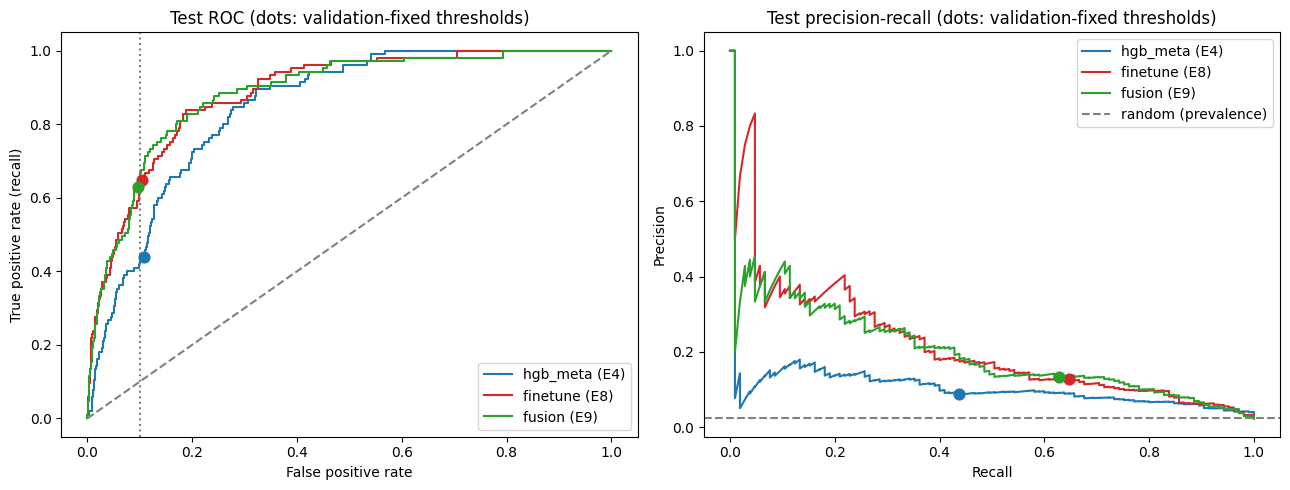

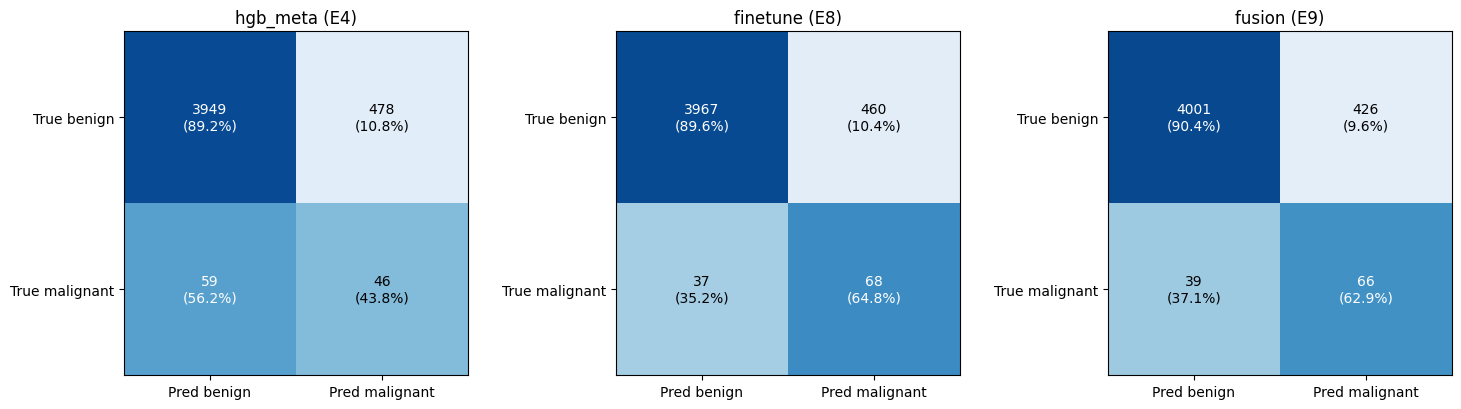


Deep (E8) minus traditional (E4): difference [95% paired patient-level bootstrap CI]
  ROC-AUC         +0.038 [+0.007, +0.068] <- excludes 0
  PR-AUC          +0.110 [+0.049, +0.182] <- excludes 0
  recall@val-thr  +0.210 [+0.082, +0.333] <- excludes 0

Fusion (E9) minus fine-tuned (E8): difference [95% paired patient-level bootstrap CI]
  ROC-AUC         +0.000 [-0.011, +0.010] 
  PR-AUC          -0.016 [-0.043, +0.013] 
  recall@val-thr  -0.019 [-0.094, +0.053] 


In [35]:
import joblib
from sklearn.metrics import roc_curve, precision_recall_curve

yte = test_df["target"].values
gte = test_df["patient_id"].values
thr = json.load(open(f"{BASE_DIR}/thresholds.json"))

# Load models and score the test set (each model scored once)
cols = json.load(open(f"{MODEL_DIR}/best_traditional_feature_columns.json"))["order"]
feats = pd.read_parquet(f"{FEAT_DIR}/handcrafted_features.parquet")
full = feats.merge(meta_feats[["isic_id"] + feature_cols], on="isic_id")
te = full[full["split"] == "test"]
assert (te["isic_id"].values == test_df["isic_id"].values).all() and (te["target"].values == yte).all()

hgb = joblib.load(f"{MODEL_DIR}/best_traditional_hgb_meta.joblib")
m8 = tf.keras.models.load_model(f"{MODEL_DIR}/e8_effnetb0_finetuned.keras", compile=False)
m9 = tf.keras.models.load_model(f"{MODEL_DIR}/e9_fusion.keras", compile=False)

test = {"hgb_meta (E4)": hgb.predict_proba(te[cols])[:, 1],
        "finetune (E8)": m8.predict(make_dataset(test_df), verbose=0).ravel(),
        "fusion (E9)": m9.predict(make_dataset(test_df, use_meta=True), verbose=0).ravel()}
for k, v in test.items():
    assert v.shape[0] == yte.shape[0], k
print(f"Test set: {len(yte)} images, {int(yte.sum())} malignant ({yte.mean() * 100:.2f}%), "
      f"{len(np.unique(gte))} patients")

# Metrics at the validation-fixed thresholds, with patient-level bootstrap CIs
tags = {"hgb_meta (E4)": ("T-E4", "HGB-test", "traditional"),
        "finetune (E8)": ("T-E8", "EffNetB0-finetune-test", "deep"),
        "fusion (E9)": ("T-E9", "EffNetB0-fusion-test", "deep")}
fmt = lambda v, ci: f"{v:.3f} ({ci[0]:.3f}-{ci[1]:.3f})"
rows, cms = [], {}
for name, s in test.items():
    t = thr[name]["threshold"]
    m = compute_metrics(yte, s, thr=t)
    ci = patient_bootstrap(yte, s, gte, thr=t)
    flag = s > t
    tp = int((flag & (yte == 1)).sum()); fp = int((flag & (yte == 0)).sum())
    fn = int((~flag & (yte == 1)).sum()); tn = int((~flag & (yte == 0)).sum())
    cms[name] = np.array([[tn, fp], [fn, tp]])
    ref = compute_metrics(yte, s)                 # reference only: threshold from test labels
    rows.append({"model": name,
                 "ROC-AUC": fmt(m["roc_auc"], ci["roc_auc"]),
                 "PR-AUC": fmt(m["pr_auc"], ci["pr_auc"]),
                 "recall@val-thr": fmt(m["recall_at_spec"], ci["recall_at_spec"]),
                 "specificity": round(m["specificity"], 3),
                 "precision": round(tp / max(tp + fp, 1), 3),
                 "TP": tp, "FP": fp, "FN": fn, "TN": tn,
                 "ref: recall@90spec": round(ref["recall_at_spec"], 3)})
    exp, nm, fam = tags[name]
    log_result(exp, nm, fam, {"threshold_from": "validation (90% specificity)", "threshold": t},
               "test", m, ci, "One-time test evaluation, validation-fixed threshold")
    np.save(f"{FEAT_DIR}/test_scores_{exp}.npy", s)
print("\n" + pd.DataFrame(rows).set_index("model").T.to_string())

# ROC and precision-recall curves
colors = {"hgb_meta (E4)": "tab:blue", "finetune (E8)": "tab:red", "fusion (E9)": "tab:green"}
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for name, s in test.items():
    fpr, tpr, _ = roc_curve(yte, s)
    pr_, rc_, _ = precision_recall_curve(yte, s)
    flag = s > thr[name]["threshold"]
    op_fpr, op_tpr = flag[yte == 0].mean(), flag[yte == 1].mean()
    op_prec = yte[flag].mean()
    ax[0].plot(fpr, tpr, color=colors[name], label=name)
    ax[0].scatter([op_fpr], [op_tpr], color=colors[name], marker="o", s=60, zorder=3)
    ax[1].plot(rc_, pr_, color=colors[name], label=name)
    ax[1].scatter([op_tpr], [op_prec], color=colors[name], marker="o", s=60, zorder=3)
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].axvline(0.10, ls=":", color="gray")
ax[0].set_title("Test ROC (dots: validation-fixed thresholds)")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (recall)"); ax[0].legend()
ax[1].axhline(yte.mean(), ls="--", color="gray", label="random (prevalence)")
ax[1].set_title("Test precision-recall (dots: validation-fixed thresholds)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend()
plt.tight_layout(); plt.show()

# Confusion matrices at the validation-fixed thresholds
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (name, cm) in zip(ax, cms.items()):
    a.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum() * 100:.1f}%)", ha="center", va="center",
                   color="white" if cm[i, j] / cm[i].sum() > 0.5 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["Pred benign", "Pred malignant"])
    a.set_yticks([0, 1]); a.set_yticklabels(["True benign", "True malignant"])
    a.set_title(name)
plt.tight_layout(); plt.show()

# Paired patient-level bootstrap comparisons between models
def paired_boot(y, sa, sb, groups, ta, tb, n_boot=500, seed=SEED):
    y, sa, sb, groups = map(np.asarray, (y, sa, sb, groups))
    rng = np.random.default_rng(seed)
    by_pat = [np.where(groups == g)[0] for g in np.unique(groups)]
    def mets(yy, ss, t):
        mm = compute_metrics(yy, ss, thr=t)
        return np.array([mm["roc_auc"], mm["pr_auc"], mm["recall_at_spec"]])
    obs = mets(y, sa, ta) - mets(y, sb, tb)
    diffs = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(by_pat), len(by_pat))
        idx = np.concatenate([by_pat[i] for i in pick])
        if y[idx].sum() == 0:
            continue
        diffs.append(mets(y[idx], sa[idx], ta) - mets(y[idx], sb[idx], tb))
    lo, hi = np.percentile(np.array(diffs), [2.5, 97.5], axis=0)
    return obs, lo, hi

for a_name, b_name, label in [("finetune (E8)", "hgb_meta (E4)", "Deep (E8) minus traditional (E4)"),
                              ("fusion (E9)", "finetune (E8)", "Fusion (E9) minus fine-tuned (E8)")]:
    obs, lo, hi = paired_boot(yte, test[a_name], test[b_name], gte,
                              thr[a_name]["threshold"], thr[b_name]["threshold"])
    print(f"\n{label}: difference [95% paired patient-level bootstrap CI]")
    for k, nm in enumerate(["ROC-AUC", "PR-AUC", "recall@val-thr"]):
        print(f"  {nm:15s} {obs[k]:+.3f} [{lo[k]:+.3f}, {hi[k]:+.3f}]",
              "<- excludes 0" if lo[k] > 0 or hi[k] < 0 else "")

### 13.4 Test-set results

On the held-out test set (4,532 images, 294 patients, 105 malignant), the fine-tuned EfficientNetB0 (Experiment 8) reached a ROC-AUC of 0.886 (95% patient-level bootstrap CI 0.845 to 0.920), a PR-AUC of 0.219 (0.160 to 0.301) and a recall of 0.648 (0.550 to 0.752) at the validation-fixed threshold, with a specificity of 0.896. The fusion model (Experiment 9) gave 0.886, 0.203 and 0.629 (specificity 0.904), and the Gradient Boosting model on handcrafted and metadata features (Experiment 4) gave 0.848, 0.109 and 0.438 (specificity 0.892). The thresholds, which were set on the validation set to give 90% specificity, transferred well to the test set despite its higher prevalence (2.3% against 1.5%): all three specificities were between 0.89 and 0.90, and the recall at the fixed threshold differed from the recall at a threshold chosen on the test labels by at most 0.04.

All models scored lower on the test set than on validation (for the fine-tuned network, ROC-AUC fell from 0.908 to 0.886, PR-AUC from 0.279 to 0.219 and recall from 0.708 to 0.648; for Gradient Boosting, ROC-AUC fell from 0.876 to 0.848 and recall from 0.583 to 0.438). This is the expected optimism of validation scores after epochs and hyperparameters were selected on that set, and with only 72 validation positives; PR-AUC fell even though the test prevalence is higher, so the decline is not an effect of prevalence. Paired patient-level bootstrap comparisons on the test set showed that the fine-tuned network outperformed Gradient Boosting in ROC-AUC (+0.038, 95% CI +0.007 to +0.068), PR-AUC (+0.110, +0.049 to +0.182) and recall (+0.210, +0.082 to +0.333), with all intervals excluding zero, although the lower bound for ROC-AUC is close to zero. The fusion model did not differ from the image-only network (ROC-AUC 0.000, -0.011 to +0.010; PR-AUC -0.016, -0.043 to +0.013; recall -0.019, -0.094 to +0.053), which confirms on independent data the validation finding that clinical metadata adds no measurable benefit once the image network is fine-tuned.

The confusion matrices show the clinical trade-off of the chosen operating point. The fine-tuned network detected 68 of the 105 melanomas (64.8%) and missed 37, while flagging 460 of 4,427 benign lesions (10.4%); its precision of 12.9% corresponds to about 7.8 flagged lesions for every melanoma found, compared with 11.4 for Gradient Boosting (46 of 524 flagged lesions malignant). The ROC curves of the two neural models almost coincide and lie above that of Gradient Boosting at all false-positive rates, and in the precision-recall plot both lead below a recall of about 0.8. Missing about a third of melanomas at 90% specificity is too many for a stand-alone screening tool, so these models are suitable only as decision support, with the threshold adjustable towards higher sensitivity at the cost of more false alarms. The intervals remain wide because the test set holds only 105 malignant images.

### 13.5 Error analysis and calibration

The fine-tuned EfficientNetB0 (Experiment 8) is examined on the test set at its validation-fixed threshold, to understand where its errors come from and whether they differ from those of the Gradient Boosting model.

**What the code does:**

1. Builds a table of every test image with its score, outcome (true positive, false negative, false positive, true negative), age, sex, lesion site, original diagnosis label and segmentation flag. The diagnosis label is used only to describe errors and never as a model input.

2. Reports recall by age group, lesion site and sex for the 105 malignant images (for both the neural network and Gradient Boosting), and the false-positive rate for each benign diagnosis.

3. Checks whether segmentation failures are more common among missed melanomas, and computes patient-level detection: the share of patients with a melanoma for whom at least one malignant image was flagged.

4. Plots the score distributions of benign and malignant images with the threshold, and reliability (calibration) curves with Brier scores for both models.

5. Displays the missed melanomas with the lowest scores, the benign lesions with the highest scores, and a random sample of detected melanomas for visual comparison.

**Caution:** with 105 malignant images, subgroup counts are small, so the patterns below are descriptive and hypothesis-generating, not statistical findings. The analysis informs the discussion and future work. It is not used to change any model or threshold.

Outcomes (E8): {'TN': 3967, 'FP': 460, 'TP': 68, 'FN': 37}

Recall of malignant images by age group:
           malignant  caught_E8  recall_E8  recall_HGB
age_group                                             
(0, 40]           14         12       0.86        0.29
(40, 50]          17          7       0.41        0.29
(50, 60]          26         19       0.73        0.42
(60, 70]          27         16       0.59        0.37
(70, 100]         21         14       0.67        0.76

Recall of malignant images by lesion site:
                 malignant  caught_E8  recall_E8  recall_HGB
site                                                        
head/neck               20         16       0.80        0.30
lower extremity         23         10       0.43        0.43
oral/genital             2          2       1.00        0.00
palms/soles              2          1       0.50        0.50
torso                   40         30       0.75        0.50
unknown                  3          1      

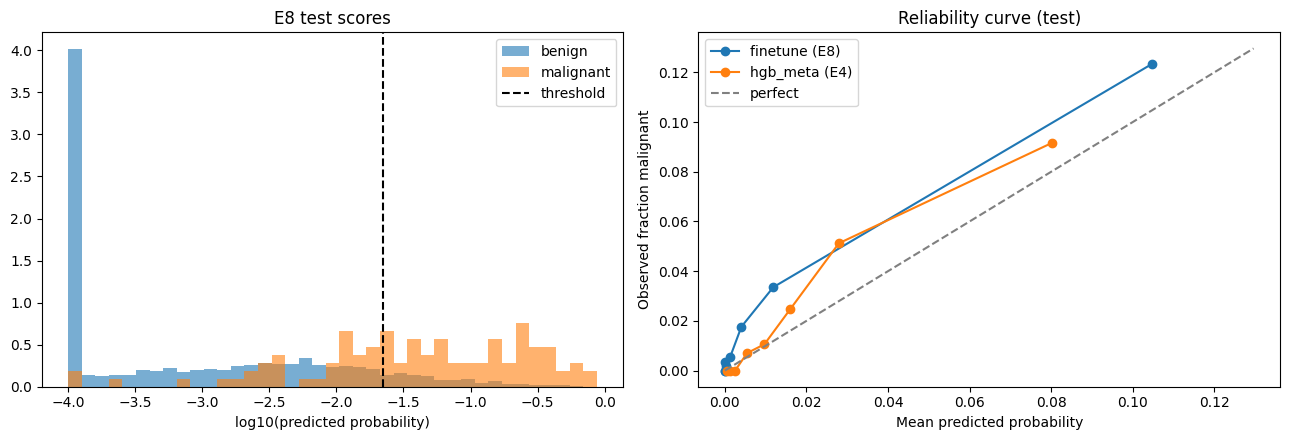


Brier score: {'finetune (E8)': np.float64(0.0205), 'hgb_meta (E4)': np.float64(0.0217)} | no-skill (constant prevalence): 0.0226


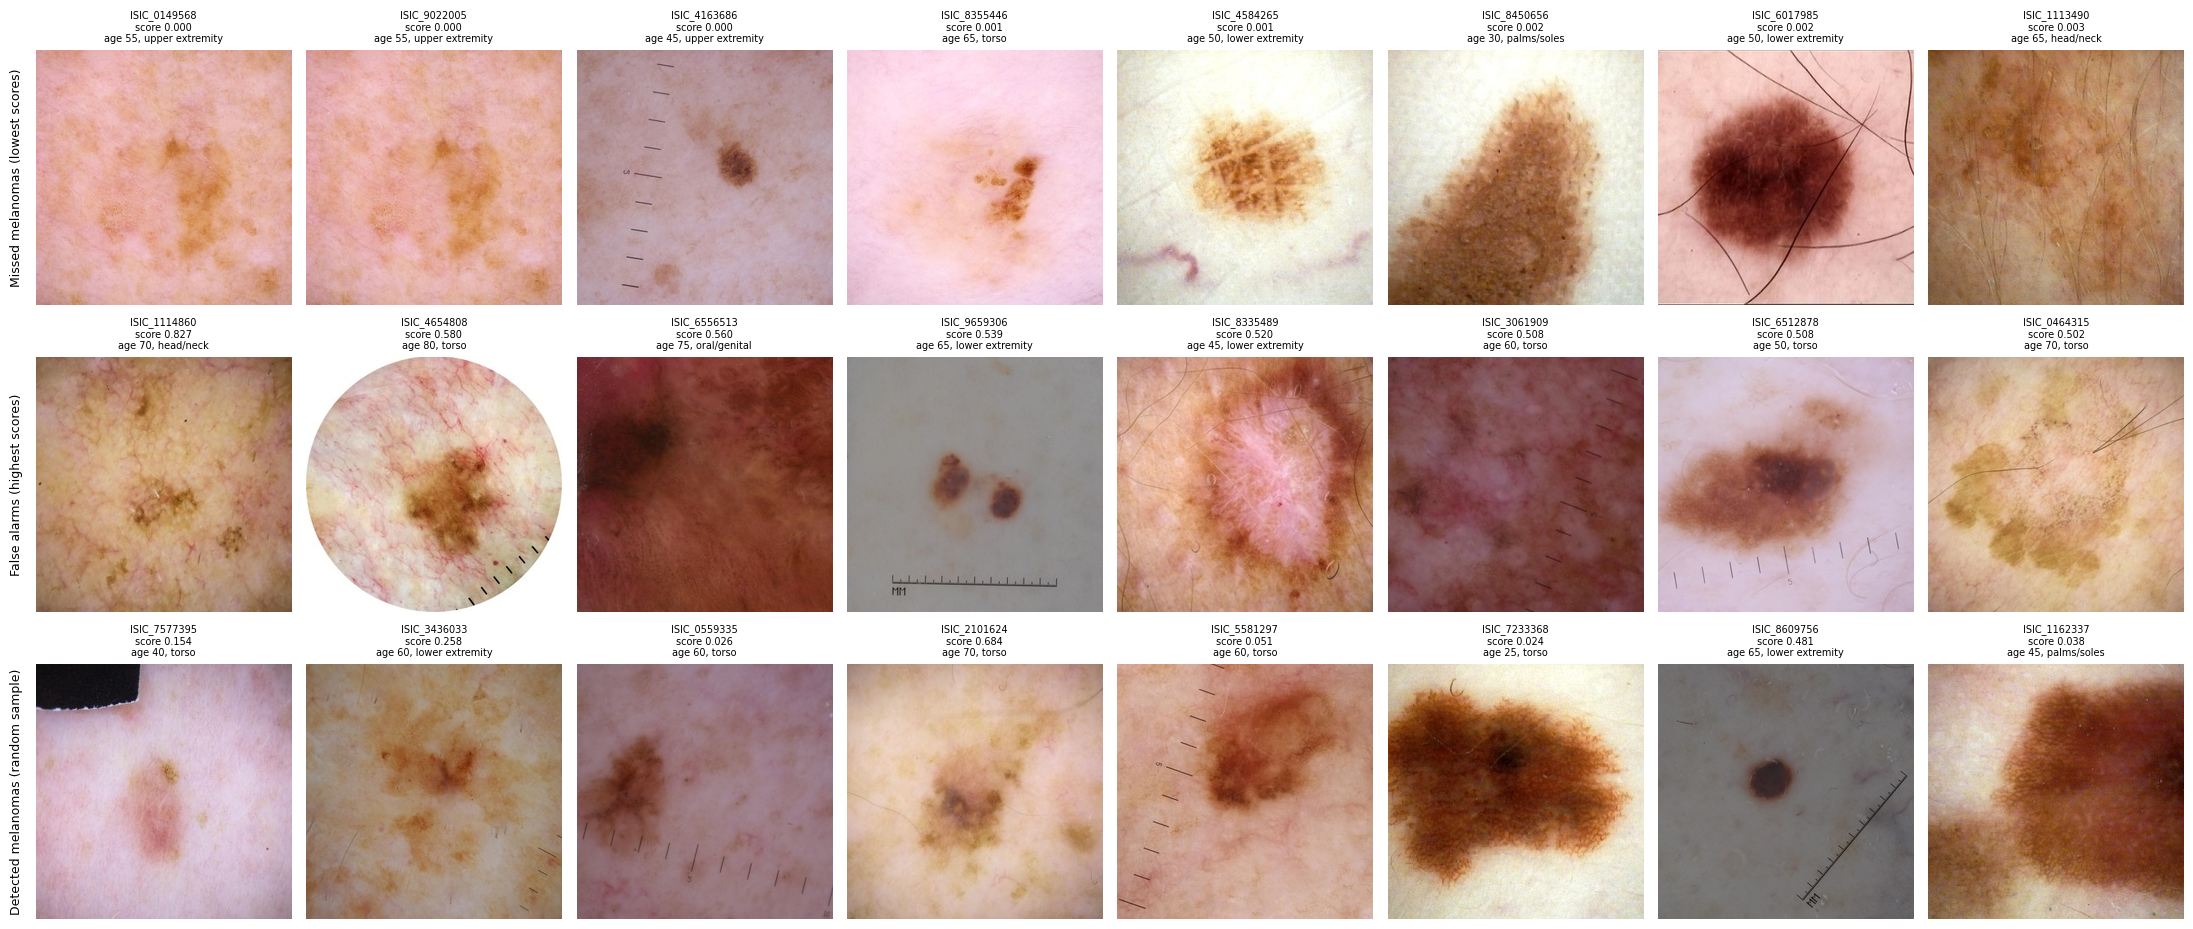

In [36]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from PIL import Image

thr = json.load(open(f"{BASE_DIR}/thresholds.json"))
t8, t4 = thr["finetune (E8)"]["threshold"], thr["hgb_meta (E4)"]["threshold"]
s8 = np.load(f"{FEAT_DIR}/test_scores_T-E8.npy")
s4 = np.load(f"{FEAT_DIR}/test_scores_T-E4.npy")

seg = pd.read_parquet(f"{FEAT_DIR}/handcrafted_features.parquet")[["isic_id", "seg_ok"]]
cols_keep = ["isic_id", "patient_id", "target", "age_approx", "sex", "anatom_site_general_challenge", "diagnosis"]
err = test_df[cols_keep].reset_index(drop=True).merge(seg, on="isic_id", how="left")
assert err["isic_id"].values.tolist() == test_df["isic_id"].values.tolist() and len(err) == len(s8)
err["site"] = err["anatom_site_general_challenge"].fillna("unknown")
err["score"], err["flag"], err["flag_hgb"] = s8, s8 > t8, s4 > t4
err["outcome"] = np.select([(err.flag) & (err.target == 1), (~err.flag) & (err.target == 1),
                            (err.flag) & (err.target == 0)], ["TP", "FN", "FP"], default="TN")
print("Outcomes (E8):", err["outcome"].value_counts().to_dict())

mal, ben = err[err.target == 1].copy(), err[err.target == 0]
mal["age_group"] = pd.cut(mal["age_approx"], [0, 40, 50, 60, 70, 100])

def recall_table(col):
    g = mal.groupby(col, observed=True)
    return pd.DataFrame({"malignant": g.size(), "caught_E8": g["flag"].sum(),
                         "recall_E8": g["flag"].mean().round(2),
                         "recall_HGB": g["flag_hgb"].mean().round(2)})
for col, title in [("age_group", "age group"), ("site", "lesion site"), ("sex", "sex")]:
    print(f"\nRecall of malignant images by {title}:")
    print(recall_table(col).to_string())

g = ben.groupby("diagnosis")
fpr_tab = pd.DataFrame({"benign": g.size(), "flagged_E8": g["flag"].sum(),
                        "flag_rate": g["flag"].mean().round(3)}).sort_values("benign", ascending=False)
print("\nFalse-positive rate by benign diagnosis (E8):")
print(fpr_tab.to_string())

print("\nShare of images using the segmentation fallback (seg_ok = 0), by outcome:")
print(err.groupby("outcome")["seg_ok"].apply(lambda s: round((s == 0).mean(), 3)).to_string())
print("\nMedian score by outcome (threshold = %.4f):" % t8)
print(err.groupby("outcome")["score"].median().round(4).to_string())

pm = mal.groupby("patient_id")["flag"].agg(["size", "sum"])
print(f"\nPatient-level detection (E8): {int((pm['sum'] > 0).sum())} of {len(pm)} patients with a "
      f"melanoma had at least one malignant image flagged ({(pm['sum'] > 0).mean() * 100:.1f}%)")
print("Missed melanoma images (FN):", int((mal.flag == False).sum()),
      "| of which from patients detected through another image:",
      int(mal[(~mal.flag) & (mal.patient_id.isin(pm.index[pm['sum'] > 0]))].shape[0]))

# Score distributions and calibration
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.linspace(np.log10(max(s8.min(), 1e-4)), np.log10(s8.max()), 40)
ax[0].hist(np.log10(np.clip(s8[err.target == 0], 1e-4, 1)), bins=bins, alpha=0.6, density=True, label="benign")
ax[0].hist(np.log10(np.clip(s8[err.target == 1], 1e-4, 1)), bins=bins, alpha=0.6, density=True, label="malignant")
ax[0].axvline(np.log10(t8), color="k", ls="--", label="threshold")
ax[0].set_title("E8 test scores"); ax[0].set_xlabel("log10(predicted probability)"); ax[0].legend()

brier = {}
for name, s in [("finetune (E8)", s8), ("hgb_meta (E4)", s4)]:
    pt, pp = calibration_curve(err.target, s, n_bins=8, strategy="quantile")
    ax[1].plot(pp, pt, marker="o", label=name)
    brier[name] = brier_score_loss(err.target, s)
    print(f"\nCalibration {name} (8 quantile bins): mean predicted {s.mean():.4f} | observed {err.target.mean():.4f}")
    print(pd.DataFrame({"predicted": pp.round(4), "observed": pt.round(4)}).T.to_string())
m_ = max(ax[1].get_xlim()[1], ax[1].get_ylim()[1])
ax[1].plot([0, m_], [0, m_], "--", color="gray", label="perfect")
ax[1].set_title("Reliability curve (test)"); ax[1].set_xlabel("Mean predicted probability")
ax[1].set_ylabel("Observed fraction malignant"); ax[1].legend()
plt.tight_layout(); plt.show()
base = err.target.mean() * (1 - err.target.mean())
print("\nBrier score:", {k: round(v, 4) for k, v in brier.items()}, "| no-skill (constant prevalence):", round(base, 4))

# Example images
def fmt_age(a):
    return "age ?" if pd.isna(a) else f"age {int(a)}"

groups = [("Missed melanomas (lowest scores)", err[err.outcome == "FN"].nsmallest(8, "score")),
          ("False alarms (highest scores)", err[err.outcome == "FP"].nlargest(8, "score")),
          ("Detected melanomas (random sample)", err[err.outcome == "TP"].sample(8, random_state=SEED))]
fig, axes = plt.subplots(3, 8, figsize=(22, 9.5))
for r, (title, d) in enumerate(groups):
    for c in range(8):
        a = axes[r, c]; a.axis("off")
        if c < len(d):
            row = d.iloc[c]
            a.imshow(Image.open(f"{img_dir}/{row['isic_id']}.jpg"))
            a.set_title(f"{row['isic_id']}\nscore {row['score']:.3f}\n{fmt_age(row['age_approx'])}, {row['site']}",
                        fontsize=7)
    axes[r, 0].text(-0.05, 0.5, title, transform=axes[r, 0].transAxes, rotation=90,
                    va="center", ha="right", fontsize=9)
plt.tight_layout(); plt.show()

### 13.6 Results and interpretation: error analysis and calibration

**What the results show**

- **Overall outcome (E8 on test):** 68 true positives, 37 false negatives, 459 false positives, 3,967 true negatives. At the validation-fixed threshold (0.0224), E8 finds 68 of 105 melanomas (65%) and flags about 10% of benign images.

- **Subgroups:** E8 has higher recall than HGB in most age and site groups. Examples: age ≤40 (0.86 vs 0.29), head/neck (0.80 vs 0.30), torso (0.75 vs 0.50). Recall is lowest for the lower extremity (10/23) and ages 40–50 (7/17). Every subgroup holds few melanomas (2 to 67), so these differences are indicative only and are not statistically tested.

- **False alarms:** Benign images that look like melanoma are flagged most often: seborrheic keratosis (12 of 25), lichenoid keratosis (8 of 12) and solar lentigo (3 of 3). Nevi are flagged 12.5% of the time (85 of 682). Images with no recorded diagnosis, mostly ordinary benign lesions, are flagged 9.4% of the time (348 of 3,697).

- **Segmentation fallback:** The share of fallback segmentations is similar across outcomes (FN 13.5%, FP 12.0%, TN 15.1%, TP 11.8%). The misses are therefore not explained by failed segmentation. The CNN does not use the segmentation anyway.

- **Scores:** Median score is 0.0104 for missed melanomas and 0.134 for detected ones. Many missed melanomas score near zero, so they are confidently wrong, not borderline.

- **Patient level:** At least one lesion is flagged for 50 of 73 melanoma patients (68.5%). For 8 of the 37 missed images, another image of the same patient was detected.

- **Calibration:** The reliability curve lies below the diagonal. Mean predicted risk (0.0153) is below the observed rate (0.0232), so the model under-estimates risk on the test set, which has a higher melanoma share than training. The Brier score of E8 (0.0205) is only slightly below the no-skill value (0.0226), because the Brier score is dominated by the rare positive class.

**What the example images suggest (my own observations)**

- **Missed melanomas:** Most of the lowest-scoring missed melanomas are pale, faint or diffusely pigmented, or small. They lack the dark, high-contrast appearance the model seems to rely on, and their scores are close to zero. Two of the missed images appear to show the same lesion.

- **False alarms:** The highest-scoring false positives are mostly large, dark or heterogeneous benign lesions. Some contain artefacts such as rulers or a dark vignette, which may also have contributed to the high scores.

- **Detected melanomas:** The true positives are generally darker, better defined and more conspicuous than the missed ones.
**Implications**

- Ranking is useful but probabilities are not reliable out of the box. The threshold must be set on data resembling deployment, or the model recalibrated.

- Missed lesions are mostly pale or faint, and false alarms are mostly large, dark or irregular benign lesions. This is consistent with the model relying on visual conspicuousness.

- Subgroup counts are too small for firm conclusions. ISIC 2020 has no skin-tone labels, so fairness across skin types could not be tested (a limitation for the report).

## 14. Final results table

### 14.1 Collecting all experiments in one ordered table

Every experiment was logged to `results_table.csv` on Drive as it finished. This cell reloads that file, puts the experiments in running order (E1 to E9, then the three test-set rows), rounds the numbers and saves a clean copy as `results_table_clean.csv` and `results_table_clean.md`. Both files go into the GitHub repo and the report's results table. The cell does not retrain anything.

In [37]:
import pandas as pd, re, ast

P = '/content/drive/MyDrive/melanoma_project/'
res = pd.read_csv(P + 'results_table.csv')

def sort_key(x):
    x = str(x).upper()
    m = re.search(r'(\d+)', x)
    return (x.startswith('T-'), int(m.group(1)) if m else 99, x)

res = res.loc[sorted(res.index, key=lambda i: sort_key(res.loc[i, 'exp']))].reset_index(drop=True)

def clean_ci(s):
    s = re.sub(r'np\.float64\(([^)]*)\)', r'\1', str(s))
    lo, hi = ast.literal_eval(s)
    return f"{float(lo):.2f}–{float(hi):.2f}"

for c in ['roc_auc_ci', 'pr_auc_ci', 'recall_ci']:
    res[c] = res[c].apply(clean_ci)

num_cols = res.select_dtypes('number').columns
res[num_cols] = res[num_cols].round(3)

res.to_csv(P + 'results_table_clean.csv', index=False)
try:
    res.to_markdown(P + 'results_table_clean.md', index=False)
except ImportError:
    print("tabulate not installed, skipped .md copy")

pd.set_option('display.max_columns', None, 'display.width', 250, 'display.max_colwidth', 50)
display(res.drop(columns=['settings']))

,exp,model,family,split,roc_auc,pr_auc,recall@90spec,roc_auc_ci,pr_auc_ci,recall_ci,notes
0,E1,LogReg,traditional,val,0.849,0.101,0.556,0.80–0.89,0.06–0.19,0.41–0.65,"Baseline, no imbalance handling"
1,E2a,RandomForest,traditional,val,0.849,0.099,0.583,0.80–0.89,0.06–0.16,0.48–0.70,"Non-linear, no imbalance handling"
2,E2b,HistGradBoost,traditional,val,0.858,0.128,0.583,0.82–0.90,0.08–0.20,0.46–0.70,"Non-linear, no imbalance handling"
3,E3,HGB-none,traditional,val,0.858,0.128,0.583,0.82–0.90,0.08–0.20,0.46–0.70,Imbalance handling comparison (mean of 3 seeds...
4,E4,HGB+metadata,traditional,val,0.876,0.153,0.583,0.84–0.91,0.10–0.25,0.48–0.69,Handcrafted + clinical metadata
5,E5,CNN-baseline,deep,val,0.849,0.081,0.528,0.80–0.89,0.05–0.13,0.38–0.67,"From-scratch baseline, no imbalance handling"
6,E6A,CNN-cosine,deep,val,0.875,0.166,0.569,0.83–0.91,0.09–0.28,0.45–0.71,"Cosine LR, no class weights"
7,E7a,LogReg-EffNetB0-emb,traditional,val,0.869,0.126,0.583,0.82–0.91,0.08–0.20,0.45–0.72,Traditional model on frozen ImageNet features
8,E7b,Keras-head-EffNetB0-emb,deep,val,0.845,0.108,0.542,0.79–0.90,0.06–0.18,0.42–0.68,Neural head on frozen ImageNet features (seed ...
9,E8,EffNetB0-finetune,deep,val,0.908,0.279,0.708,0.87–0.94,0.19–0.40,0.61–0.81,"Two-phase fine-tuning, best epoch by val PR-AUC"


### 14.2 Results and interpretation: final results table

**What the table shows**

- **E1–E9 are validation results; the three `T-` rows are the one-time test evaluation** with thresholds fixed on validation. Recall is measured at 90% specificity. Intervals are patient-level bootstrap 95% CIs.

- **Traditional models:** ROC-AUC rises from 0.849 (E1) to 0.858 (E2b, gradient boosting) and 0.876 (E4, handcrafted features plus clinical metadata). Recall at 90% specificity stays at 0.56–0.58, and PR-AUC is low (0.10–0.15), against a prevalence of about 1.8%.

- **From-scratch CNN:** E5 (0.849 ROC-AUC) matches the simplest handcrafted models (E1, E2a) and is slightly below E2b. E6a (cosine schedule) improves to 0.875 ROC-AUC, about equal to E4 (0.876), with a higher PR-AUC (0.166 vs 0.153).

- **Transfer learning:** Frozen EfficientNetB0 embeddings (E7a 0.869, E7b 0.845) do not beat handcrafted features plus metadata (E4, 0.876). Fine-tuning (E8) is the clear jump: ROC-AUC 0.908, PR-AUC 0.279, recall 0.708.

- **Metadata fusion (E9)** gives nearly the same validation result as E8 (0.904, 0.295, 0.708), so metadata added little once the image model was fine-tuned.

- **Test set:** Both finalists lose performance relative to validation. HGB+metadata recall falls from 0.583 to 0.438, and E8 recall falls from 0.708 to 0.648. On test, E8 is slightly ahead of E9 (recall 0.648 vs 0.629, PR-AUC 0.219 vs 0.203, ROC-AUC 0.886 for both), but the differences are small relative to the CIs. E8 stays ahead of HGB on every metric.

**How to read it**

- The validation CIs of the top models overlap heavily, and the validation set has few melanomas. Small differences between E8 and E9, or between E4, E6a and E7a, should not be presented as real.

- The drop from validation to test shows the validation estimates were optimistic, partly because model selection and thresholds were tuned on validation.

- The E3 row shows only the no-imbalance-handling setting, with the same numbers as E2b. The comparison of class weights, oversampling and undersampling is in the E3 output above, and the report should refer to that.

### 14.3 Recording the environment (requirements.txt)

This cell writes `requirements.txt` with the exact versions of the packages the notebook uses, read from the running Colab session. Anyone reproducing the project can install the same versions with `pip install -r requirements.txt`. The file is saved to Drive and to the Colab files panel, and is added to the GitHub repo.

In [38]:
from importlib import metadata
import sys

pkgs = ["numpy", "pandas", "scipy", "scikit-learn", "tensorflow", "opencv-python",
        "scikit-image", "matplotlib", "seaborn", "pyarrow", "joblib", "kagglehub",
        "wandb", "tabulate"]

lines = []
for p in pkgs:
    try:
        lines.append(f"{p}=={metadata.version(p)}")
    except metadata.PackageNotFoundError:
        print("not installed, skipped:", p)

text = "\n".join(lines) + "\n"
open("/content/requirements.txt", "w").write(text)
open("/content/drive/MyDrive/melanoma_project/requirements.txt", "w").write(text)

print("Python", sys.version.split()[0])
print(text)

Python 3.13.15
numpy==2.1.3
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
tensorflow==2.21.0
opencv-python==5.0.0.93
scikit-image==0.25.2
matplotlib==3.10.0
seaborn==0.13.2
pyarrow==23.0.1
joblib==1.6.0
kagglehub==1.0.2
wandb==0.28.1
tabulate==0.9.0



In [1]:
import os, zipfile, kagglehub
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/melanoma_project'
img_dir = kagglehub.dataset_download('nischaydnk/isic-2020-jpg-256x256-resized')
print('Images found at:', img_dir)

out = f'{BASE}/isic2020_raw_images_and_train_csv.zip'
with zipfile.ZipFile(out, 'w', zipfile.ZIP_STORED) as z:
    z.write(f'{BASE}/train.csv', 'train.csv')
    n = 0
    for root, _, files in os.walk(img_dir):
        for f in files:
            full = os.path.join(root, f)
            z.write(full, os.path.relpath(full, img_dir))
            n += 1
print('Files zipped:', n)
print('Zip size (GB):', round(os.path.getsize(out) / 1e9, 2))

Mounted at /content/drive


100%|██████████| 595M/595M [00:35<00:00, 17.7MB/s]

Extracting files...


Images found at: /root/.cache/kagglehub/datasets/nischaydnk/isic-2020-jpg-256x256-resized/versions/1
Files zipped: 33128
Zip size (GB): 0.63
